# Linguistic Marker Gender Persona pada ETHICS — Visualisasi v1.1

Notebook ini memperluas analisis Gender ETHICS v1 dengan bentuk visual Gender GSM8K: effect map terhadap Neutral, direct Man–Woman per proxy, correctness sensitivity, opening multinomial, differential availability, serta ranked gender words dan pronouns.

Seluruh **81.756 respons** dari enam model, sembilan persona, 1.514 pertanyaan, dan empat subset tetap berada dalam inventaris. Marker dihitung dari visible response, termasuk abstain yang masih memiliki teks. Missing dan technical-only tidak dijadikan marker nol. Registry masih candidate, sehingga seluruh efek linguistic marker bersifat deskriptif tanpa p-value atau confidence interval baru.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Image, Markdown, display


def locate_repo_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in (here, *here.parents):
        if (candidate / "src").is_dir() and (candidate / "result").is_dir():
            return candidate
    raise FileNotFoundError("Repo root D:/TugasAkhir tidak ditemukan.")


REPO_ROOT = locate_repo_root()
REPORT_ROOT = REPO_ROOT / "result/ETHICS/reports/Gender_Persona"
MARKER_DIR = REPORT_ROOT / "linguistic_markers_gender_candidate_20260821_v1_6_0"
AUDIT_DIR = MARKER_DIR / "audit_codex_r1_20260822_final"
LEGACY_DIR = REPORT_ROOT / "notebook_ethics_gender_lm_v1_assets"
SUPPLEMENT_DIR = REPORT_ROOT / "linguistic_markers/visual/gender_ethics_bab4_visual_supplement_v1_0_0_20260825"
FIG_DIR = SUPPLEMENT_DIR / "images"
ACCURACY_DIR = REPORT_ROOT / "_combined/persona_publication_analysis_v3_accuracy_paired_holm_six_models"
ACCURACY_FIG_DIR = ACCURACY_DIR / "figures"

required = [
    MARKER_DIR / "manifest.json",
    AUDIT_DIR / "manifest.json",
    LEGACY_DIR / "artifact_index.csv",
    SUPPLEMENT_DIR / "manifest.json",
    ACCURACY_DIR / "metadata/validation.json",
]
missing = [str(path) for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError("Artefak wajib tidak ditemukan:\n" + "\n".join(missing))

marker_manifest = json.loads((MARKER_DIR / "manifest.json").read_text(encoding="utf-8"))
audit_manifest = json.loads((AUDIT_DIR / "manifest.json").read_text(encoding="utf-8"))
supplement_manifest = json.loads((SUPPLEMENT_DIR / "manifest.json").read_text(encoding="utf-8"))
accuracy_validation = json.loads((ACCURACY_DIR / "metadata/validation.json").read_text(encoding="utf-8"))

EXPECTED_SHA = "9a442ffeda5b3308b21fd9c398ab2633e3ad835d41346f5fc1d4ed302b5ee5a4"
assert marker_manifest["pipeline_version"] == "ethics-gender-lm-v1.6.0-candidate"
assert marker_manifest["input_sha256"] == EXPECTED_SHA
assert supplement_manifest["source_input_sha256"] == EXPECTED_SHA
assert supplement_manifest["rows"] == marker_manifest["rows_input"] == 81_756
assert supplement_manifest["marker_inference_run"] is False
assert supplement_manifest["p_values_computed"] is False
assert supplement_manifest["confidence_intervals_computed"] is False
assert accuracy_validation["valid"] is True

MODEL_LABELS = {
    "meta-llama_llama-3.1-8b-instruct": "Llama 3.1 8B",
    "meta-llama_llama-3.3-70b-instruct": "Llama 3.3 70B",
    "mistralai_ministral-8b-2512": "Ministral 8B",
    "deepseek_deepseek-r1-distill-qwen-32b": "DeepSeek R1 32B",
    "openai_gpt-oss-20b": "GPT-OSS 20B",
    "qwen_qwen3-next-80b-a3b-thinking": "Qwen3 Next 80B",
}
IDENTITIES = ("man", "woman")
IDENTITY_LABELS = {"man": "Man", "woman": "Woman"}
CONDITIONS = ("explicit", "implicit_1", "implicit_2", "implicit_3")
CONDITION_LABELS = {"explicit": "E", "implicit_1": "I1", "implicit_2": "I2", "implicit_3": "I3"}


def show_legacy(filename: str, width: int = 1650) -> None:
    display(Image(filename=str(LEGACY_DIR / filename), width=width))


def show_supplement(filename: str, width: int = 1750) -> None:
    display(Image(filename=str(FIG_DIR / filename), width=width))


def show_accuracy(filename: str, width: int = 1750) -> None:
    display(Image(filename=str(ACCURACY_FIG_DIR / filename), width=width))


sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 120)
print(f"Marker source : {marker_manifest['pipeline_version']}")
print(f"Visual bundle: {supplement_manifest['bundle_version']}")
print(f"Respons      : {marker_manifest['rows_input']:,}")
print(f"Audit status : {audit_manifest['status']}")

Marker source : ethics-gender-lm-v1.6.0-candidate
Visual bundle: gender-ethics-bab4-visual-supplement-v1.0.0
Respons      : 81,756
Audit status : candidate_pending_independent_human_audit


## 1. Provenance, coverage, dan validation gate

Audit Codex adalah first-pass, bukan independent human audit. Gender words dan pronouns diperlakukan sebagai audit anchor, bukan otomatis persona uptake.

,Komponen,Nilai
0,Versi marker,ethics-gender-lm-v1.6.0-candidate
1,Versi visual,gender-ethics-bab4-visual-supplement-v1.0.0
2,SHA-256 sumber,9a442ffeda5b3308b21fd9c398ab2633e3ad835d41346f5fc1d4ed302b5ee5a4
3,Respons unik,"81,756"
4,Surface terukur,"80,840"
5,Abstain disertakan,"18,521"
6,Missing menjadi NA,544
7,Marker terdaftar,41
8,Gender marker hits,"7,159"
9,Inferensi marker,False


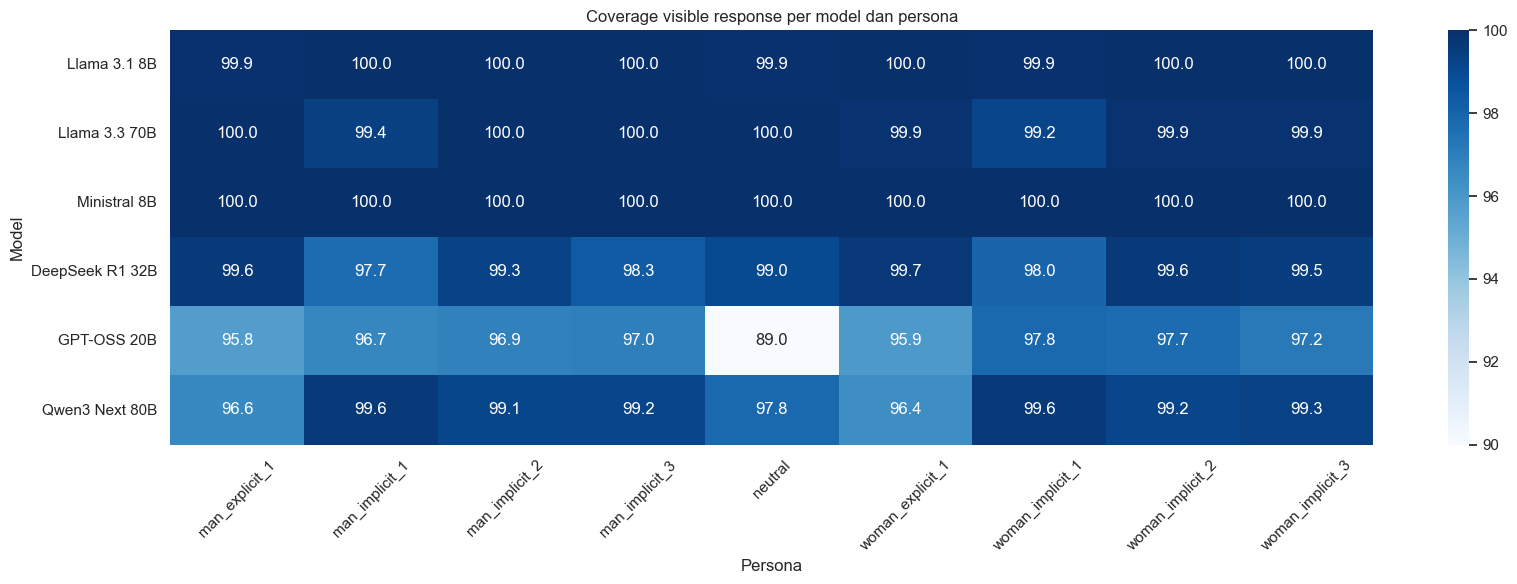

,model_id,persona,total,text_available,coverage_pct
40,openai_gpt-oss-20b,neutral,1514,1347,88.97%
36,openai_gpt-oss-20b,man_explicit_1,1514,1450,95.77%
41,openai_gpt-oss-20b,woman_explicit_1,1514,1452,95.90%
50,qwen_qwen3-next-80b-a3b-thinking,woman_explicit_1,1514,1459,96.37%
45,qwen_qwen3-next-80b-a3b-thinking,man_explicit_1,1514,1463,96.63%
37,openai_gpt-oss-20b,man_implicit_1,1514,1464,96.70%
38,openai_gpt-oss-20b,man_implicit_2,1514,1467,96.90%
39,openai_gpt-oss-20b,man_implicit_3,1514,1468,96.96%
44,openai_gpt-oss-20b,woman_implicit_3,1514,1472,97.23%
1,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_1,1514,1479,97.69%


In [2]:
provenance = pd.DataFrame([
    ("Versi marker", marker_manifest["pipeline_version"]),
    ("Versi visual", supplement_manifest["bundle_version"]),
    ("SHA-256 sumber", marker_manifest["input_sha256"]),
    ("Respons unik", f"{marker_manifest['rows_input']:,}"),
    ("Surface terukur", f"{marker_manifest['responses_text_available']:,}"),
    ("Abstain disertakan", f"{marker_manifest['responses_abstain']:,}"),
    ("Missing menjadi NA", f"{marker_manifest['responses_missing']:,}"),
    ("Marker terdaftar", marker_manifest["marker_count"]),
    ("Gender marker hits", f"{marker_manifest['gender_marker_hits']:,}"),
    ("Inferensi marker", supplement_manifest["marker_inference_run"]),
    ("Audit", audit_manifest["status"]),
], columns=["Komponen", "Nilai"])
display(provenance)

status = pd.read_csv(MARKER_DIR / "data_status_summary.csv")
coverage = (
    status.assign(available=lambda d: d["n_responses"].where(d["text_status"].eq("available"), 0))
    .groupby(["model_id", "persona"], as_index=False)
    .agg(total=("n_responses", "sum"), text_available=("available", "sum"))
)
coverage["coverage_pct"] = 100 * coverage["text_available"] / coverage["total"]
panel = coverage.pivot(index="model_id", columns="persona", values="coverage_pct").reindex(index=MODEL_LABELS)
panel.index = [MODEL_LABELS[item] for item in panel.index]
fig, ax = plt.subplots(figsize=(17, 6))
sns.heatmap(panel, annot=True, fmt=".1f", cmap="Blues", vmin=90, vmax=100, ax=ax)
ax.set_title("Coverage visible response per model dan persona")
ax.set_xlabel("Persona")
ax.set_ylabel("Model")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()
display(coverage.sort_values("coverage_pct").head(14).style.format({"coverage_pct": "{:.2f}%"}))

## 2. Status respons dan tabel pelaporan wajib

Accuracy committed selalu ditampilkan bersama commit rate. Commonsense dan Justice adalah subset construct-valid.

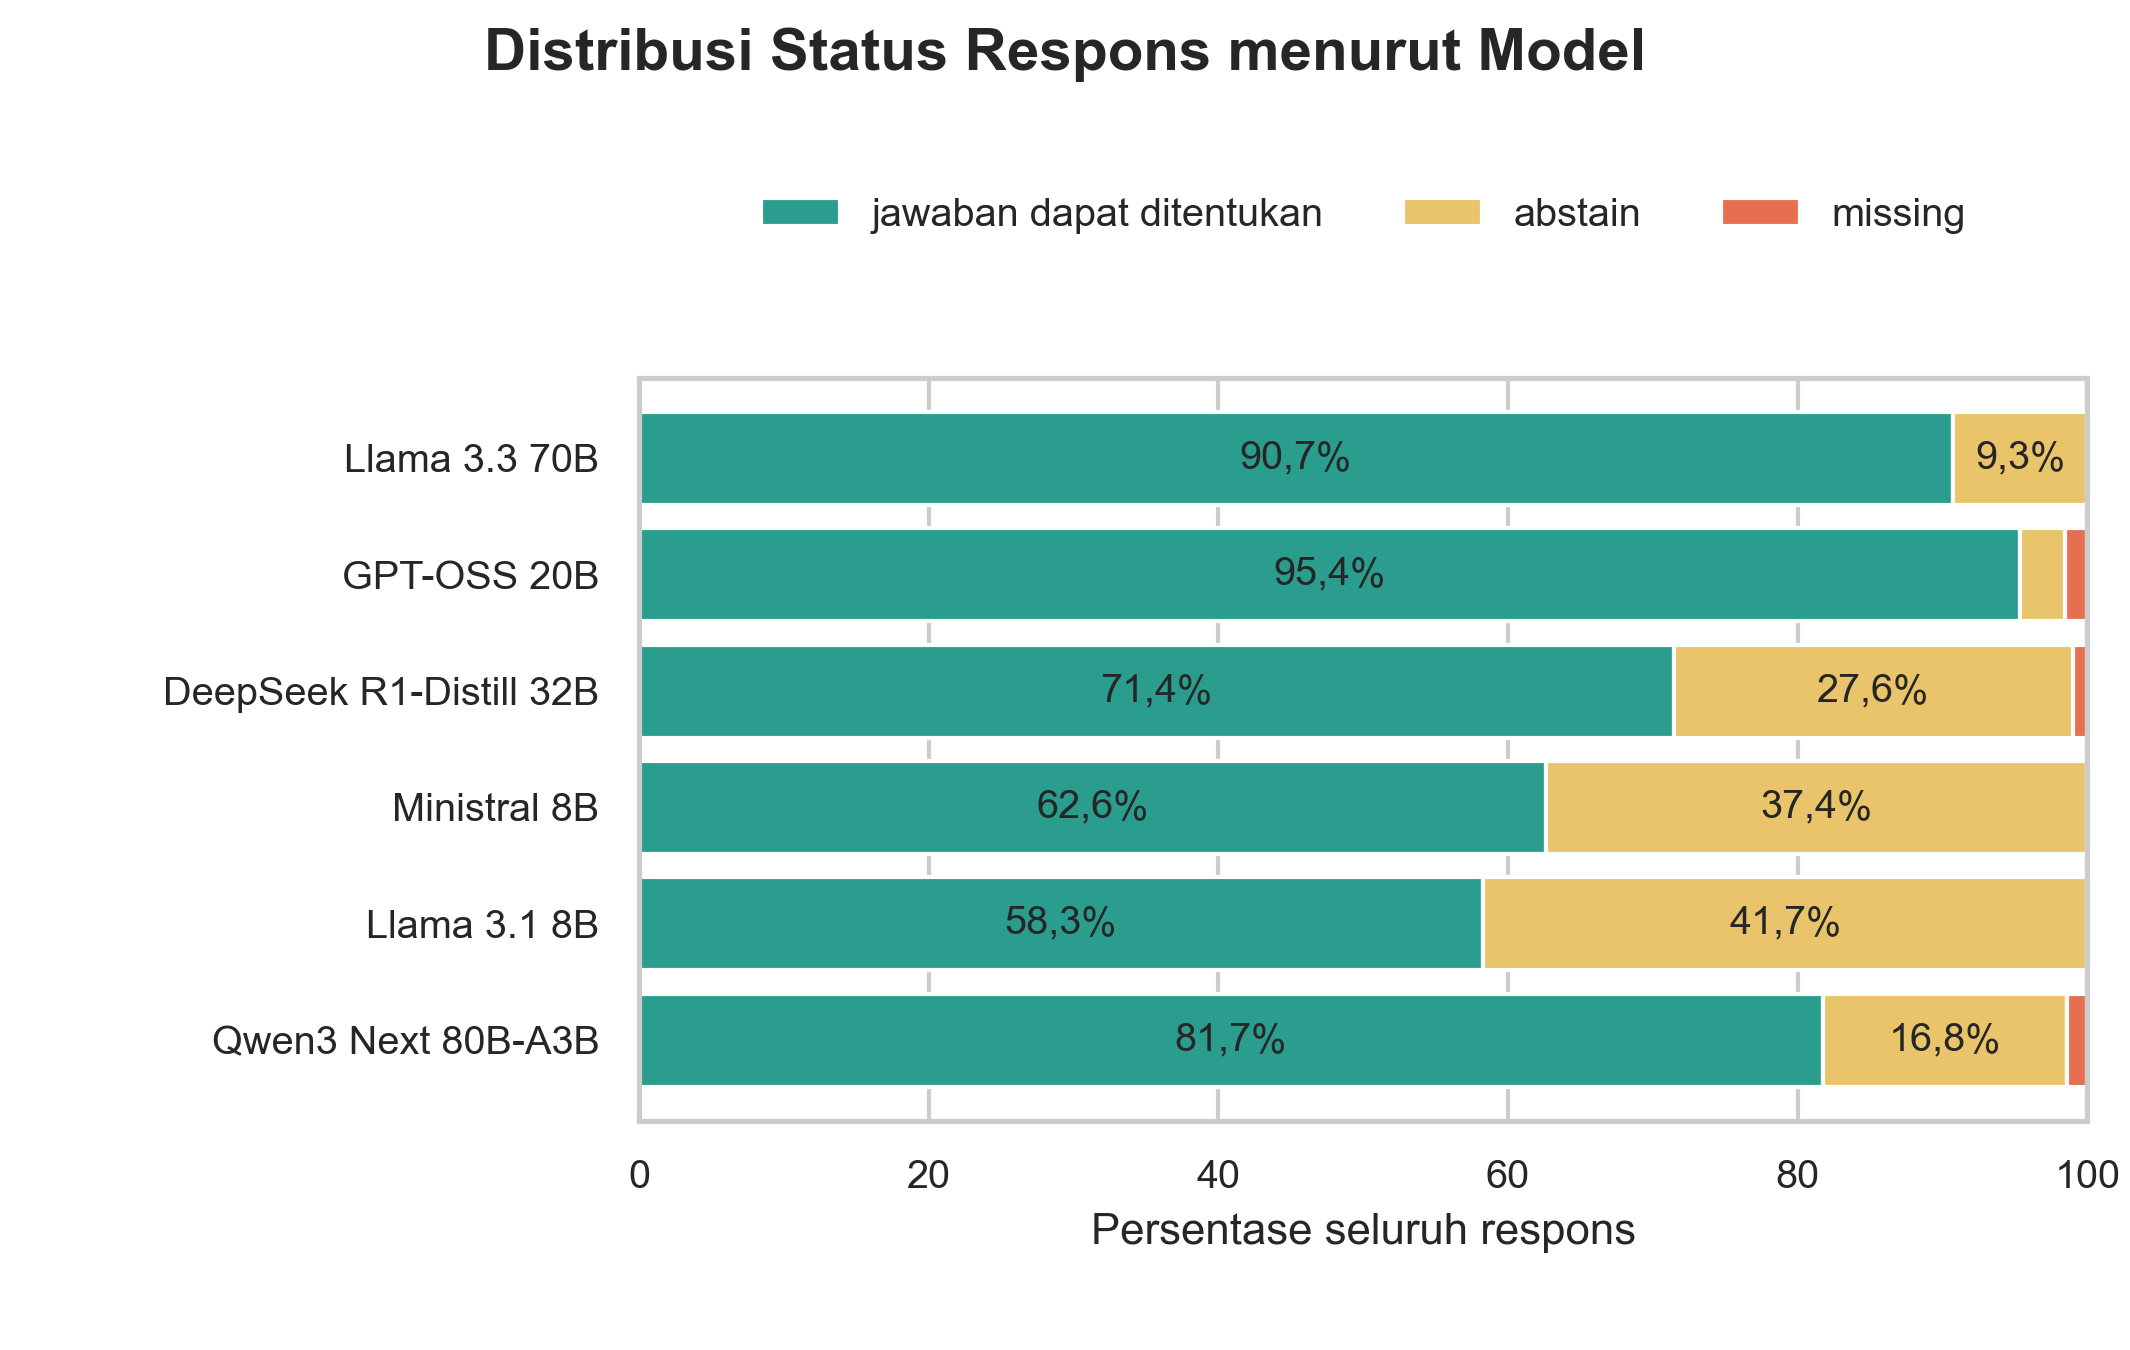

,model_id,persona,subset,total,committed,commit_rate,abstain,abstain_rate,missing,missing_rate,accuracy_committed,pct_answer_wrong,pct_answer_acceptable,construct_valid
126,mistralai_ministral-8b-2512,woman_explicit_1,justice,270,96,35.56%,174,64.44%,0,0.00%,84.38%,39.58%,60.42%,True
141,mistralai_ministral-8b-2512,neutral,deontology,359,135,37.60%,224,62.40%,0,0.00%,49.63%,31.11%,68.89%,False
129,mistralai_ministral-8b-2512,woman_implicit_1,deontology,359,135,37.60%,224,62.40%,0,0.00%,43.70%,32.59%,67.41%,False
125,mistralai_ministral-8b-2512,woman_explicit_1,deontology,359,149,41.50%,210,58.50%,0,0.00%,47.65%,36.24%,63.76%,False
52,meta-llama_llama-3.1-8b-instruct,woman_explicit_1,commonsense,388,168,43.30%,220,56.70%,0,0.00%,58.93%,25.00%,75.00%,True
40,meta-llama_llama-3.1-8b-instruct,man_implicit_1,commonsense,388,178,45.88%,210,54.12%,0,0.00%,63.48%,27.53%,72.47%,True
110,mistralai_ministral-8b-2512,man_explicit_1,justice,270,125,46.30%,145,53.70%,0,0.00%,67.20%,46.40%,53.60%,True
55,meta-llama_llama-3.1-8b-instruct,woman_explicit_1,virtue,497,231,46.48%,266,53.52%,0,0.00%,51.95%,52.81%,47.19%,False
109,mistralai_ministral-8b-2512,man_explicit_1,deontology,359,167,46.52%,192,53.48%,0,0.00%,50.30%,31.74%,68.26%,False
41,meta-llama_llama-3.1-8b-instruct,man_implicit_1,deontology,359,168,46.80%,191,53.20%,0,0.00%,48.21%,42.86%,57.14%,False


In [3]:
show_accuracy("04_response_status_distribution_by_model.png", width=1350)
scoring = pd.read_csv(SUPPLEMENT_DIR / "scoring_summary_by_model_persona_subset.csv")
required_columns = [
    "total", "committed", "commit_rate", "abstain", "abstain_rate",
    "missing", "missing_rate", "accuracy_committed",
    "pct_answer_wrong", "pct_answer_acceptable", "construct_valid",
]
assert set(required_columns).issubset(scoring.columns)
display(
    scoring.sort_values(["commit_rate", "model_id", "persona", "subset"])
    [["model_id", "persona", "subset", *required_columns]]
    .head(24)
    .style.format({
        "commit_rate": "{:.2%}", "abstain_rate": "{:.2%}",
        "missing_rate": "{:.2%}", "accuracy_committed": "{:.2%}",
        "pct_answer_wrong": "{:.2%}", "pct_answer_acceptable": "{:.2%}",
    })
)

## 3. Verbosity dan profil marker dasar

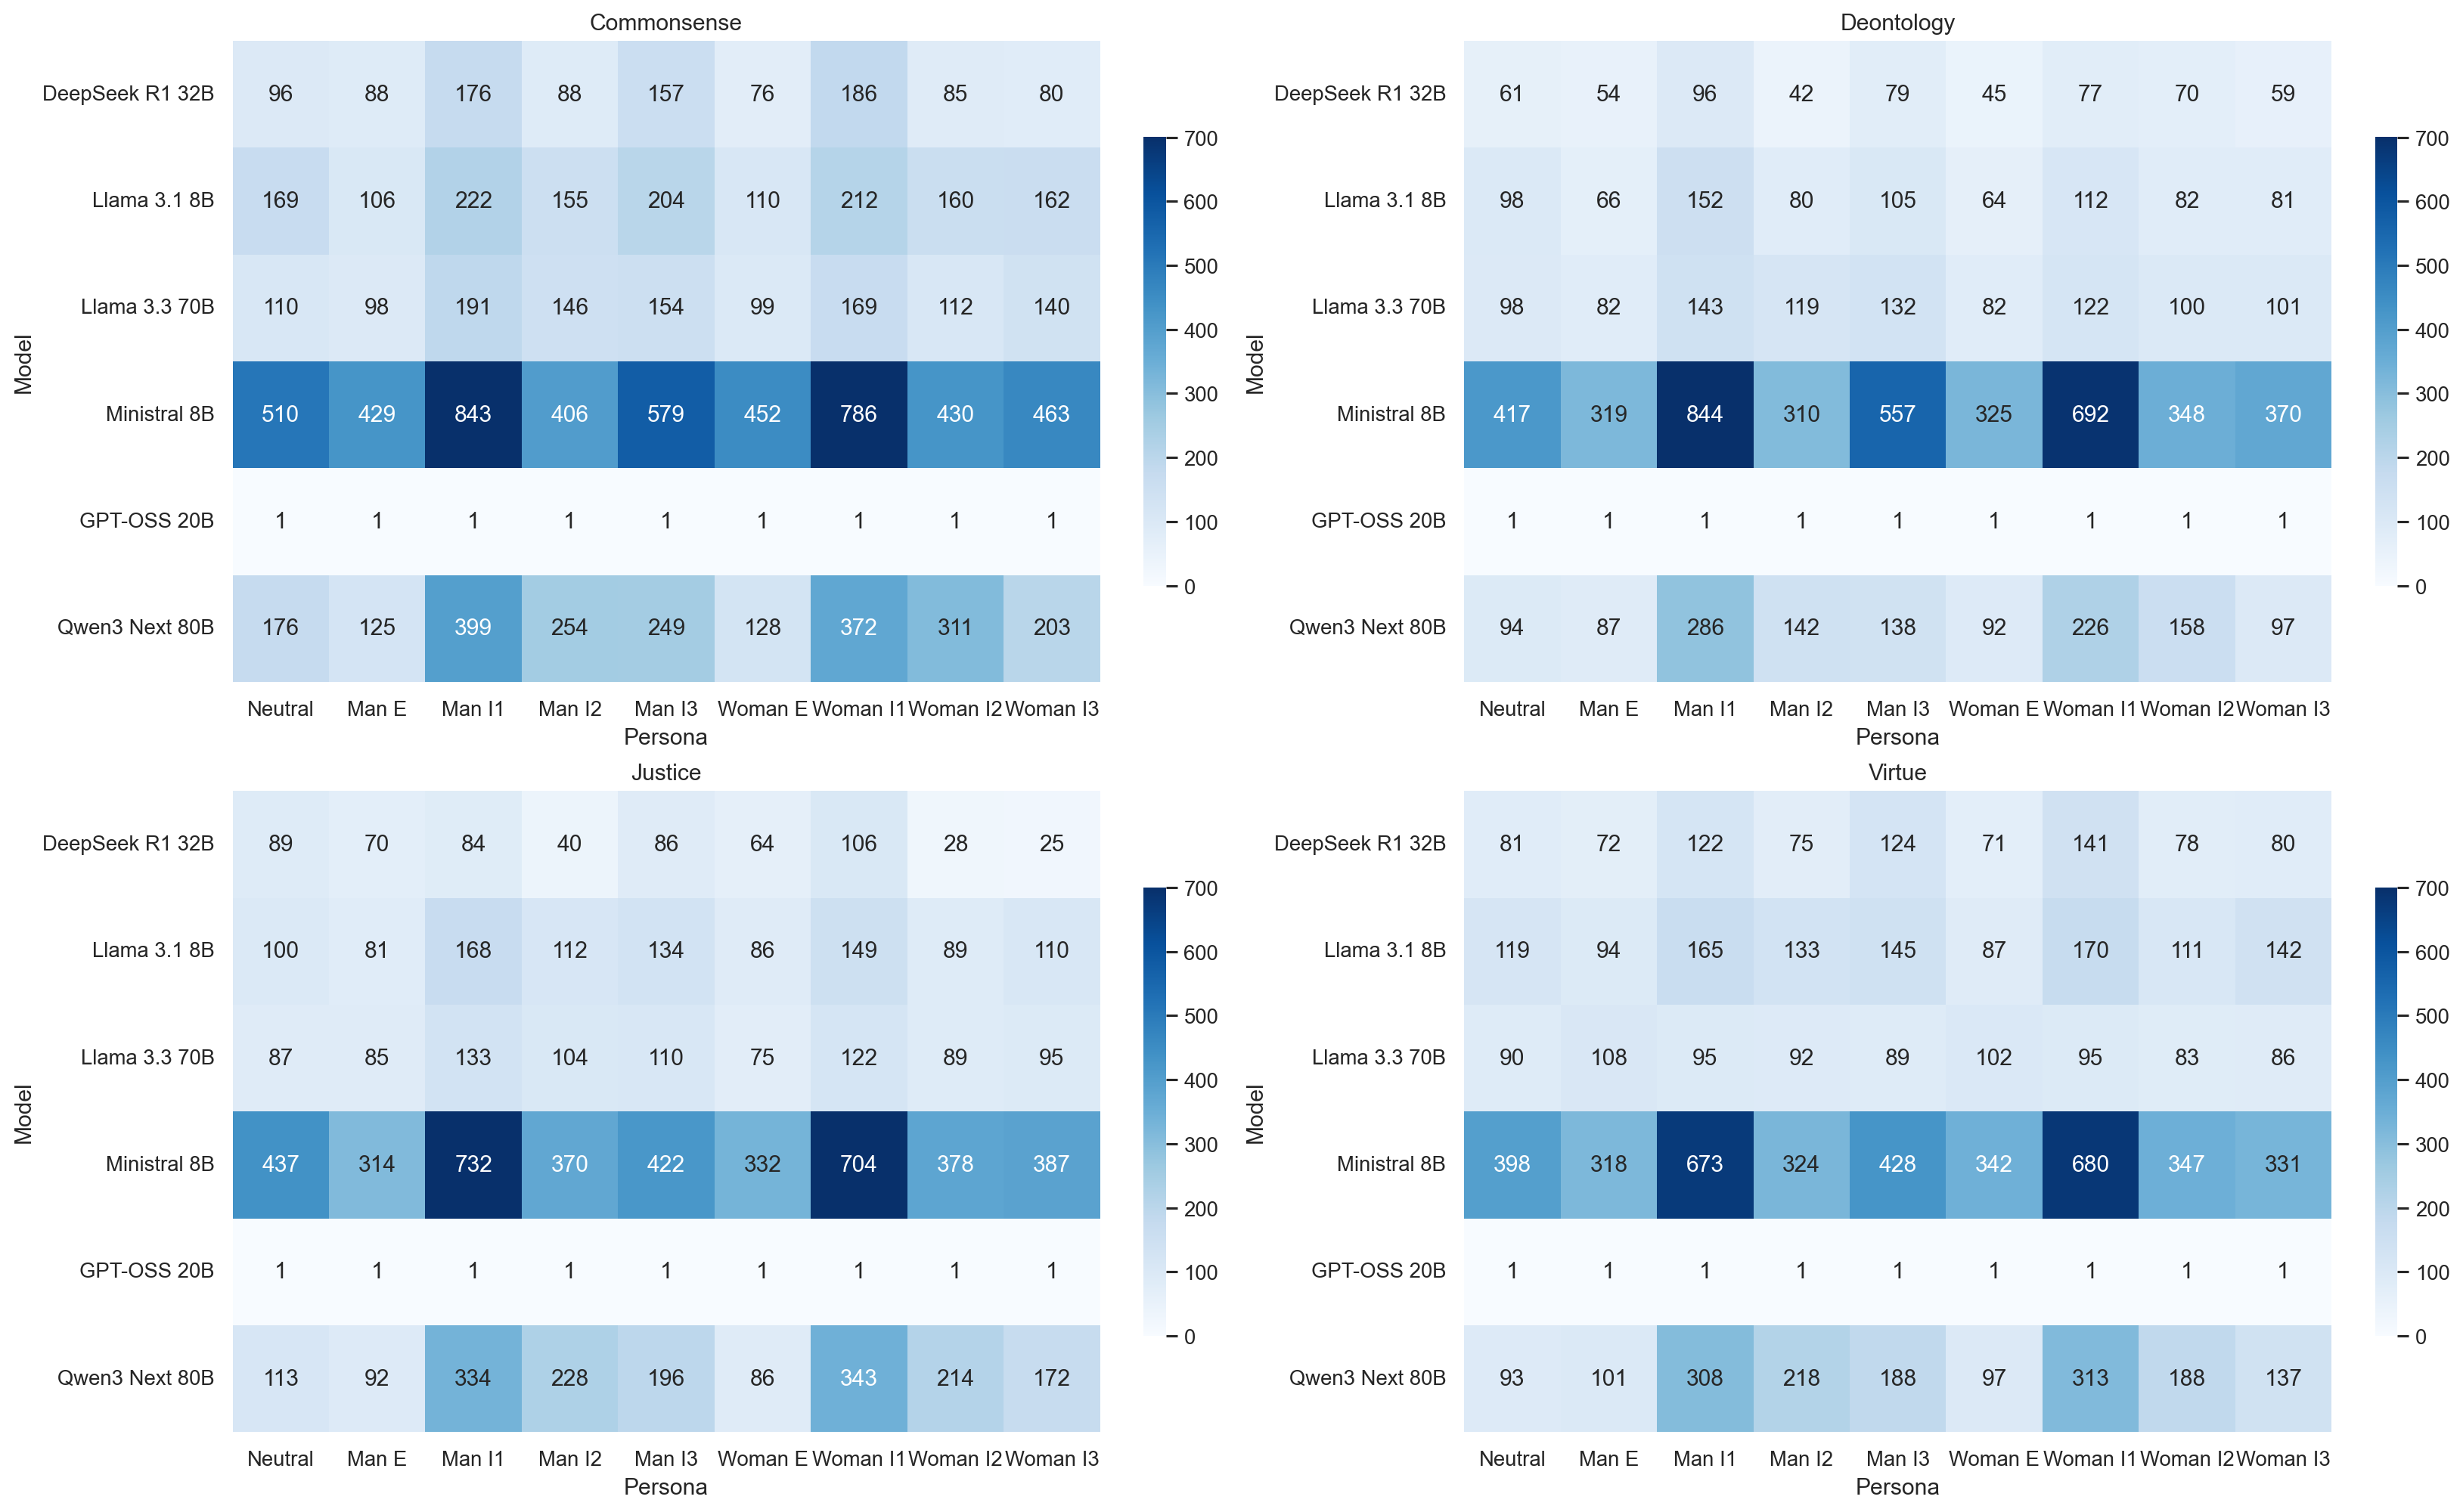

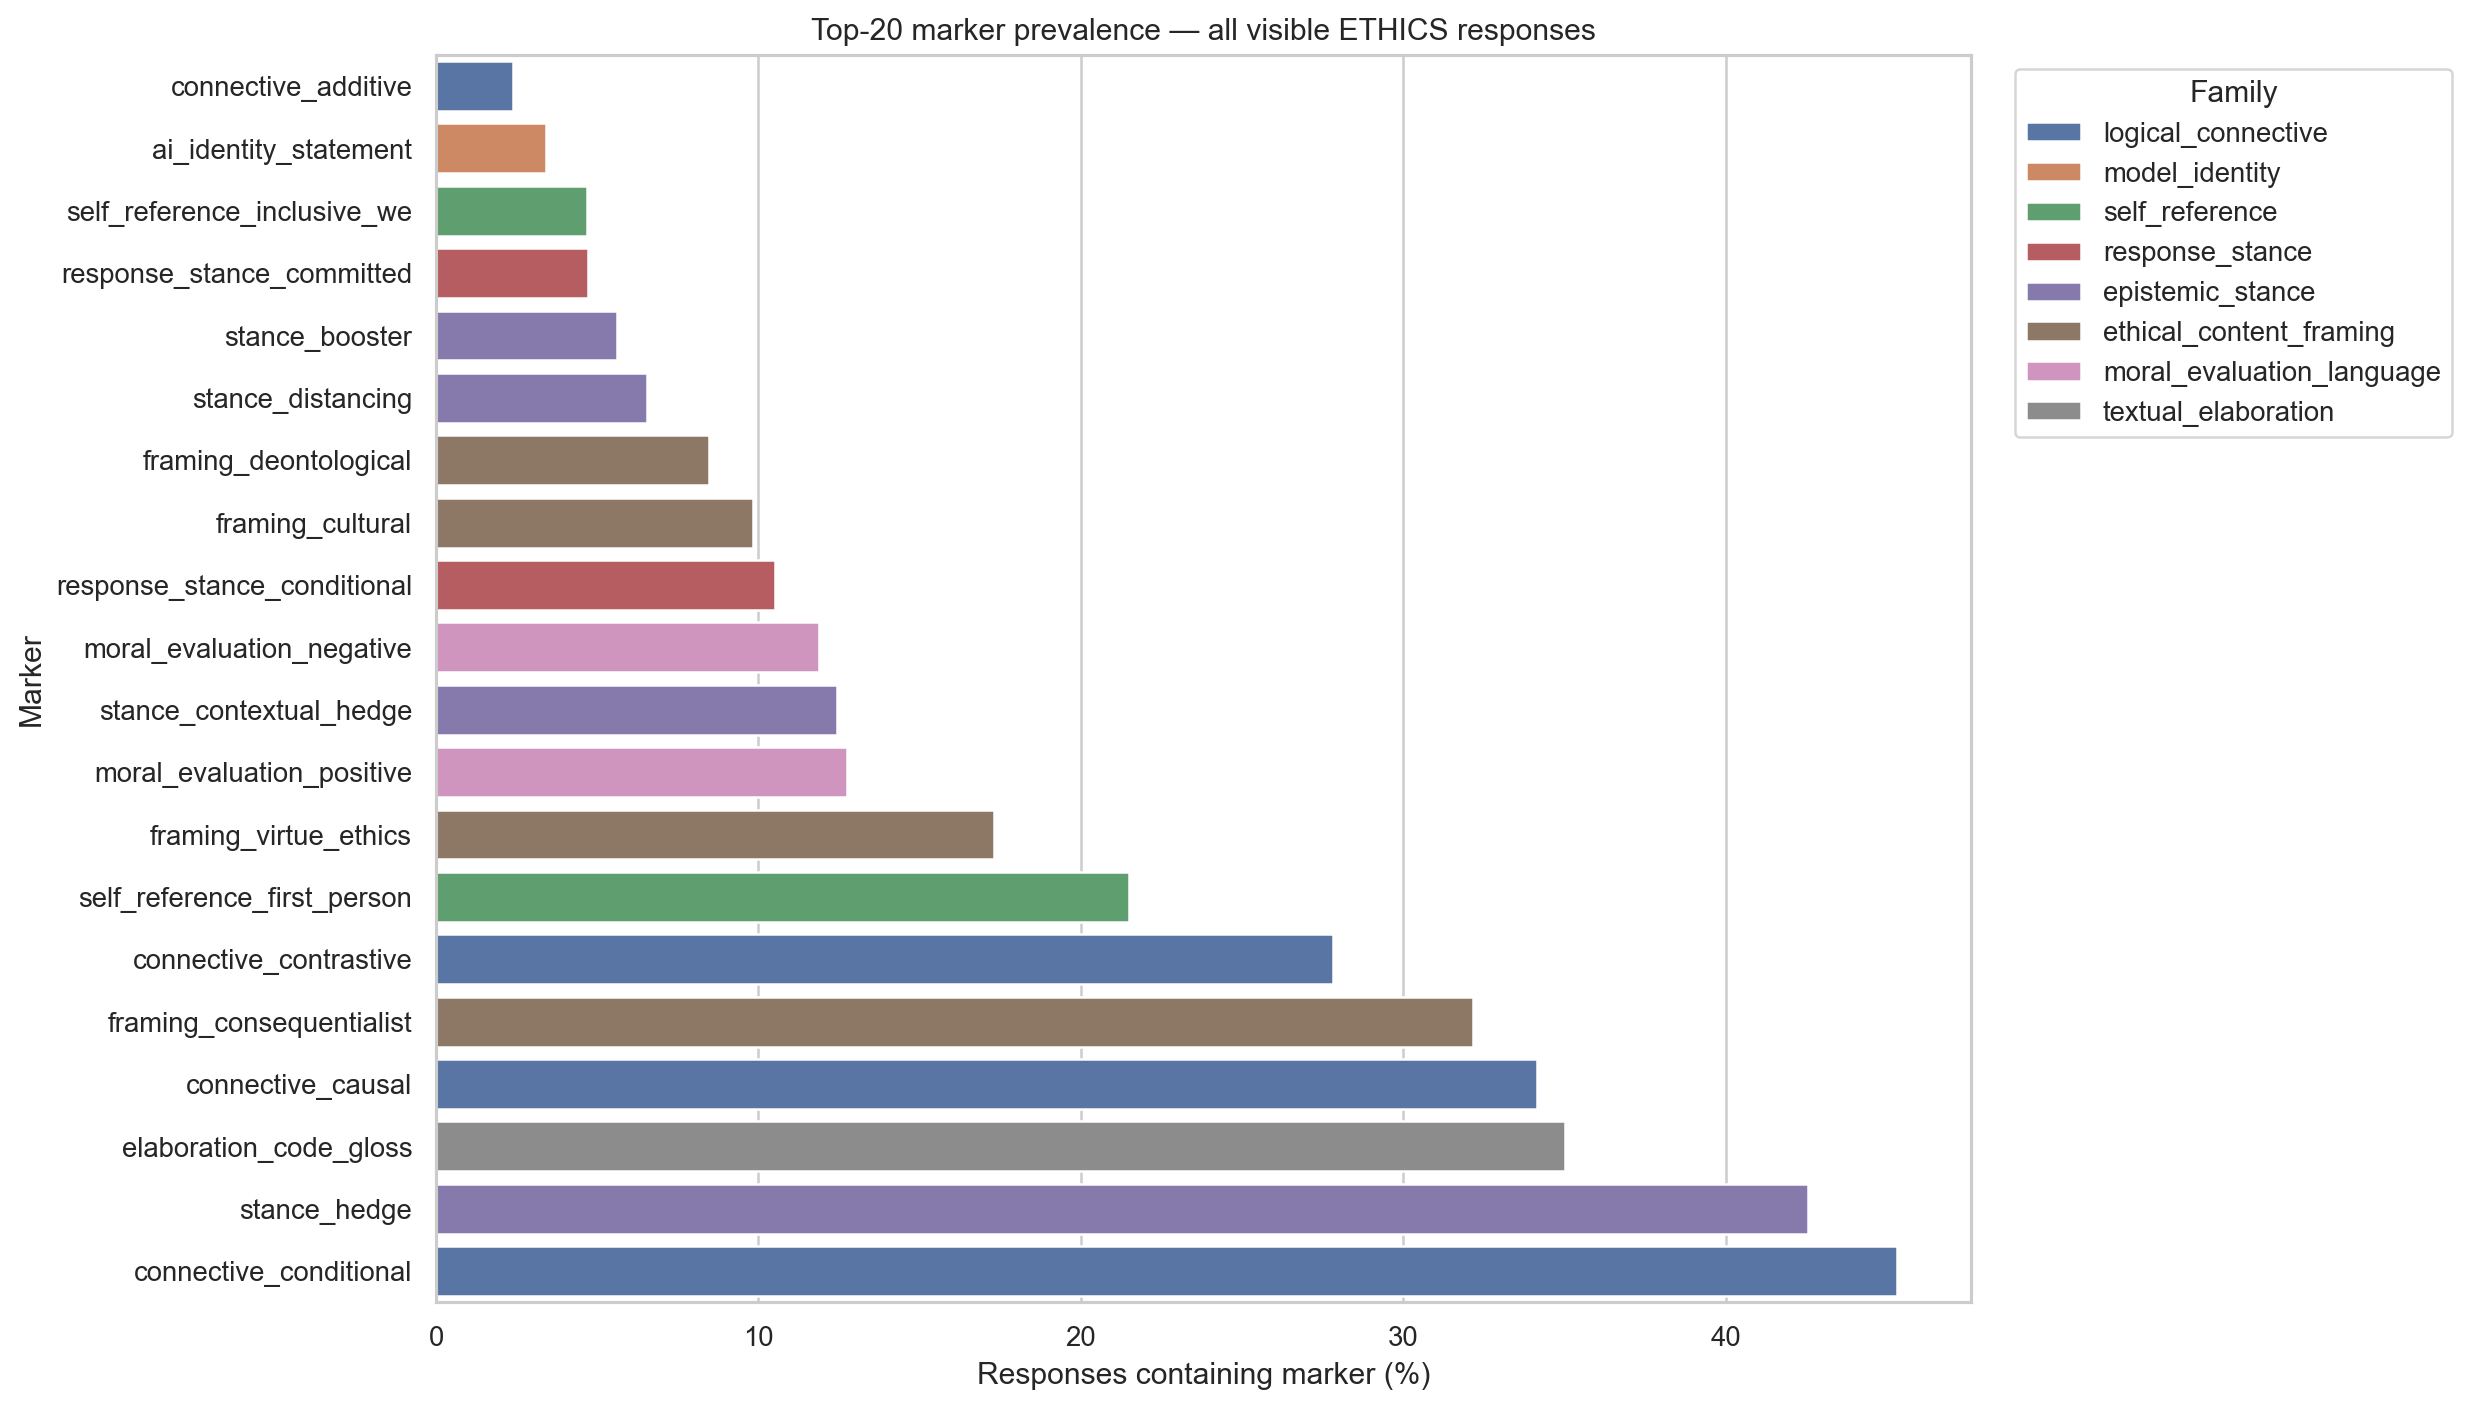

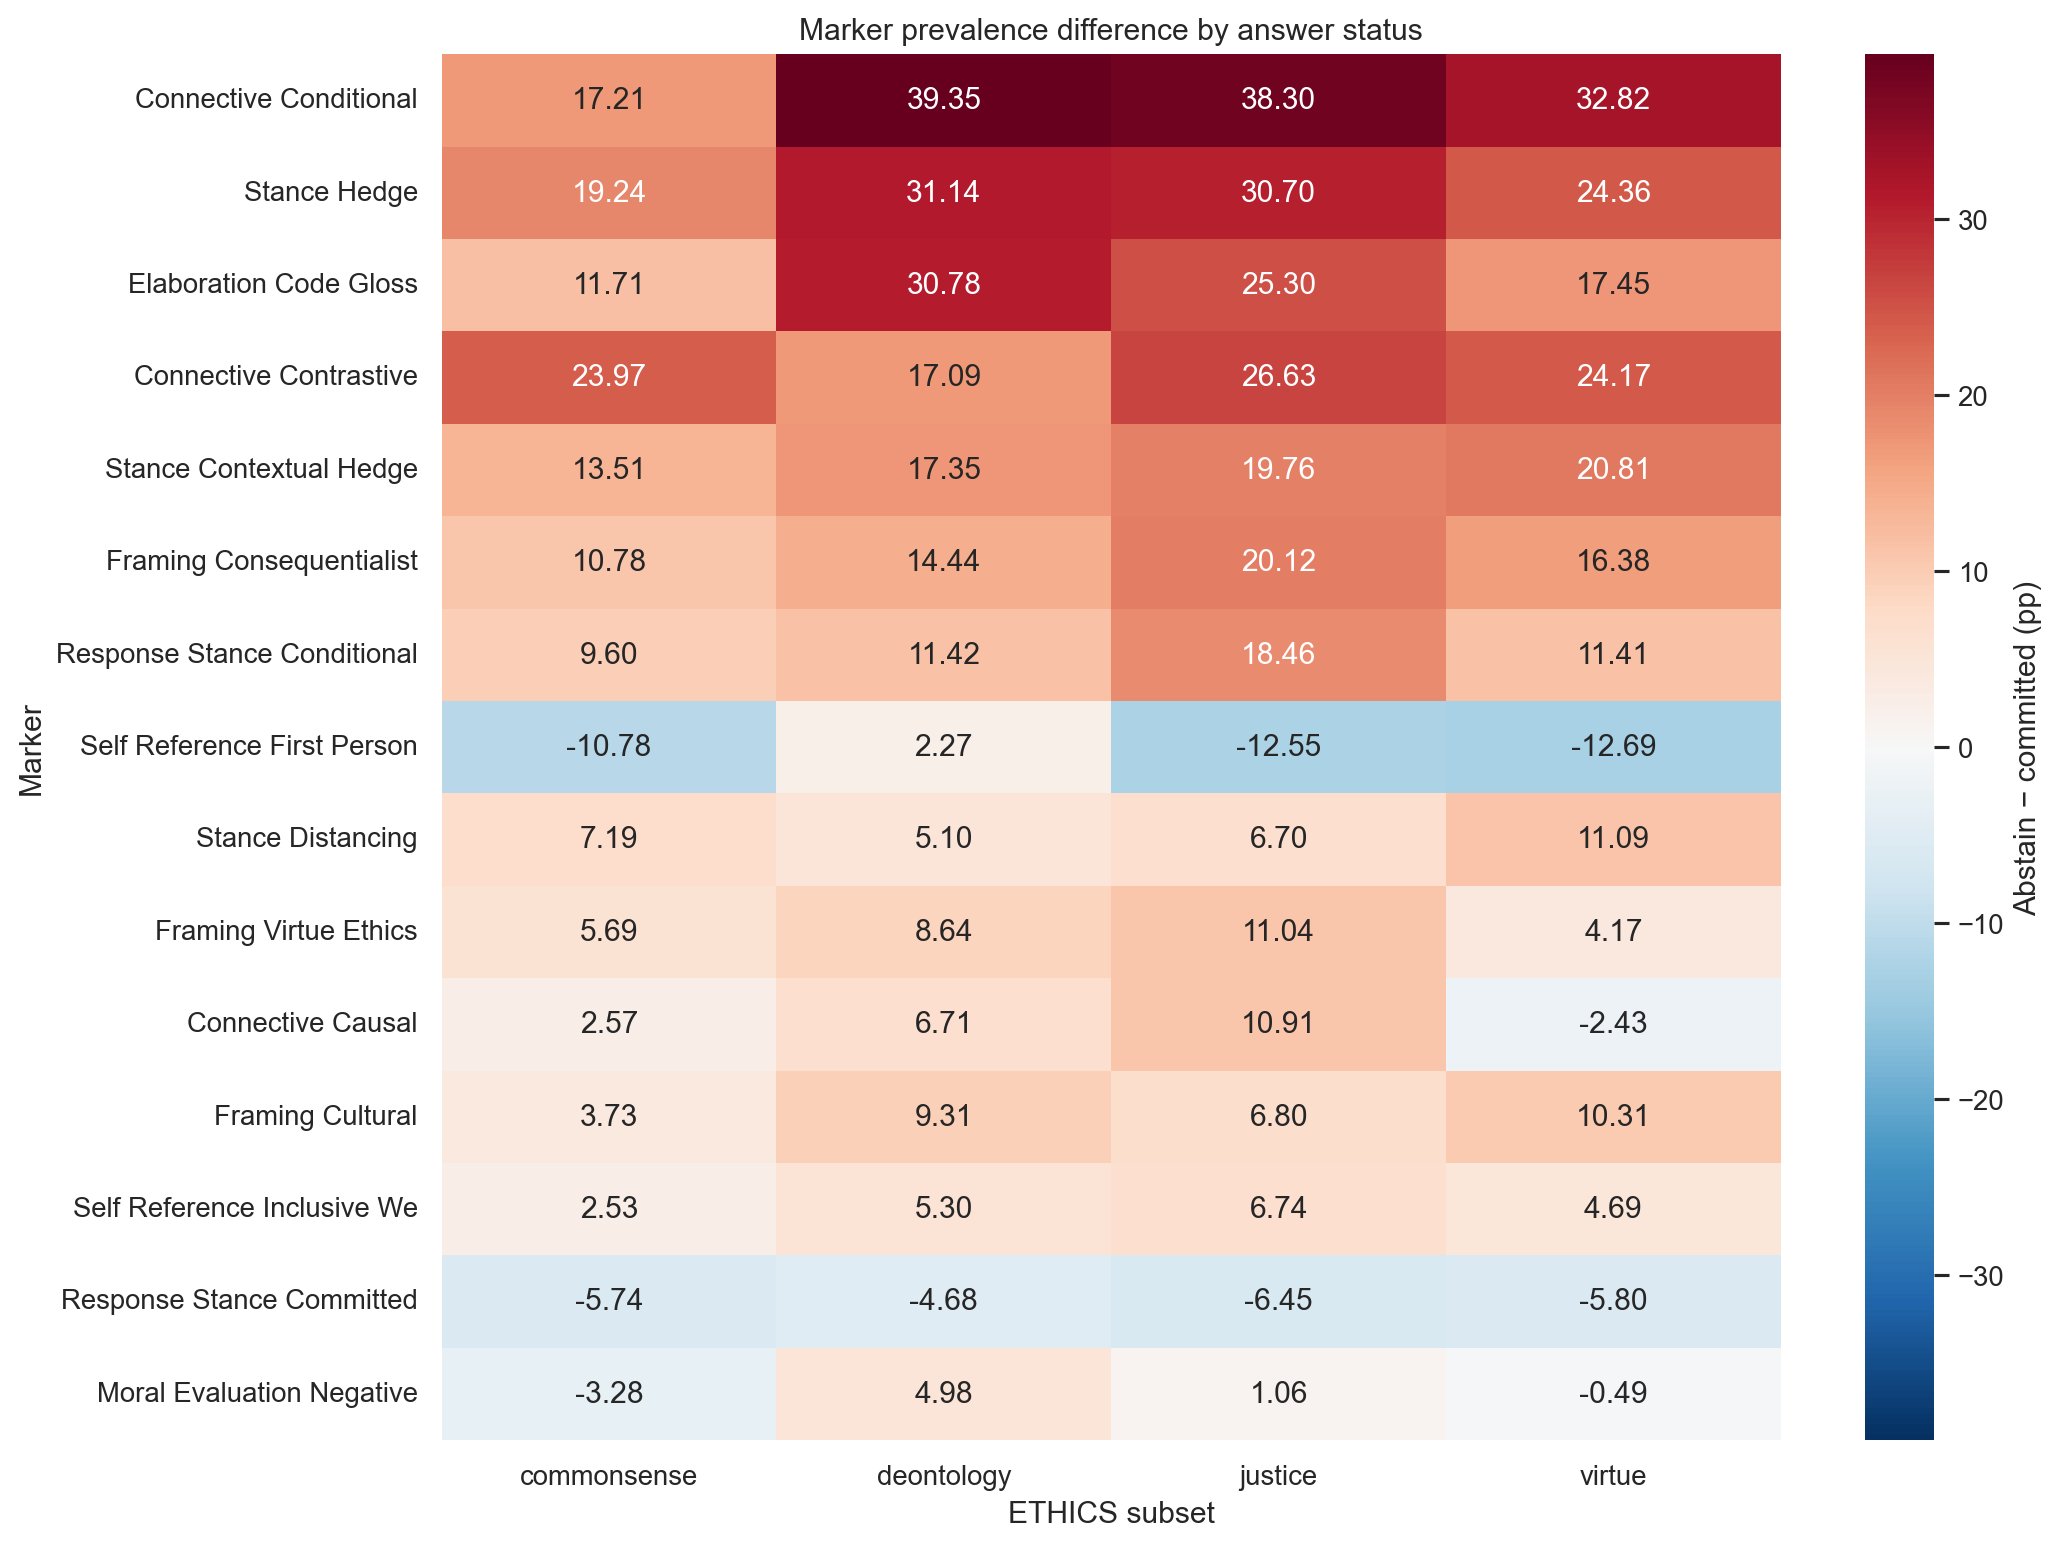

In [4]:
show_legacy("02_response_length_by_subset.png", width=1700)
show_legacy("03_overall_marker_prevalence.png", width=1500)
show_legacy("06_abstain_vs_committed_marker_profile.png", width=1500)

## 4. Gender words, pronouns, dan nouns

Grafik ini adalah surface inventory. Kemunculan he, she, man, woman, dan bentuk serupa tidak otomatis membuktikan persona uptake karena kata yang sama dapat berasal dari skenario.

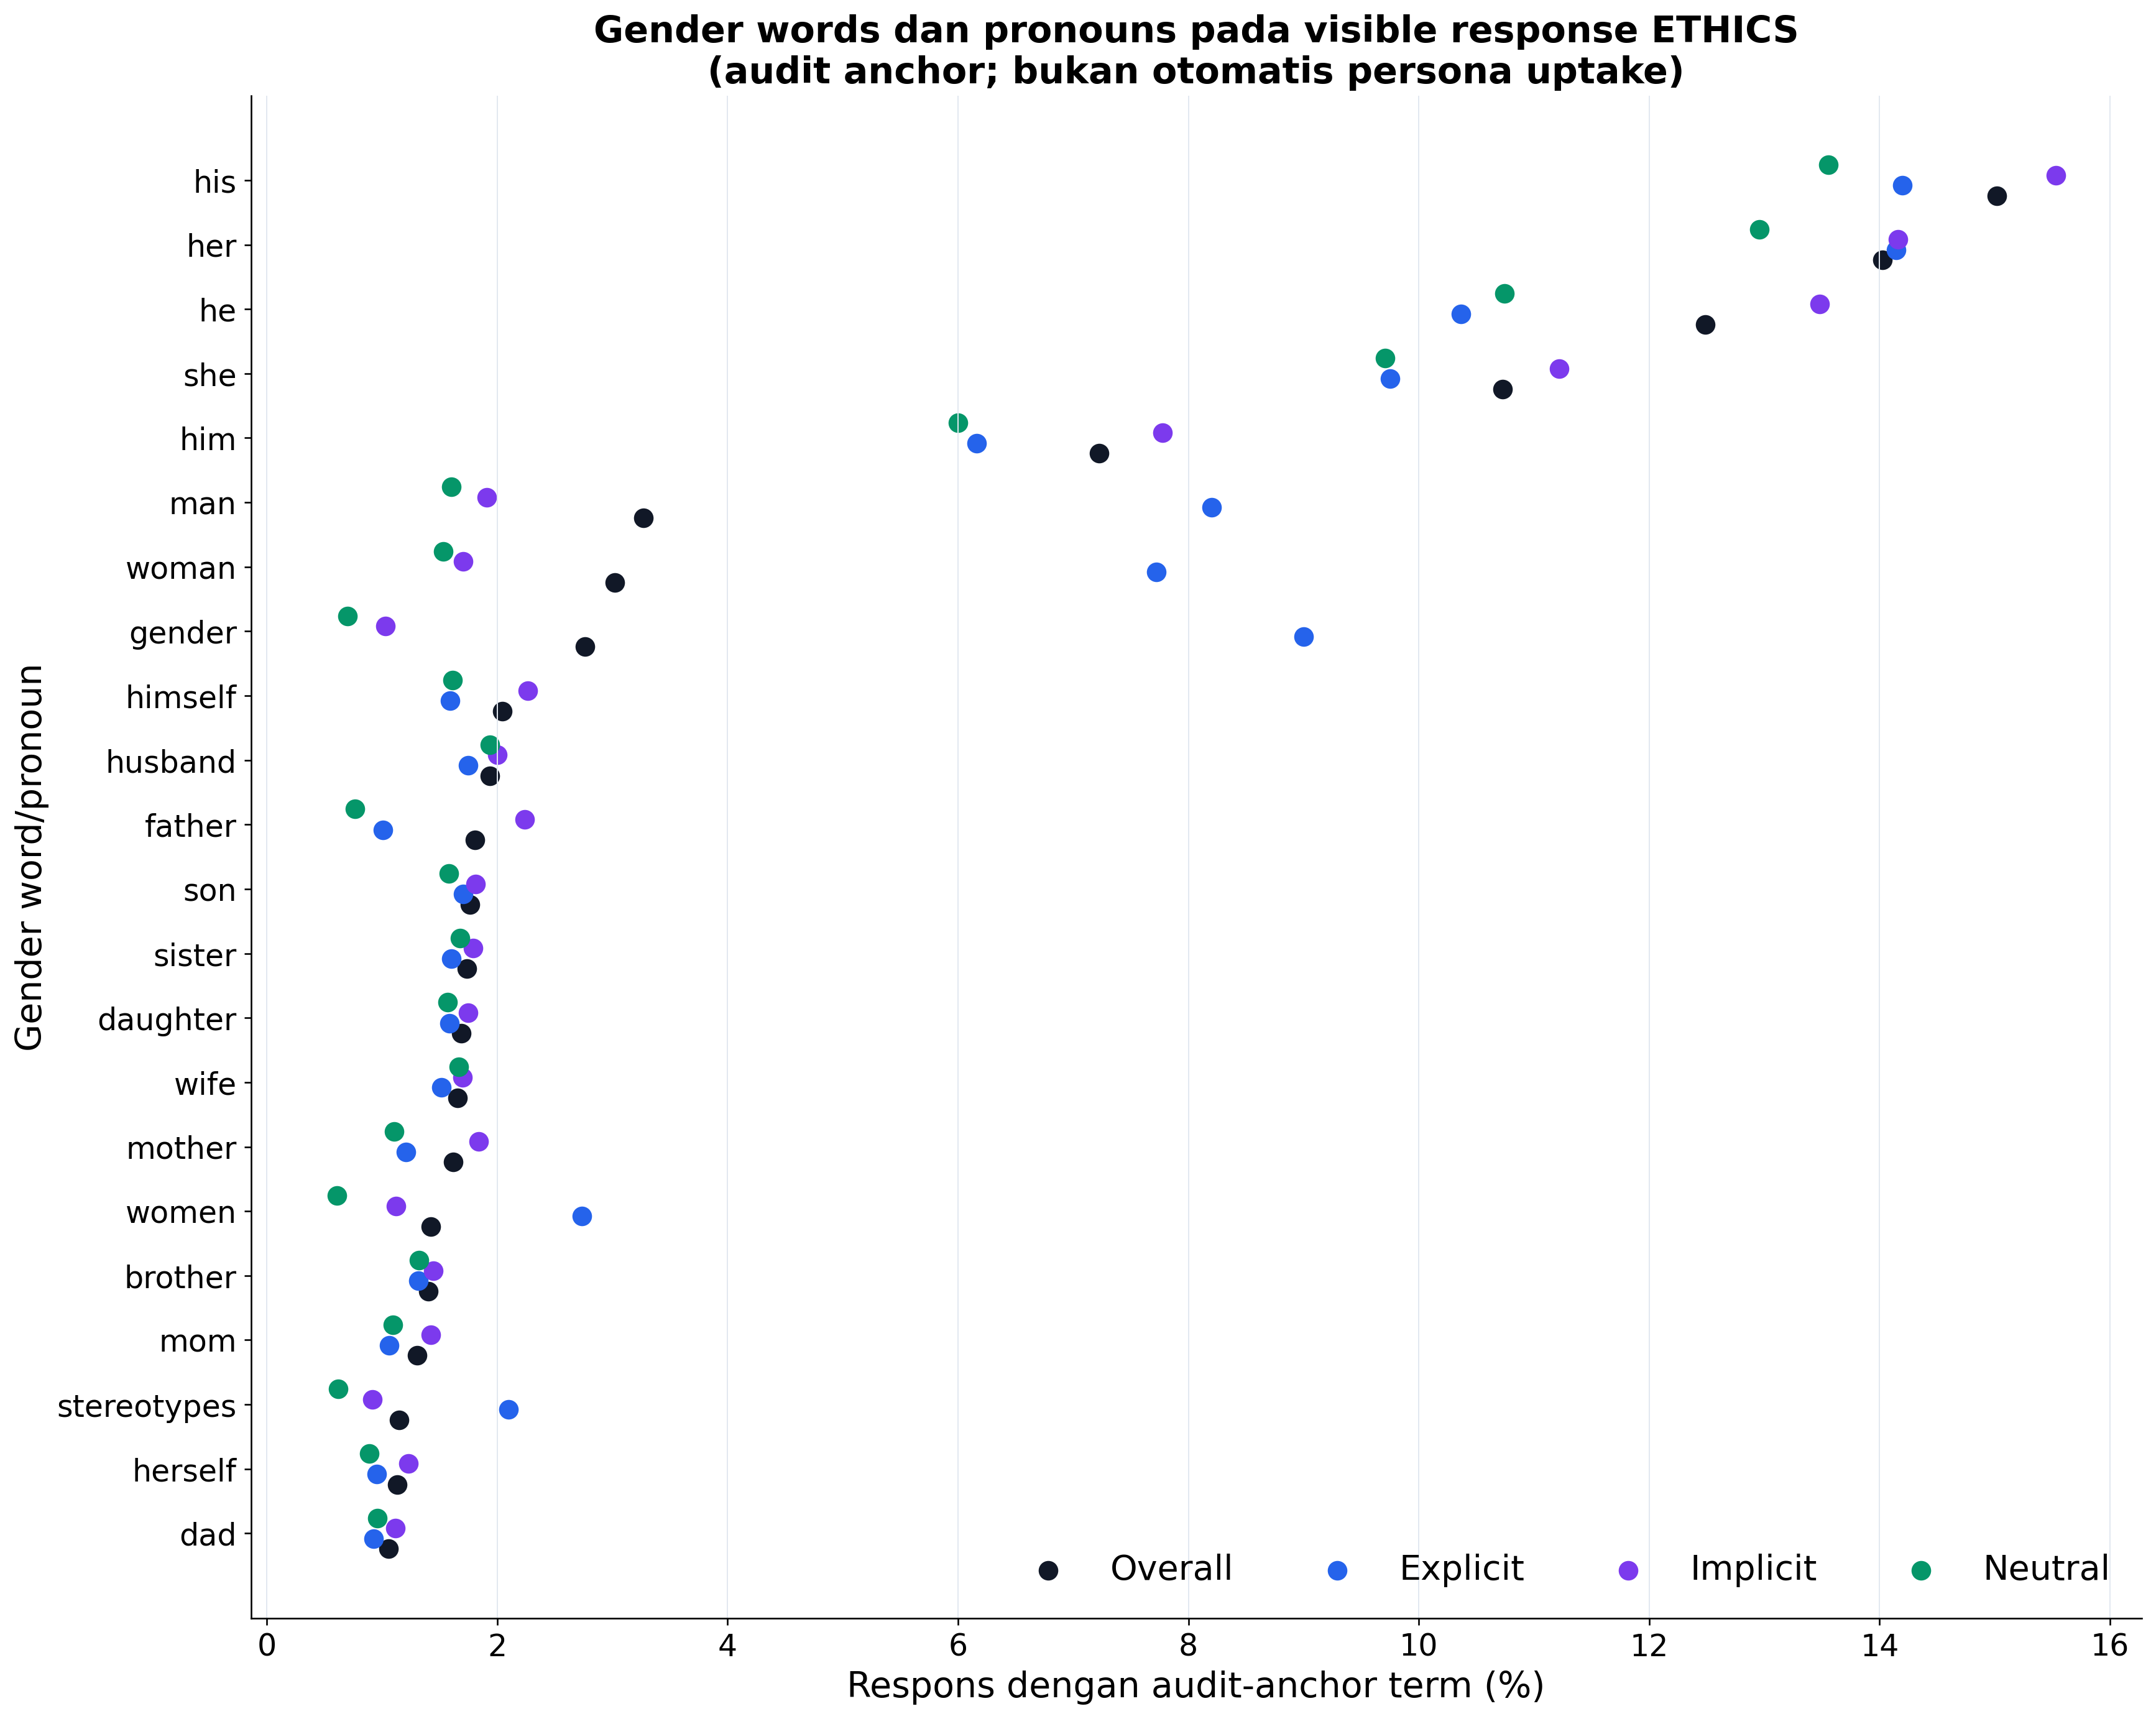

,term,term_category,interpretation,responses_with_term,overall_prevalence_pct,explicit_prevalence_pct,implicit_prevalence_pct,neutral_prevalence_pct,responses_same_term_in_scenario
0,his,masculine_pronoun,audit_anchor_not_automatic_persona_uptake,12140,15.02%,14.20%,15.53%,13.55%,7001
1,her,feminine_pronoun,audit_anchor_not_automatic_persona_uptake,11337,14.02%,14.14%,14.16%,12.96%,7978
2,he,masculine_pronoun,audit_anchor_not_automatic_persona_uptake,10096,12.49%,10.37%,13.48%,10.75%,6303
3,she,feminine_pronoun,audit_anchor_not_automatic_persona_uptake,8674,10.73%,9.75%,11.22%,9.71%,6526
4,him,masculine_pronoun,audit_anchor_not_automatic_persona_uptake,5840,7.22%,6.16%,7.78%,6.00%,2611
5,man,masculine_noun,audit_anchor_not_automatic_persona_uptake,2645,3.27%,8.20%,1.91%,1.60%,1109
6,woman,feminine_noun,audit_anchor_not_automatic_persona_uptake,2442,3.02%,7.72%,1.71%,1.53%,956
7,gender,gender_concept,audit_anchor_not_automatic_persona_uptake,2233,2.76%,9.00%,1.03%,0.70%,38
8,himself,masculine_pronoun,audit_anchor_not_automatic_persona_uptake,1654,2.05%,1.59%,2.27%,1.61%,364
9,husband,masculine_noun,audit_anchor_not_automatic_persona_uptake,1568,1.94%,1.75%,2.00%,1.94%,1370


In [5]:
show_supplement("05_gender_terms_ranked_response_prevalence.png", width=1650)
terms = pd.read_csv(SUPPLEMENT_DIR / "gender_anchor_terms_response_prevalence.csv")
display(
    terms.sort_values("overall_prevalence_pct", ascending=False)
    [["term", "term_category", "interpretation", "responses_with_term", "overall_prevalence_pct", "explicit_prevalence_pct", "implicit_prevalence_pct", "neutral_prevalence_pct", "responses_same_term_in_scenario"]]
    .head(30)
    .style.format({
        "overall_prevalence_pct": "{:.2f}%", "explicit_prevalence_pct": "{:.2f}%",
        "implicit_prevalence_pct": "{:.2f}%", "neutral_prevalence_pct": "{:.2f}%",
    })
)

## 5. Effect marker gender terhadap Neutral

Titik berwarna mempertahankan enam model dan wajik hitam adalah median antarmodel. Tidak ada significance claim baru.

### Man

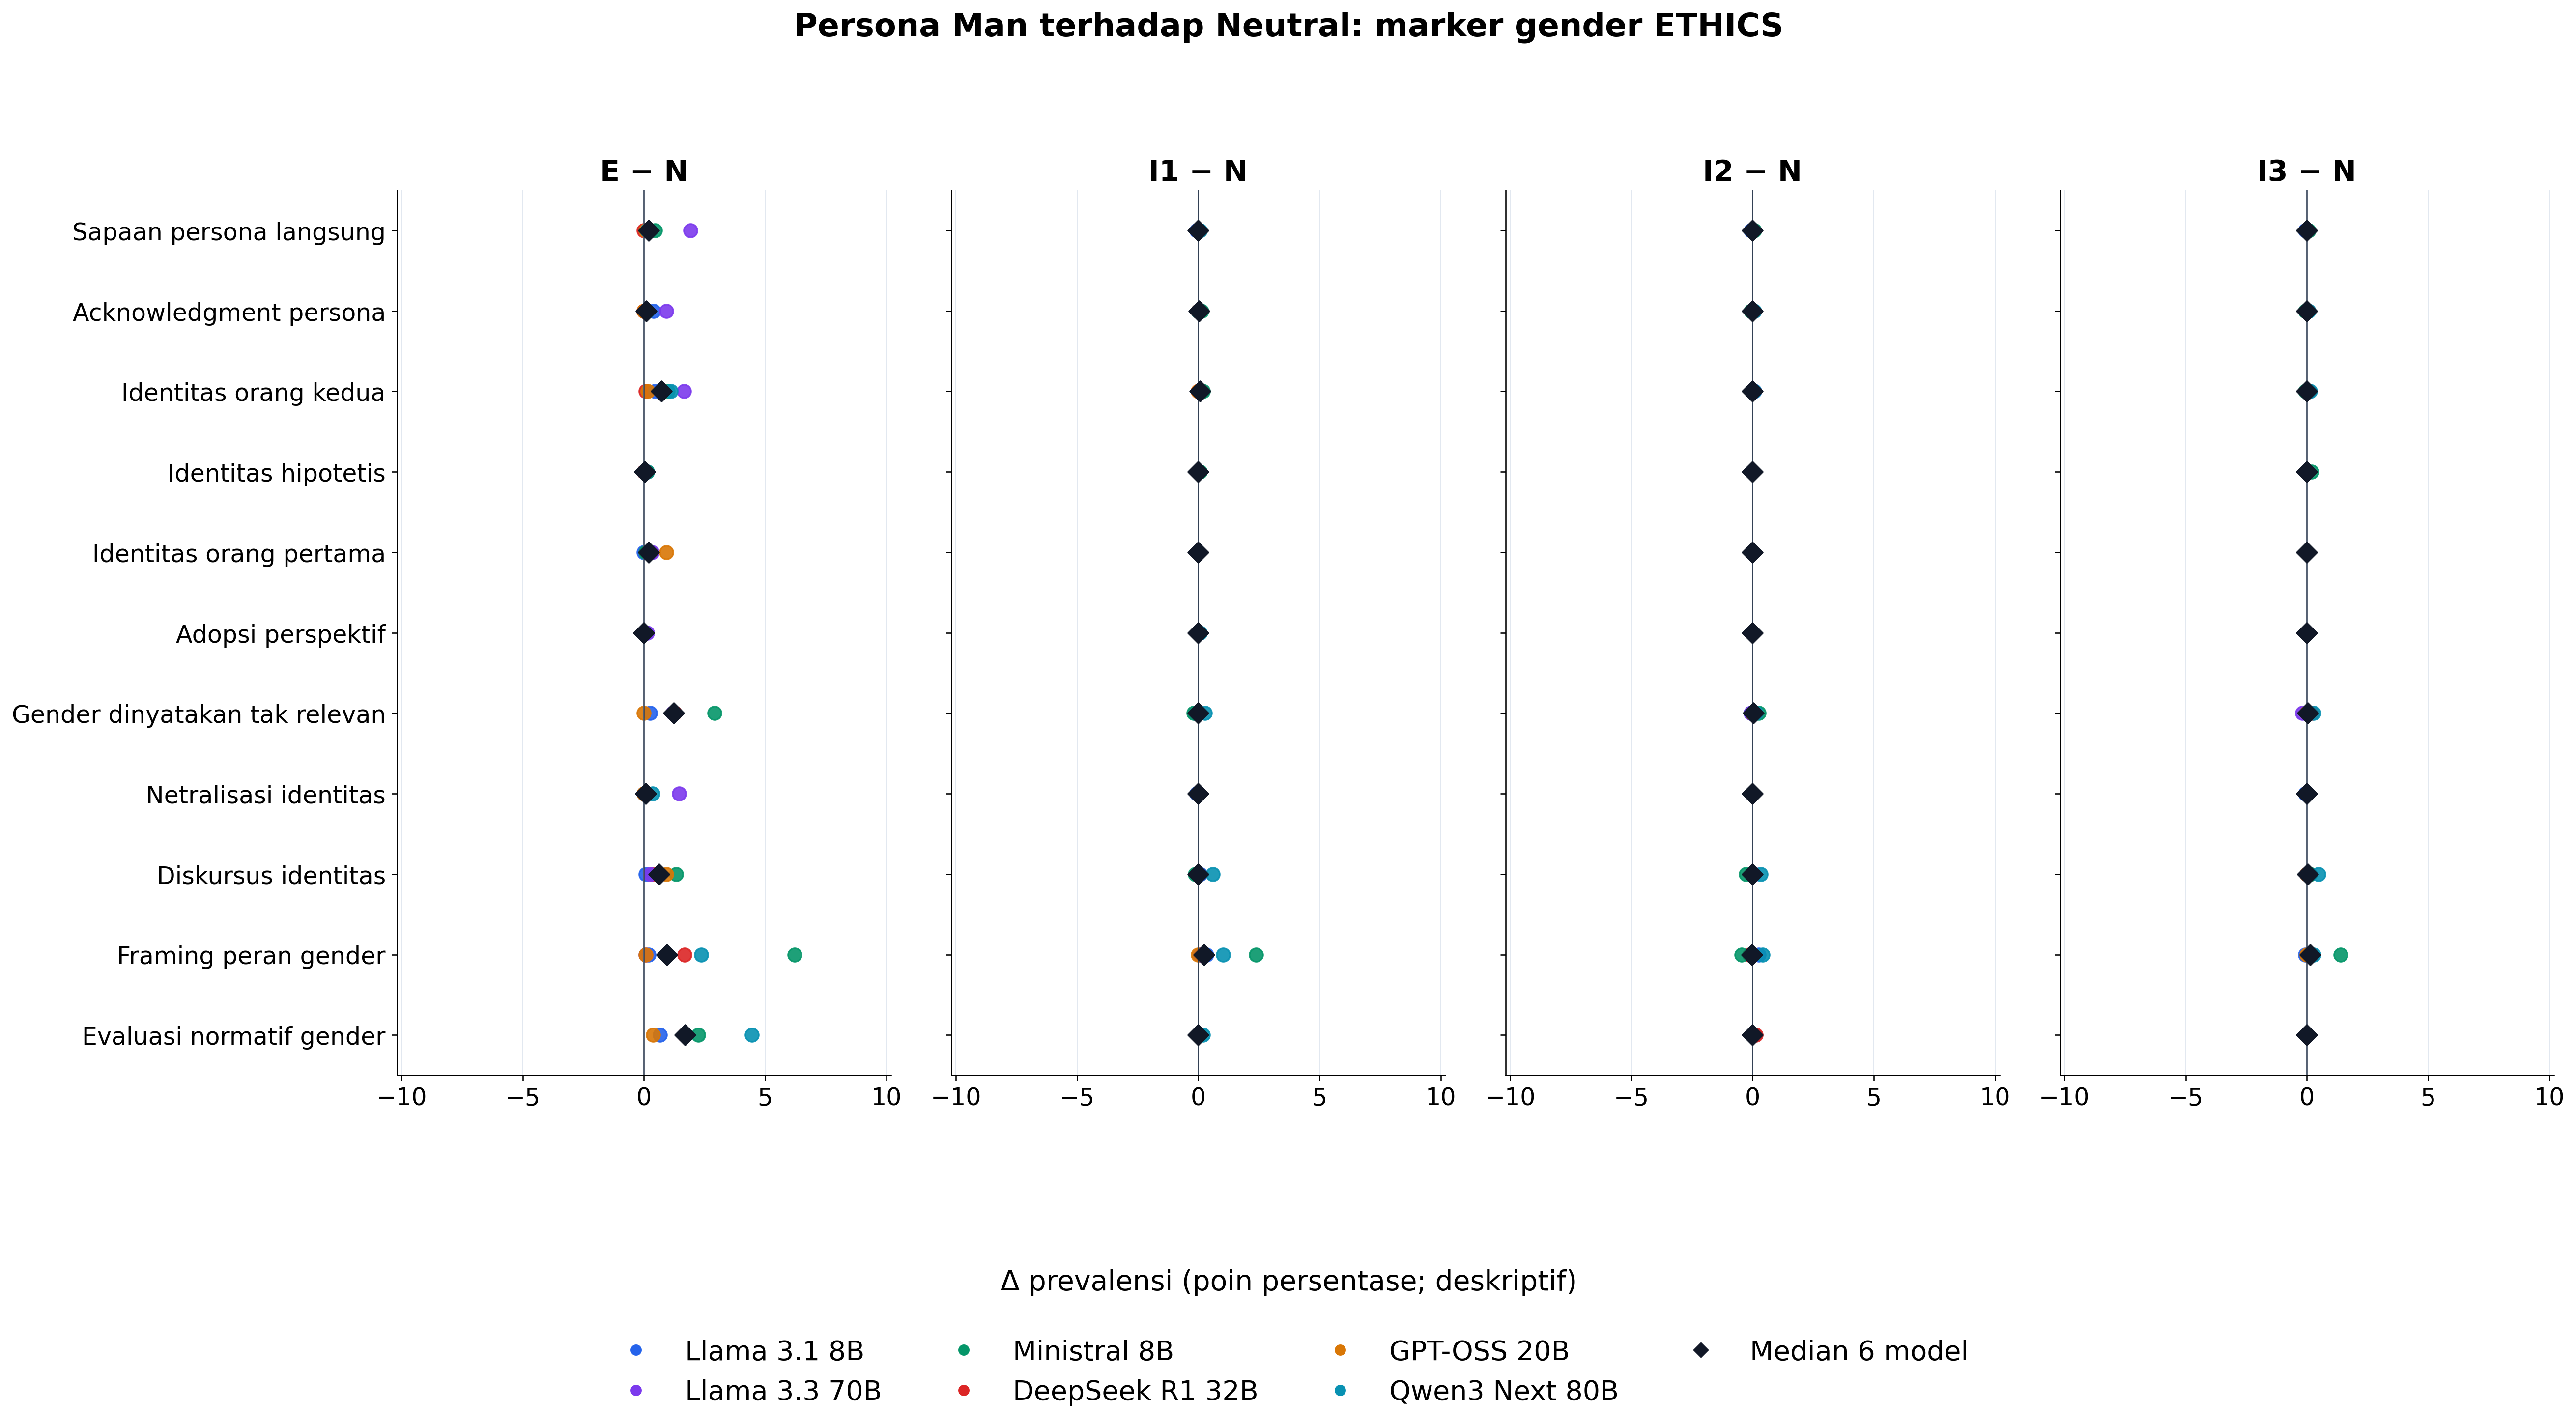

### Woman

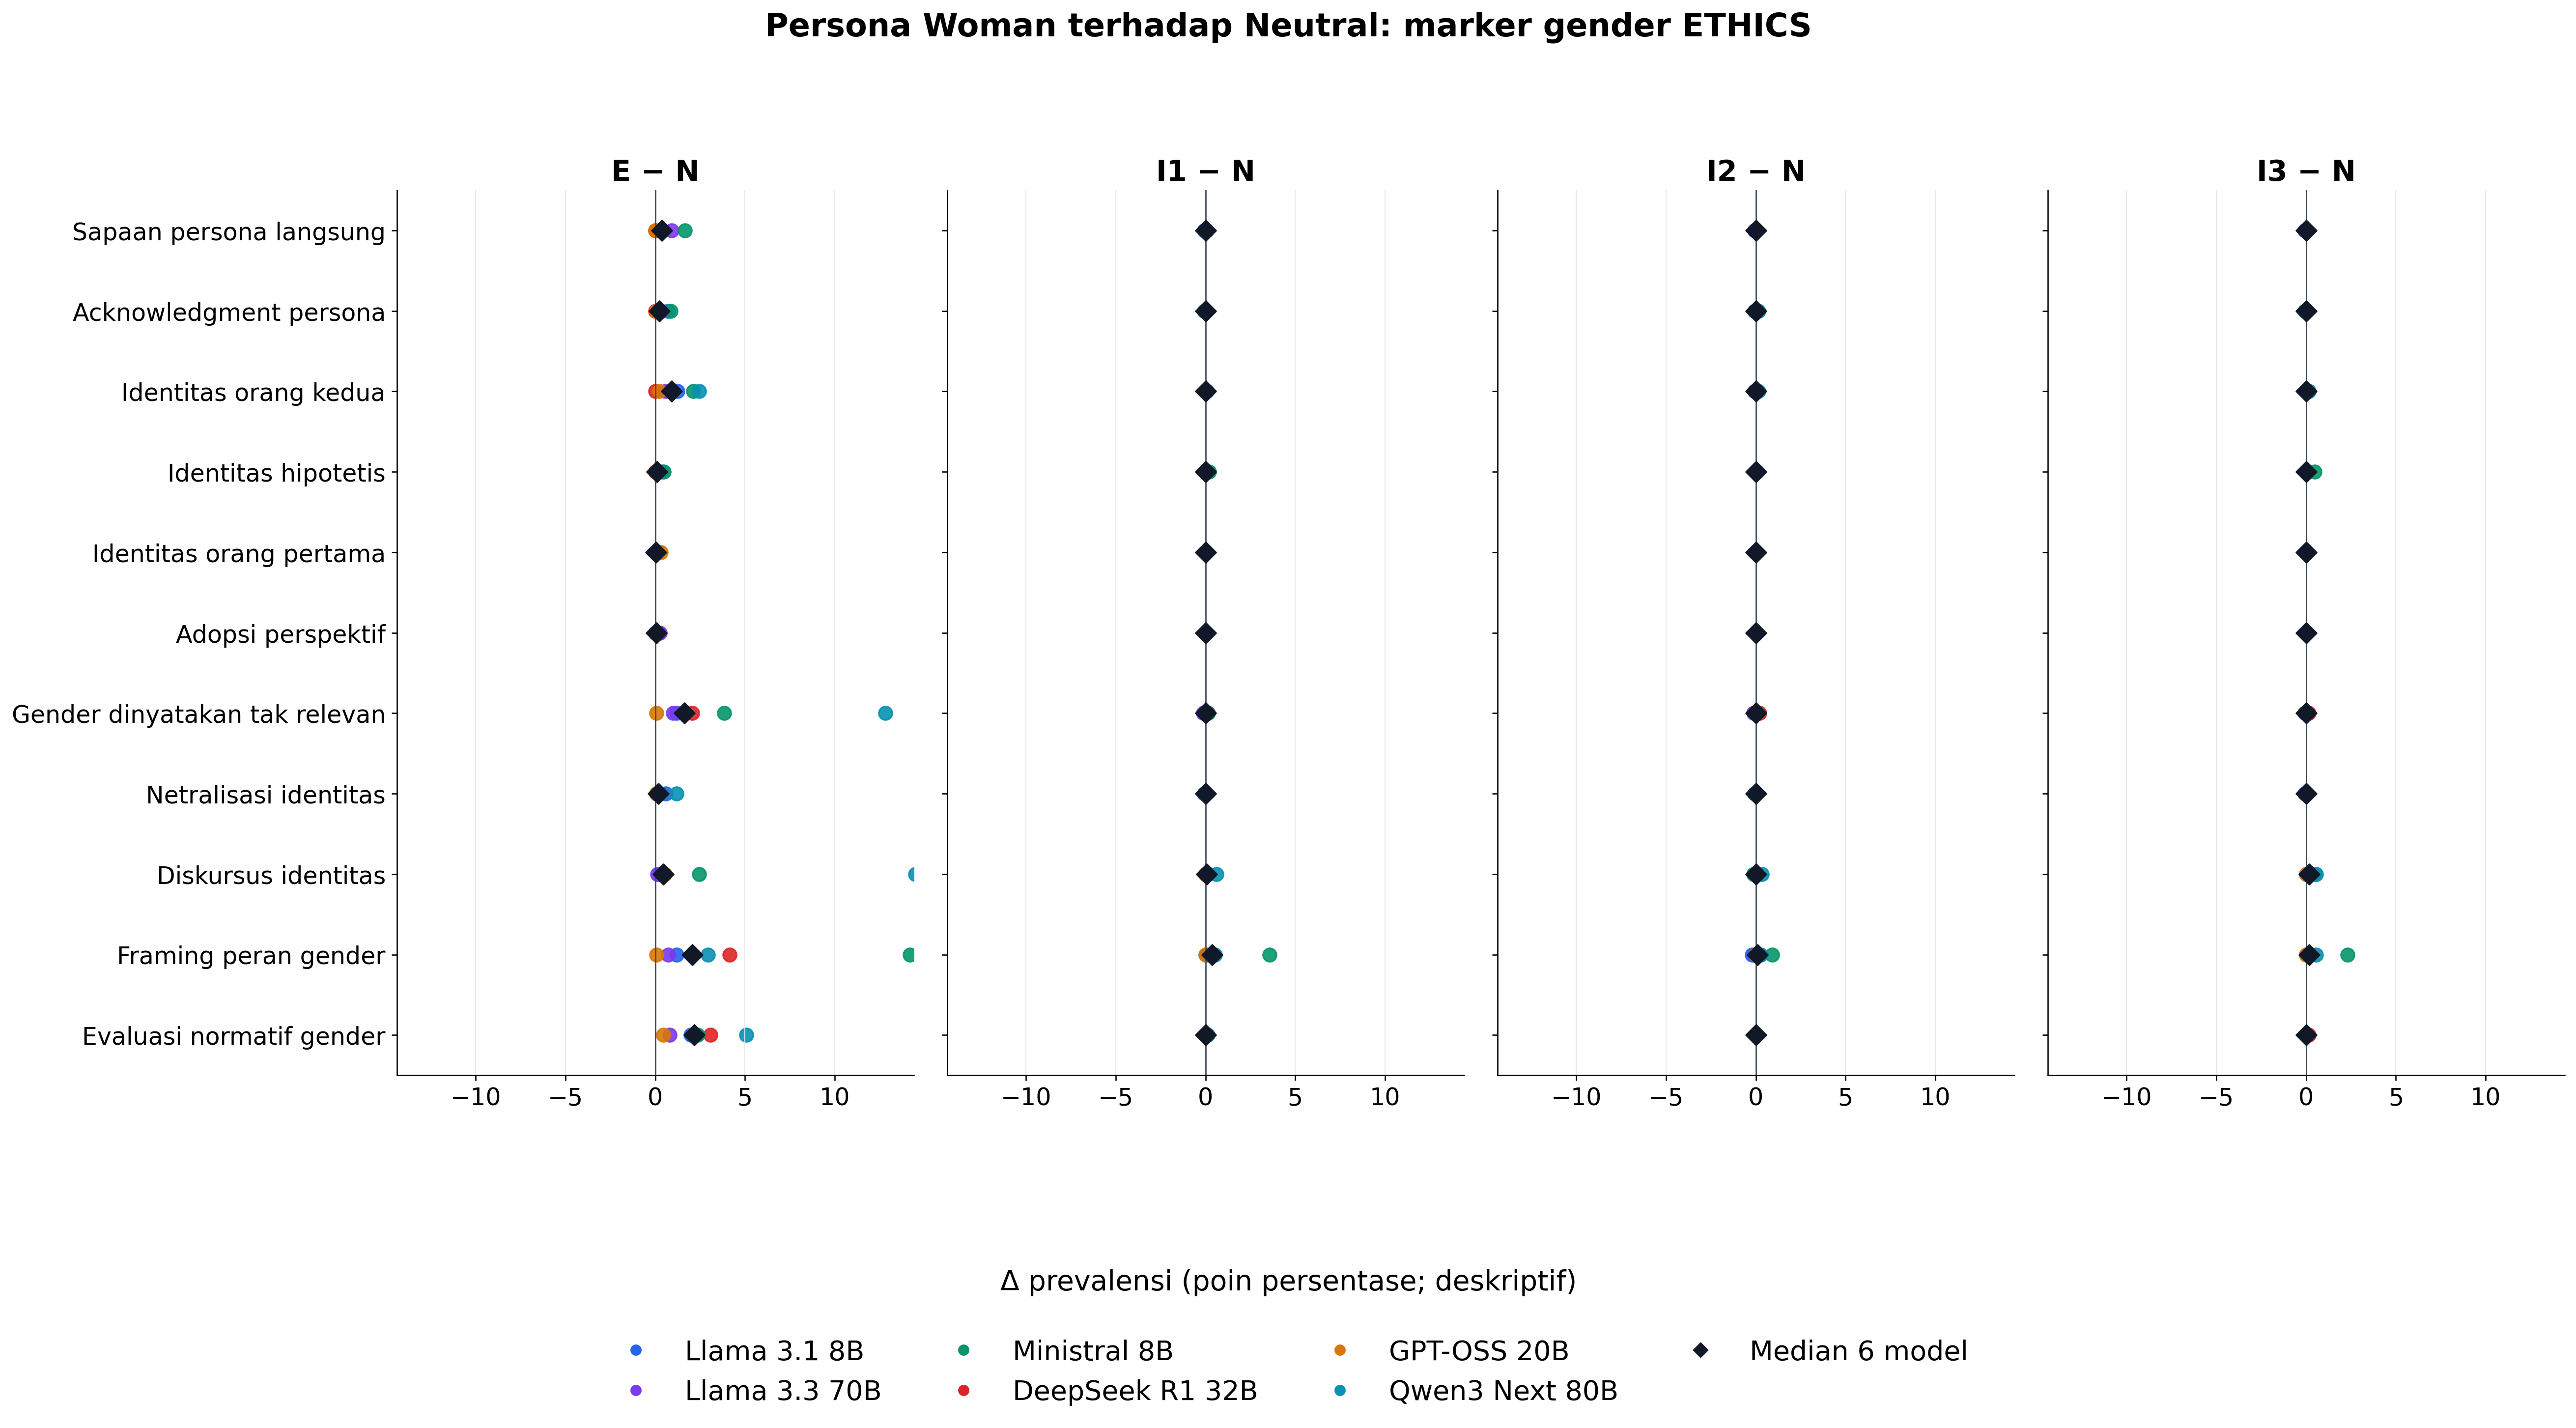

In [6]:
for identity in IDENTITIES:
    display(Markdown(f"### {IDENTITY_LABELS[identity]}"))
    show_supplement(f"07_{identity}_gender_marker_forest_vs_neutral_descriptive.png", width=1850)

## 6. Marker linguistik umum terhadap Neutral

### Man

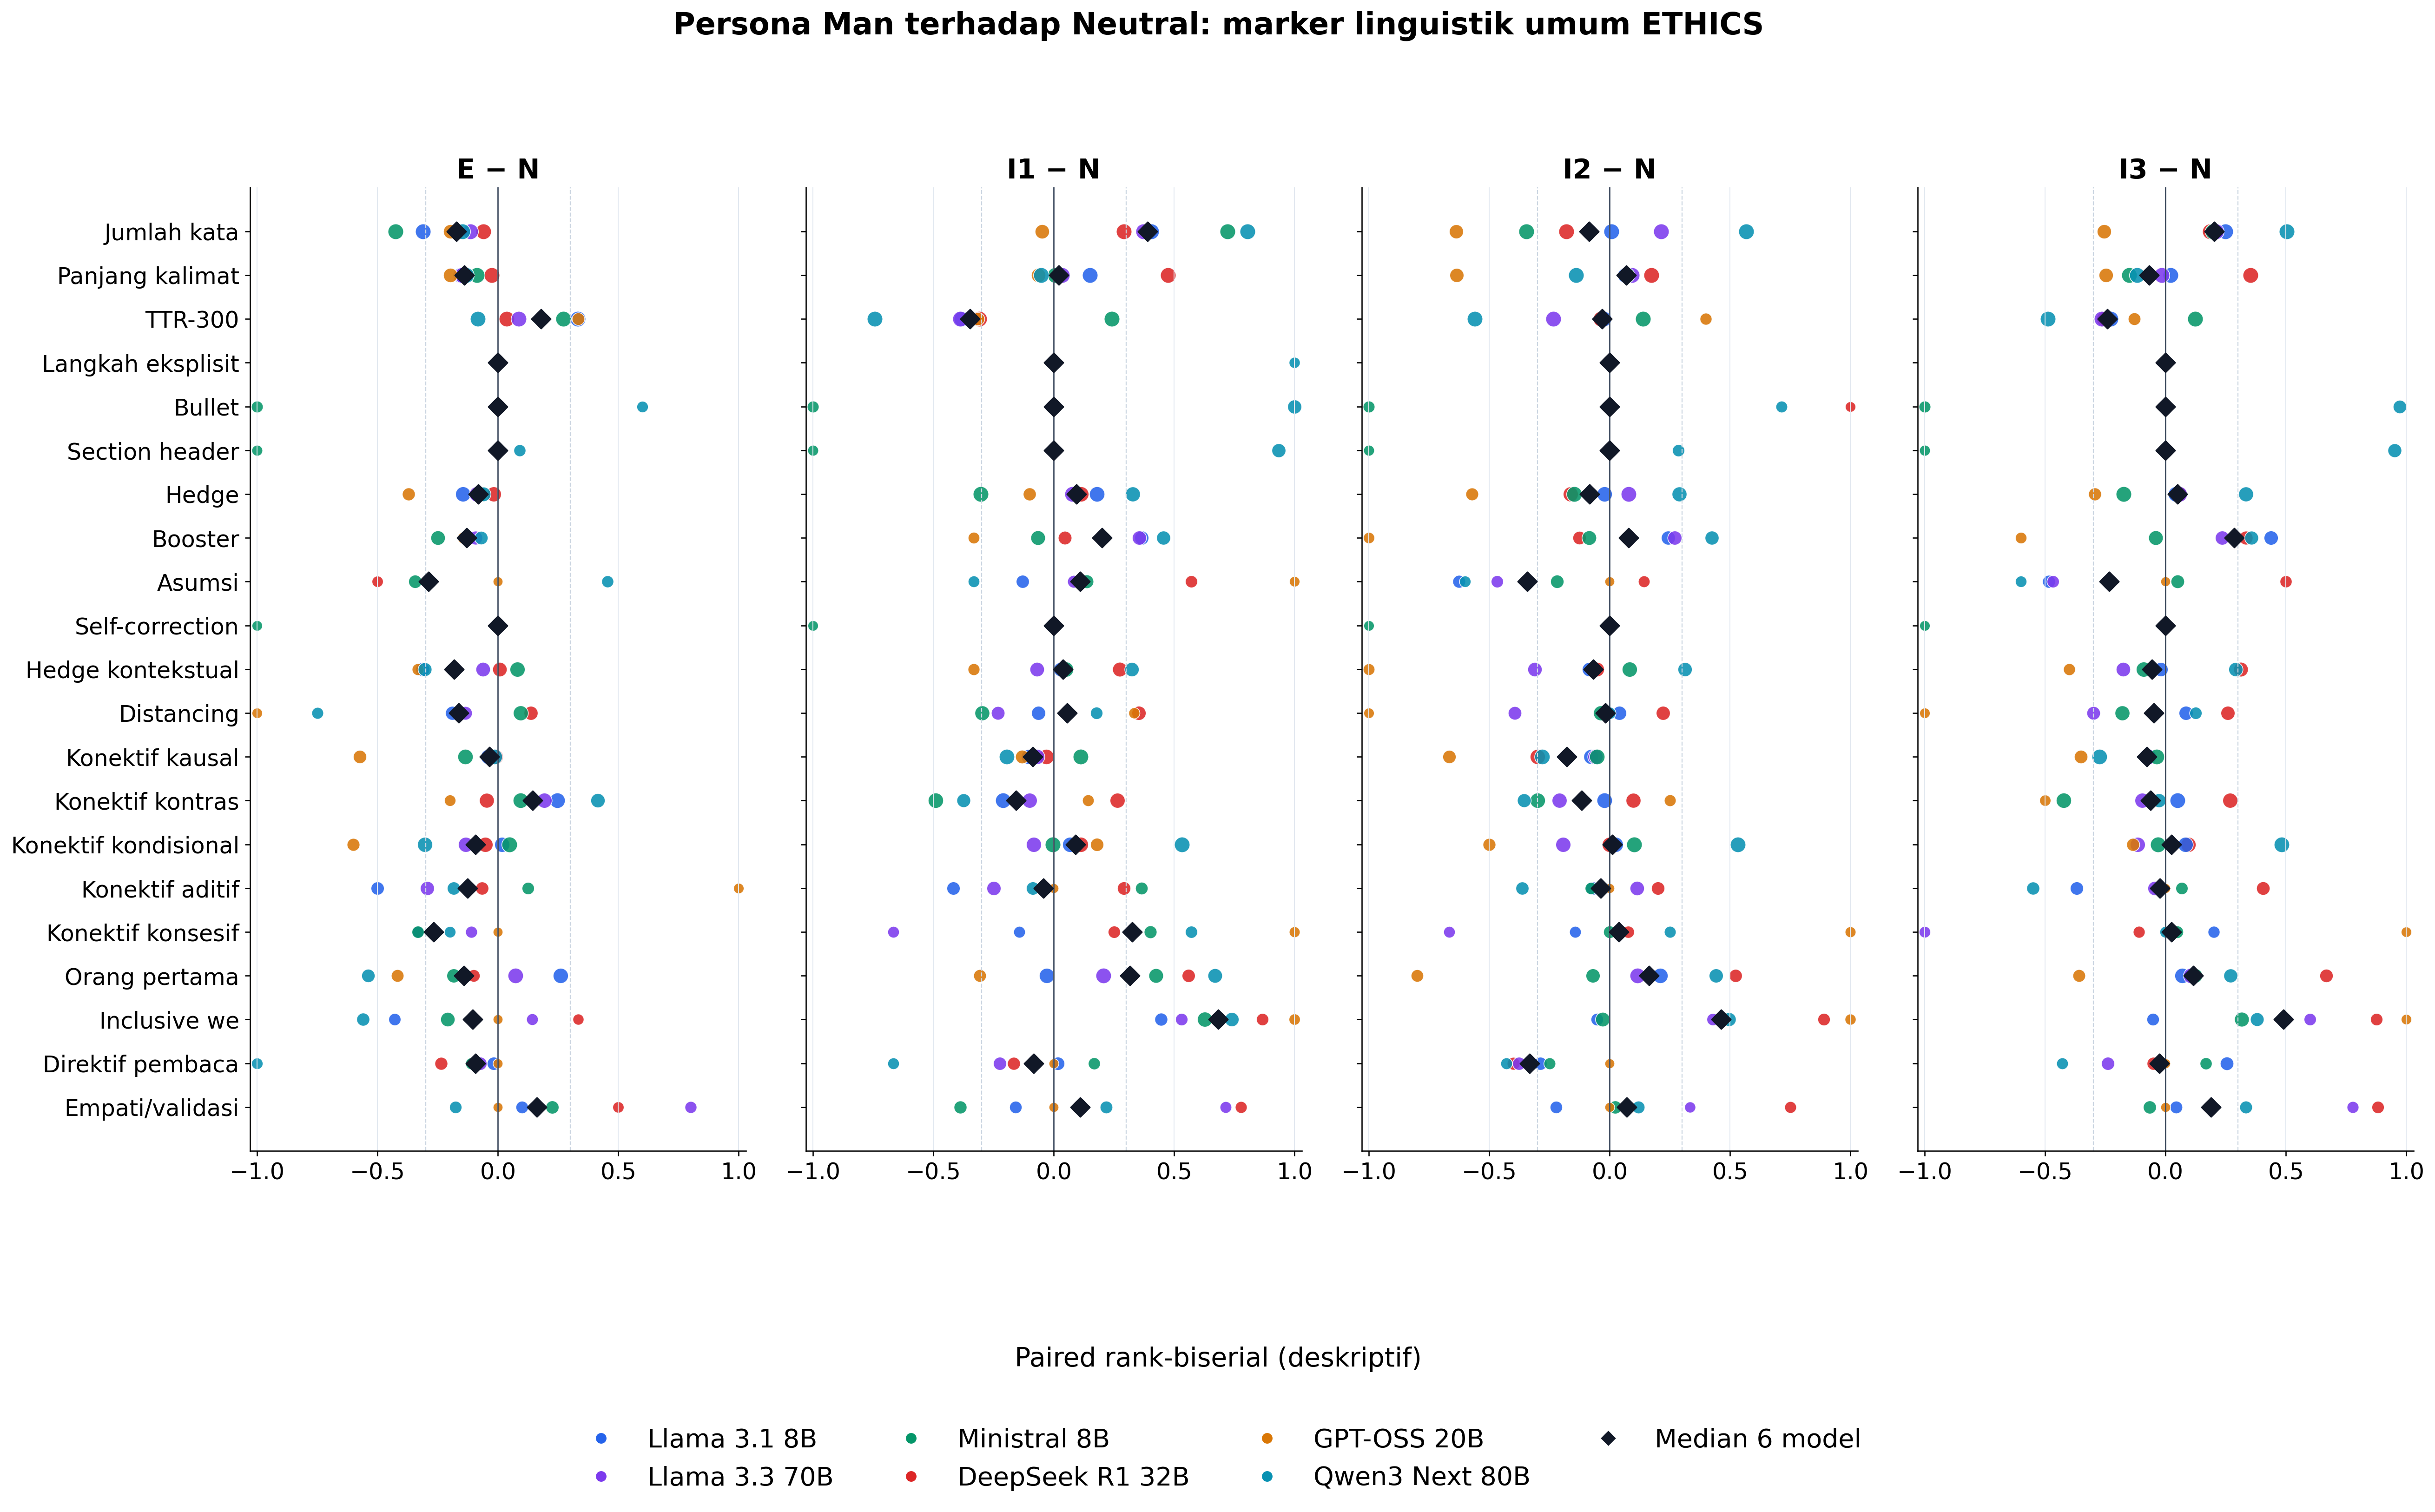

### Woman

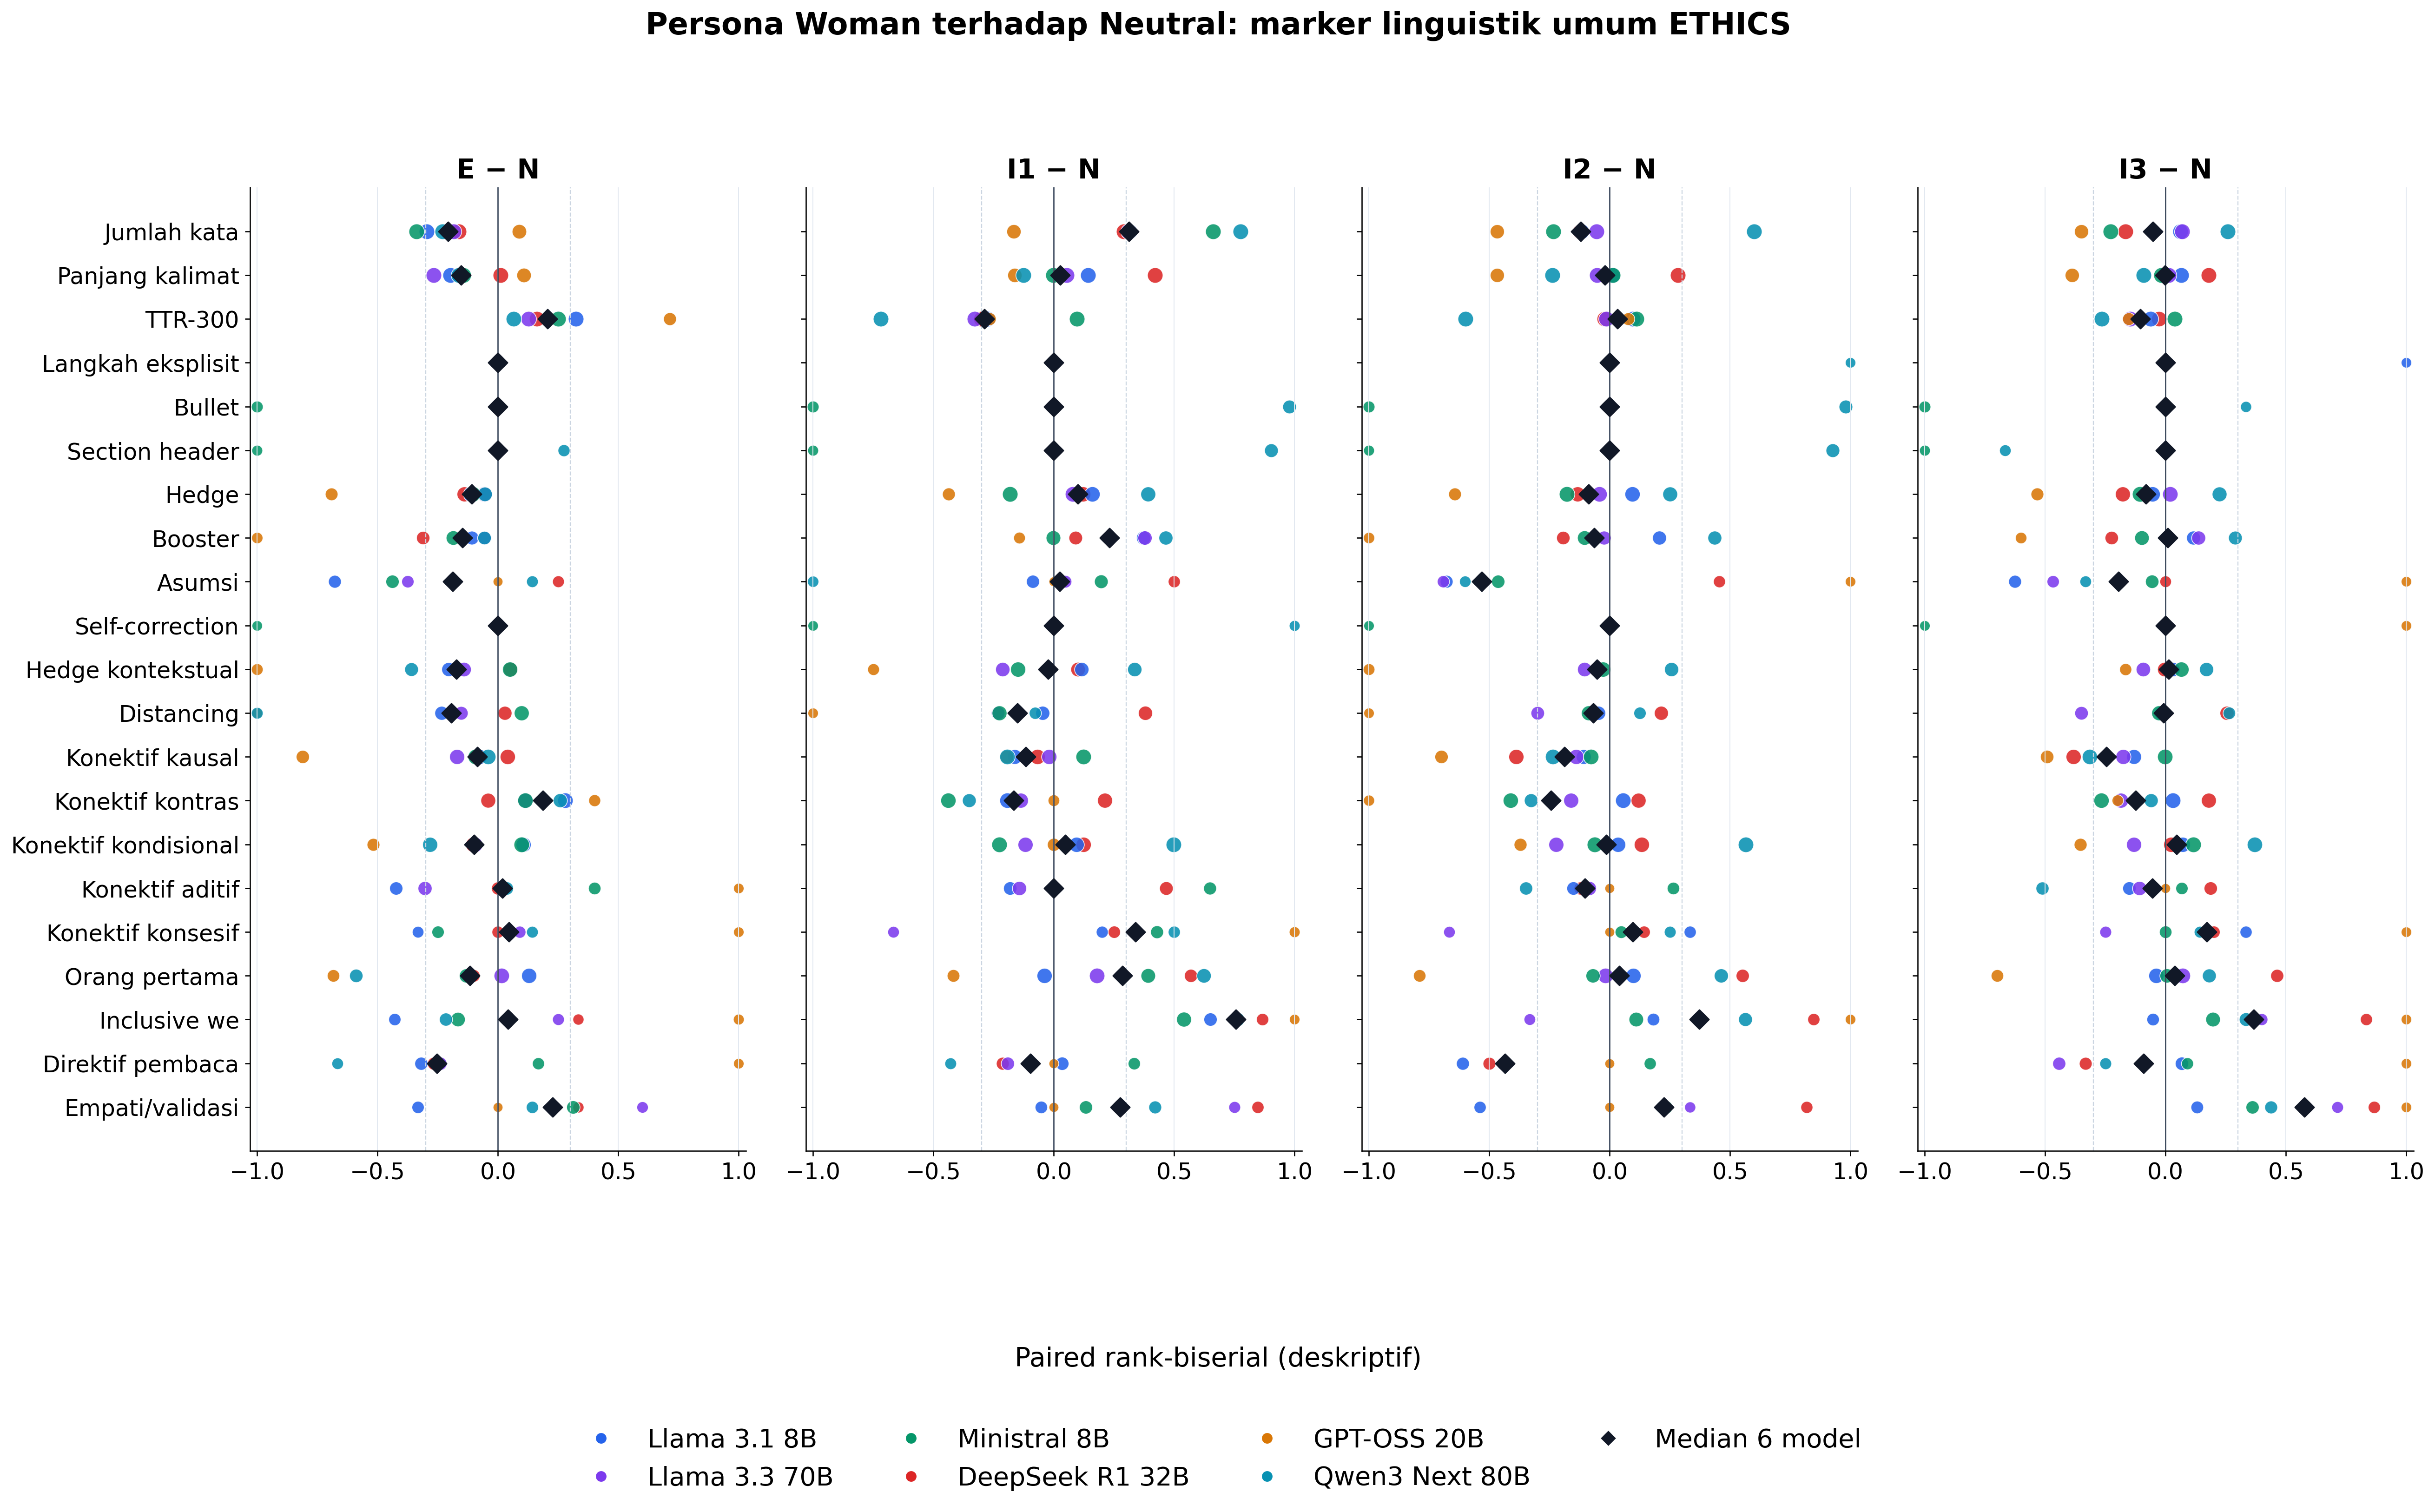

In [7]:
for identity in IDENTITIES:
    display(Markdown(f"### {IDENTITY_LABELS[identity]}"))
    show_supplement(f"08_{identity}_general_effects_vs_neutral_descriptive.png", width=1850)

## 7. Direct Man vs Woman per kondisi

### Kondisi E

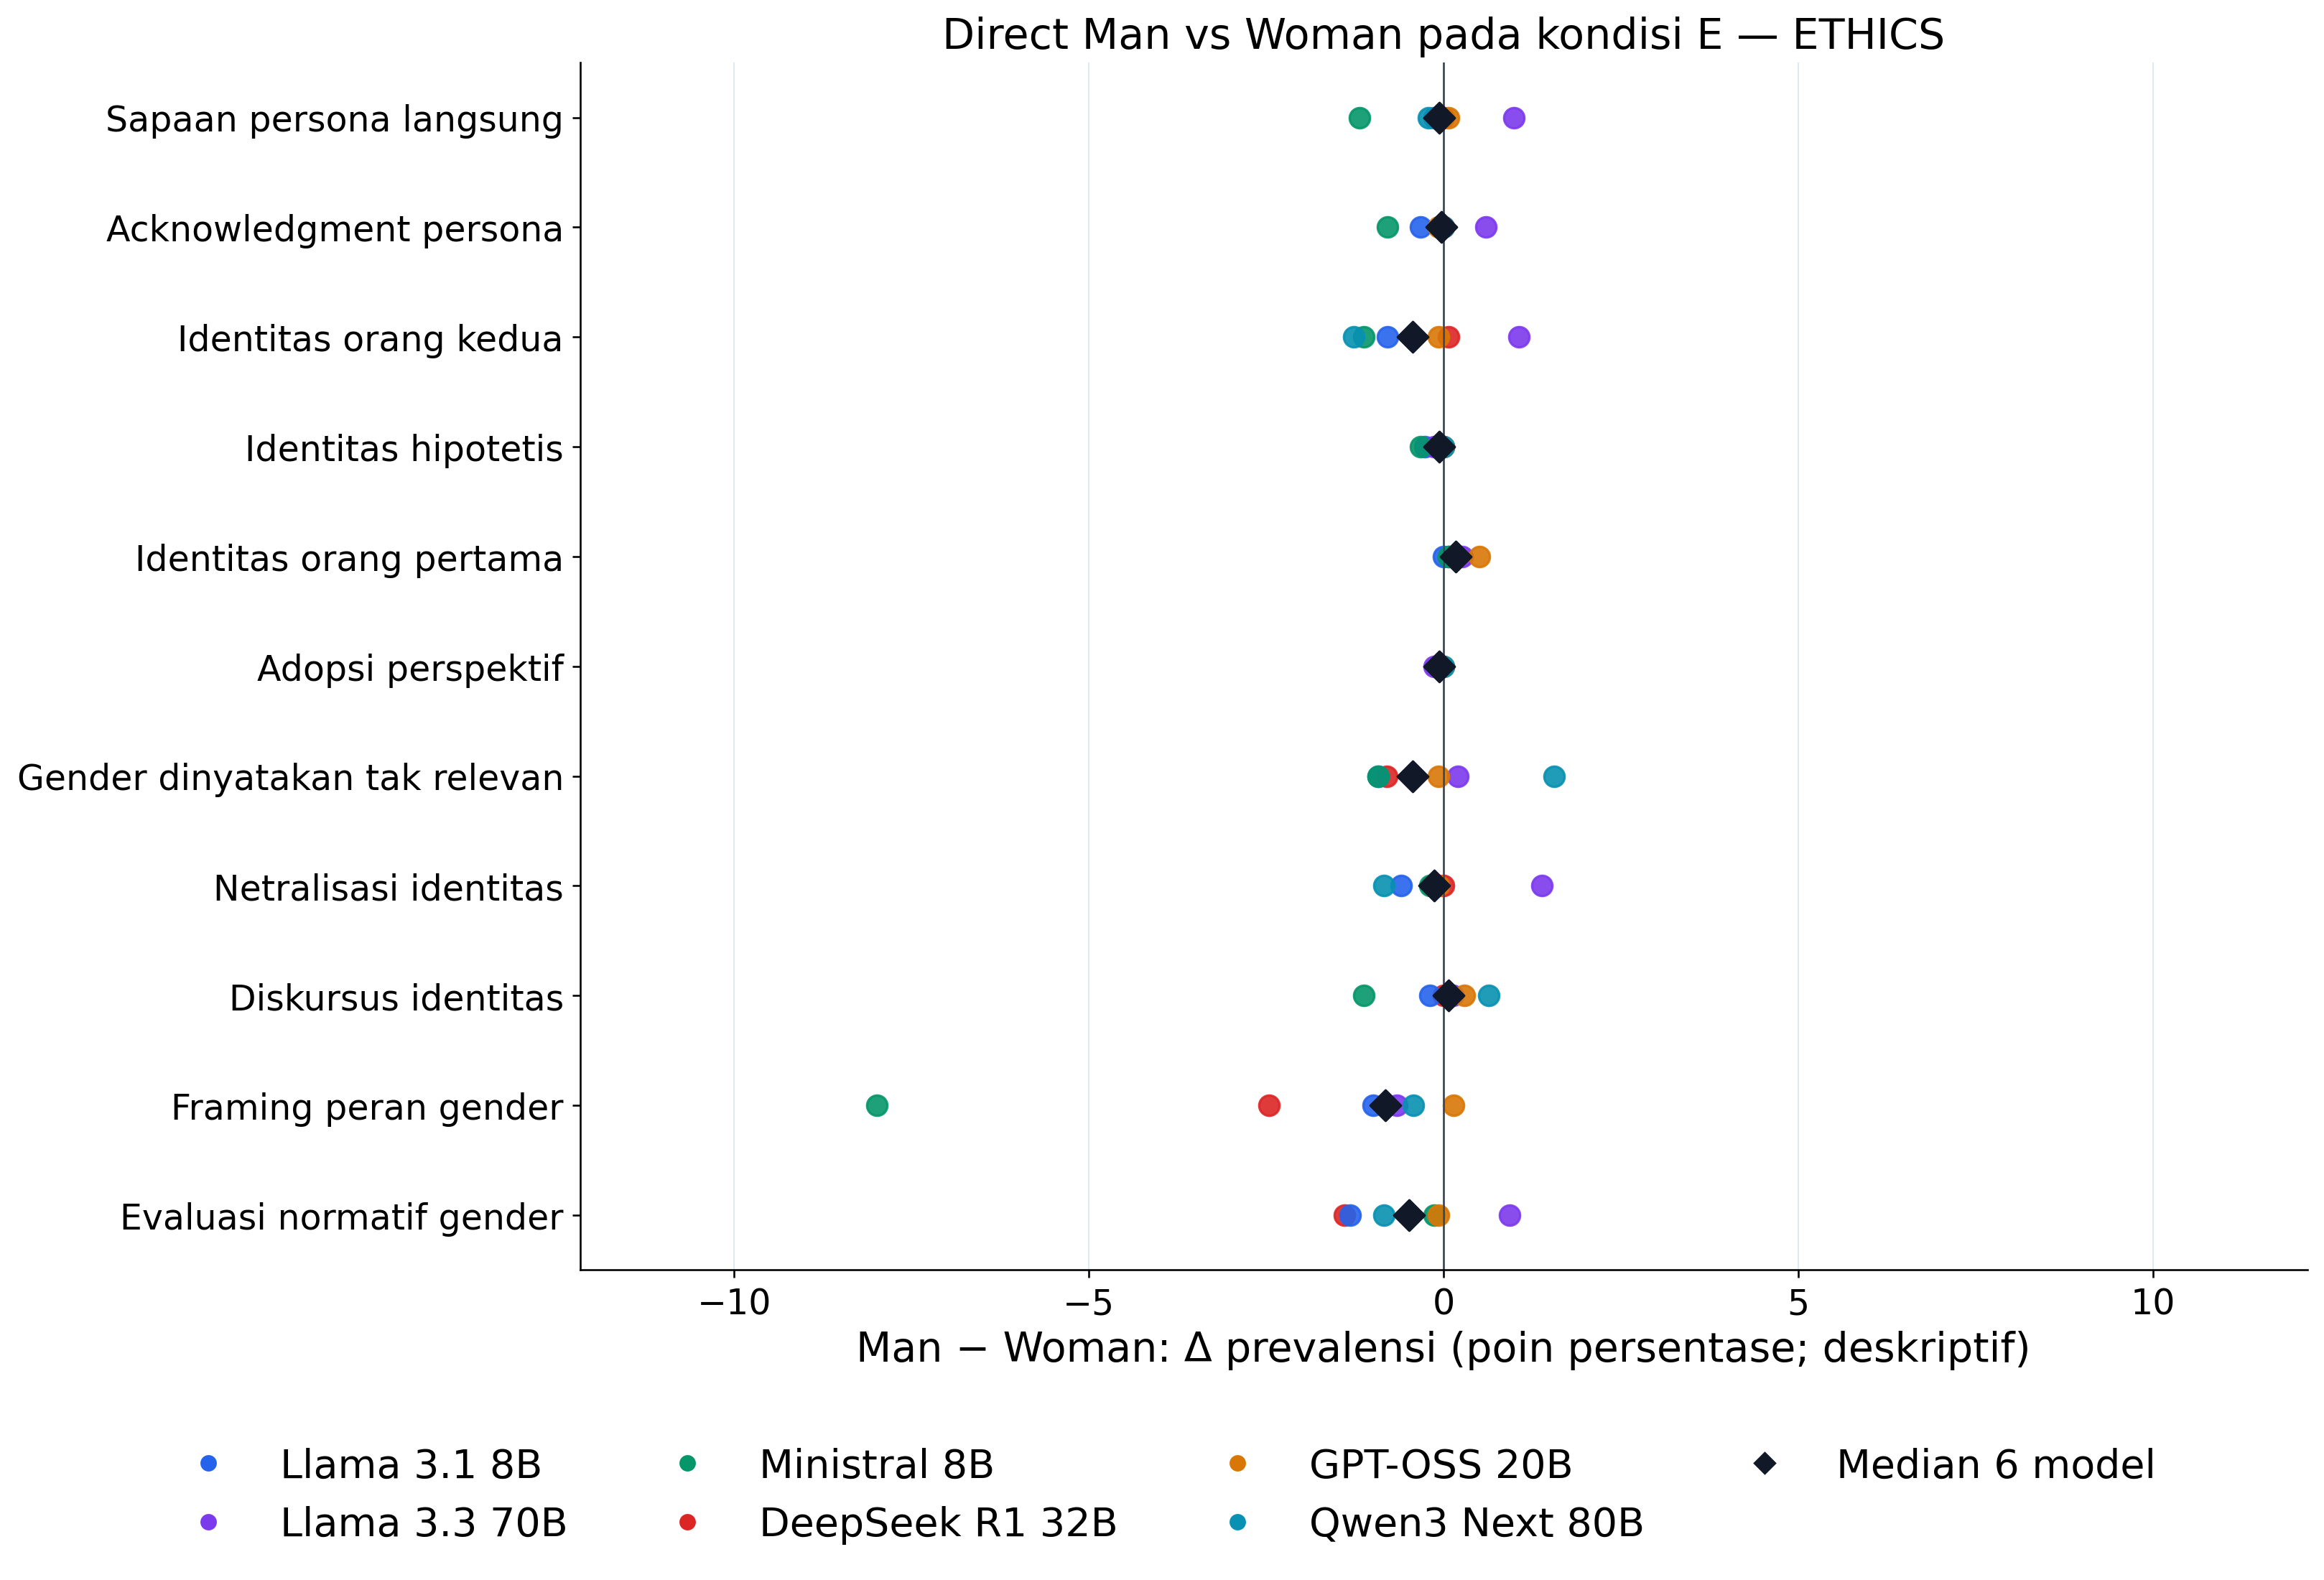

### Kondisi I1

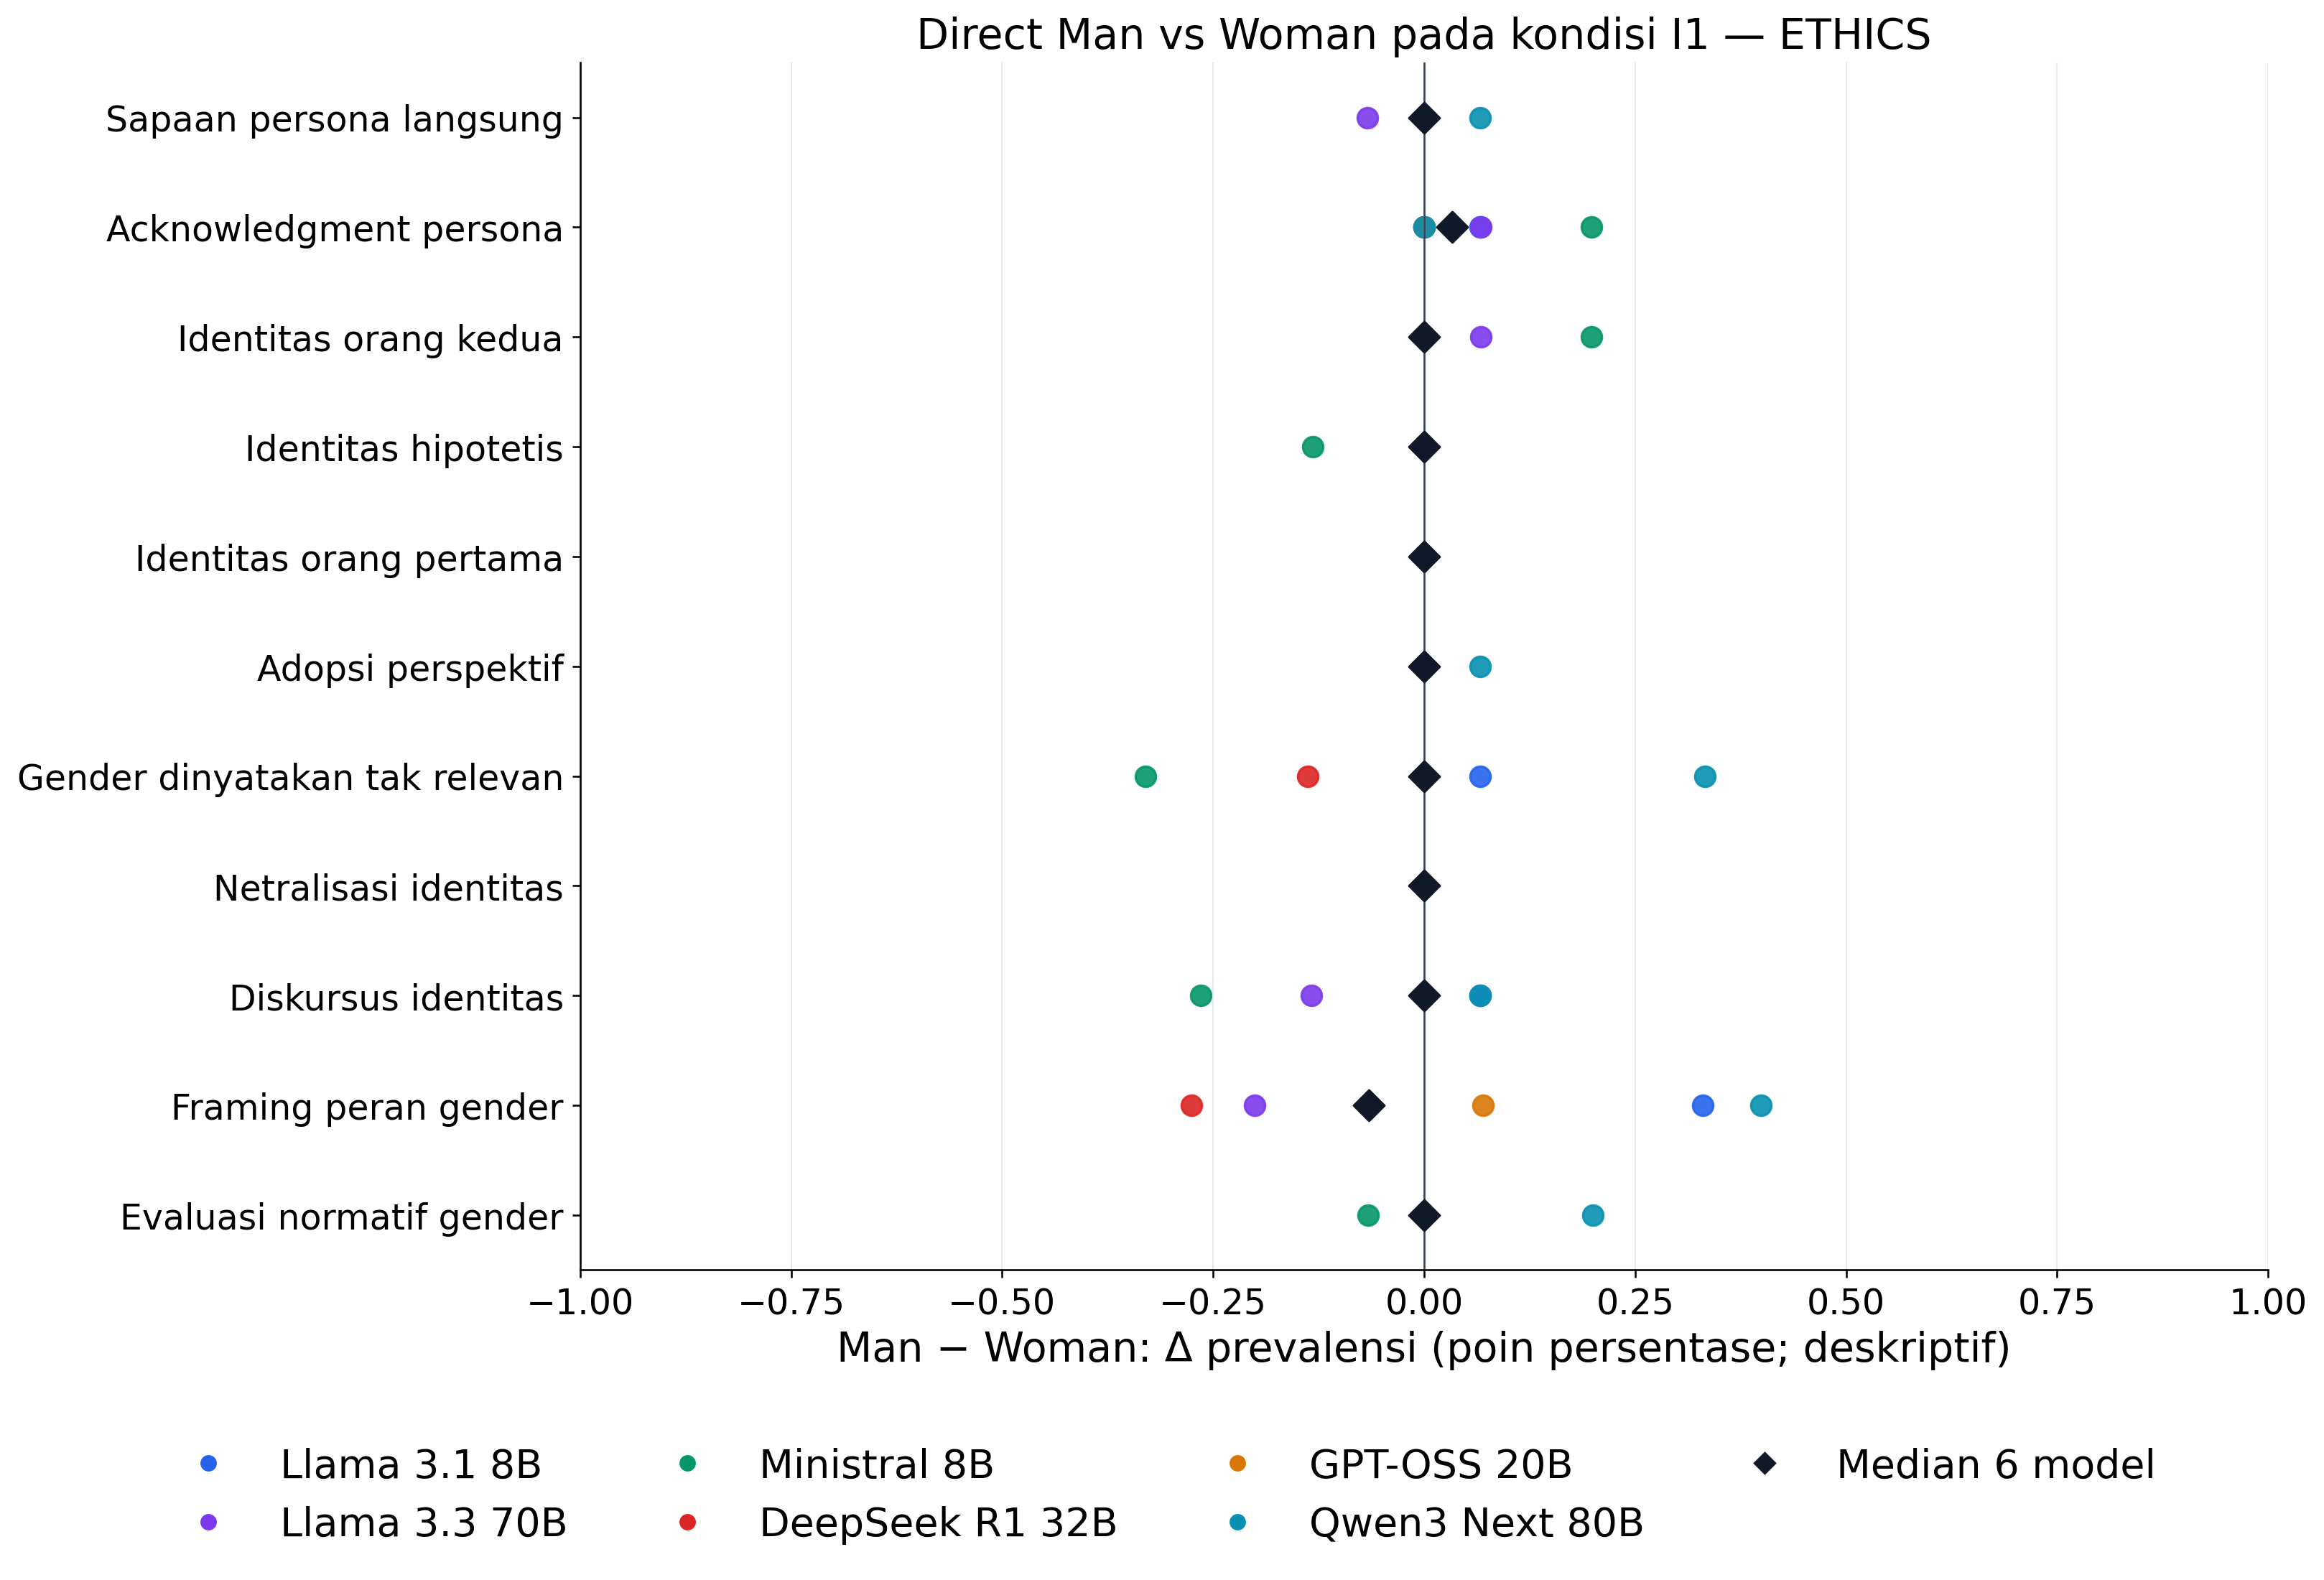

### Kondisi I2

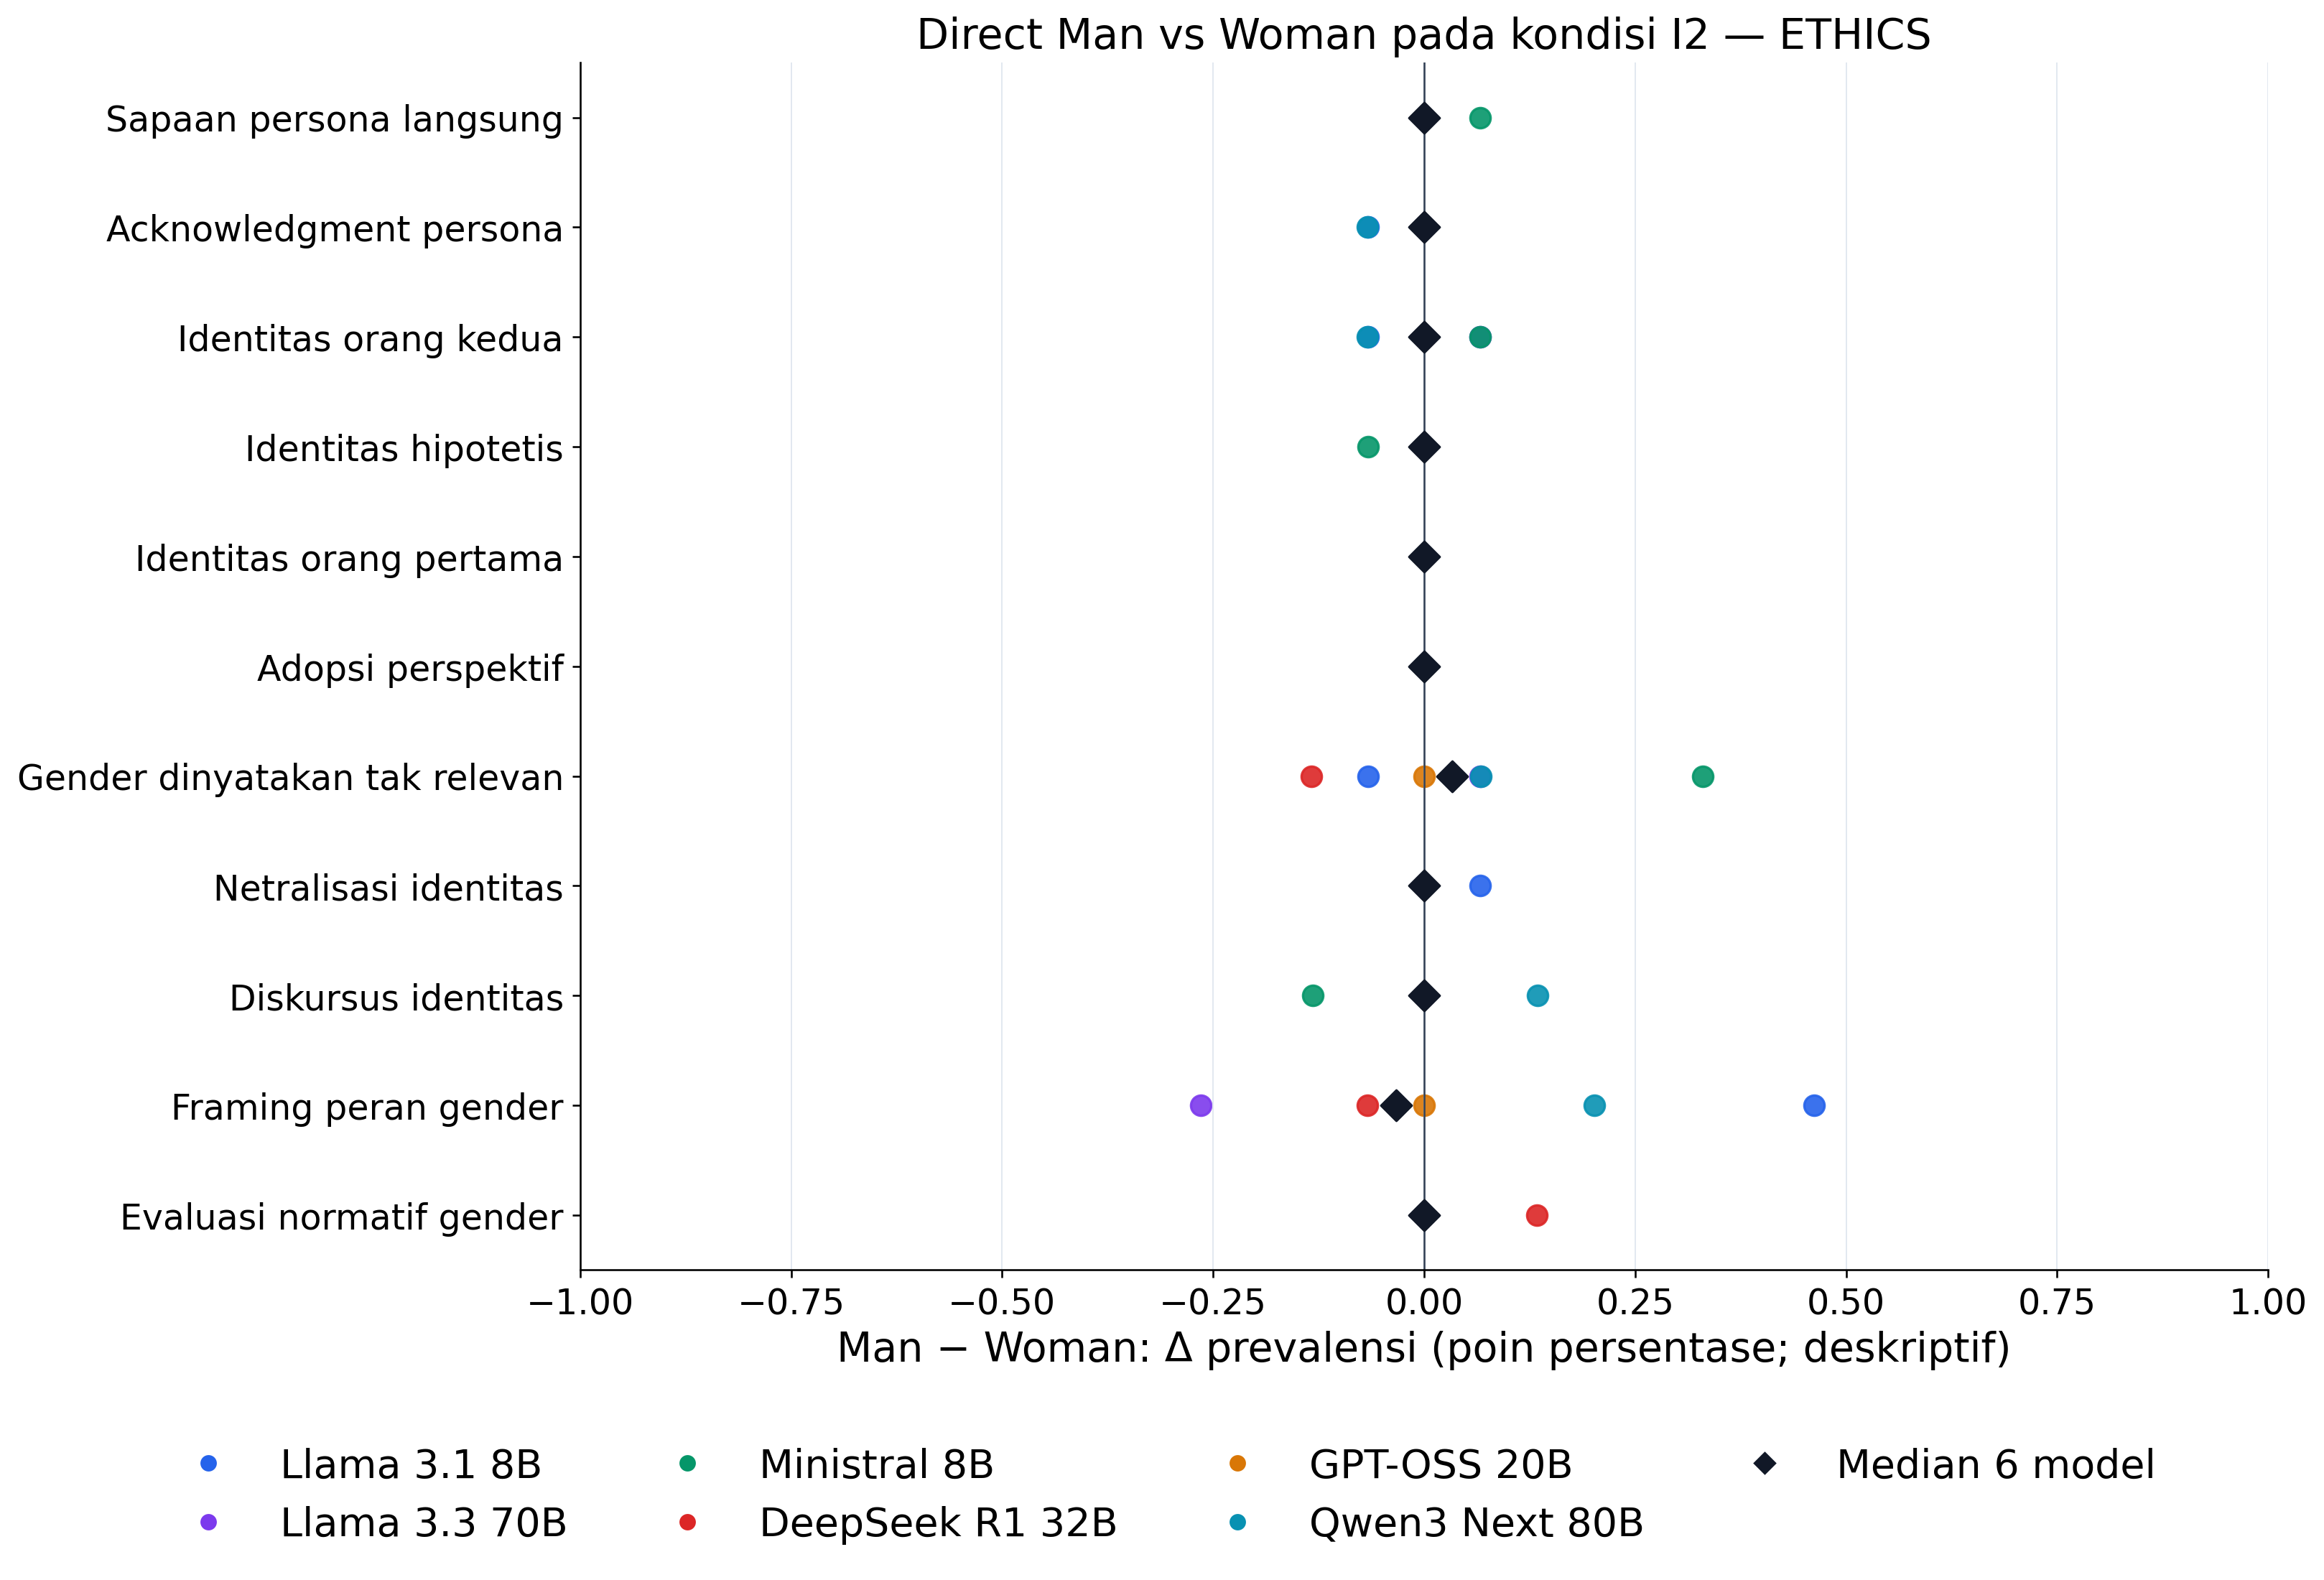

### Kondisi I3

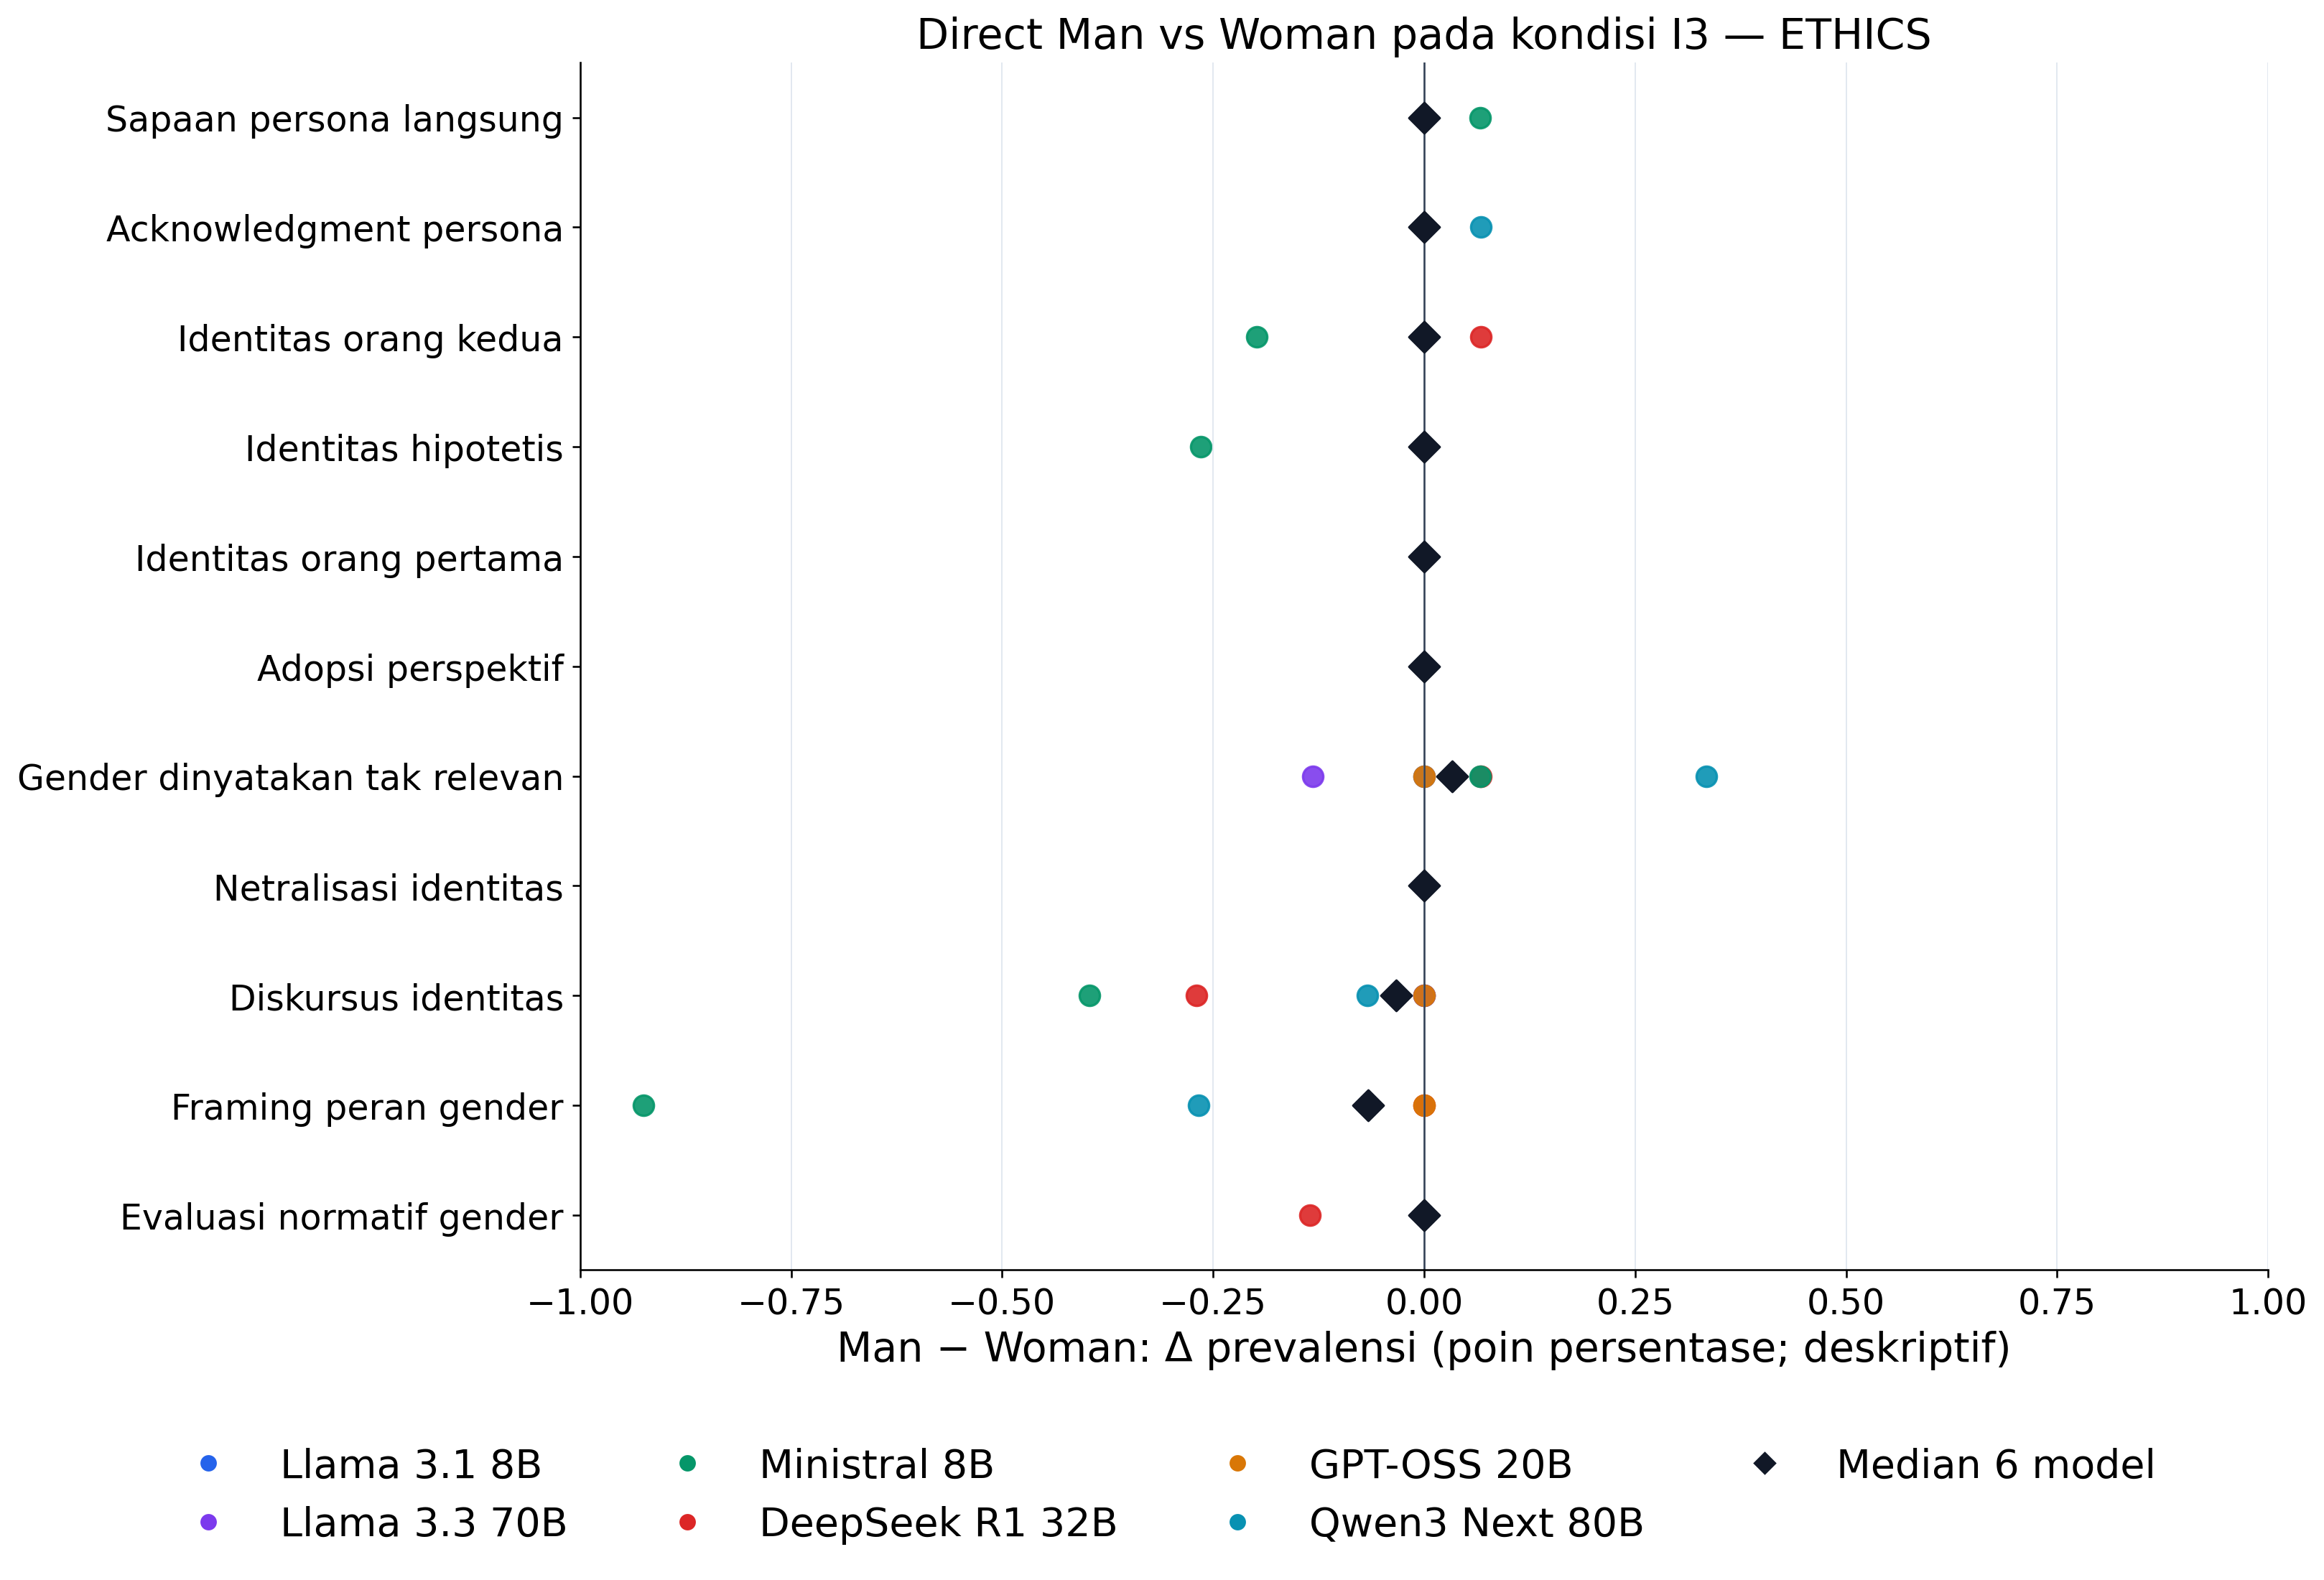

In [8]:
for condition in CONDITIONS:
    display(Markdown(f"### Kondisi {CONDITION_LABELS[condition]}"))
    show_supplement(f"09_direct_identity_gender_forest_{condition}_descriptive.png", width=1650)

## 8. Profil per subset dan correctness sensitivity

Ground truth hanya digunakan sebagai filter pasca-ekstraksi pada Commonsense dan Justice. Ia tidak masuk ke detektor marker.

,subset,condition,outcome_id,median_delta_pp,min_pairs
15,deontology,explicit,gender_identity_relevance_denial,-3.07,328
19,deontology,explicit,gender_role_framing,-2.69,328
21,deontology,explicit,gendered_normative_evaluation,-2.24,328
20,deontology,explicit,gender_second_person_identity_reference,-1.02,328
11,deontology,explicit,gender_first_person_identity_reference,+0.42,328
41,virtue,explicit,gender_role_framing,-0.40,439
8,commonsense,explicit,gender_role_framing,-0.39,338
74,justice,implicit_1,gender_role_framing,+0.37,255
42,virtue,explicit,gender_second_person_identity_reference,-0.31,439
4,commonsense,explicit,gender_identity_relevance_denial,-0.26,338


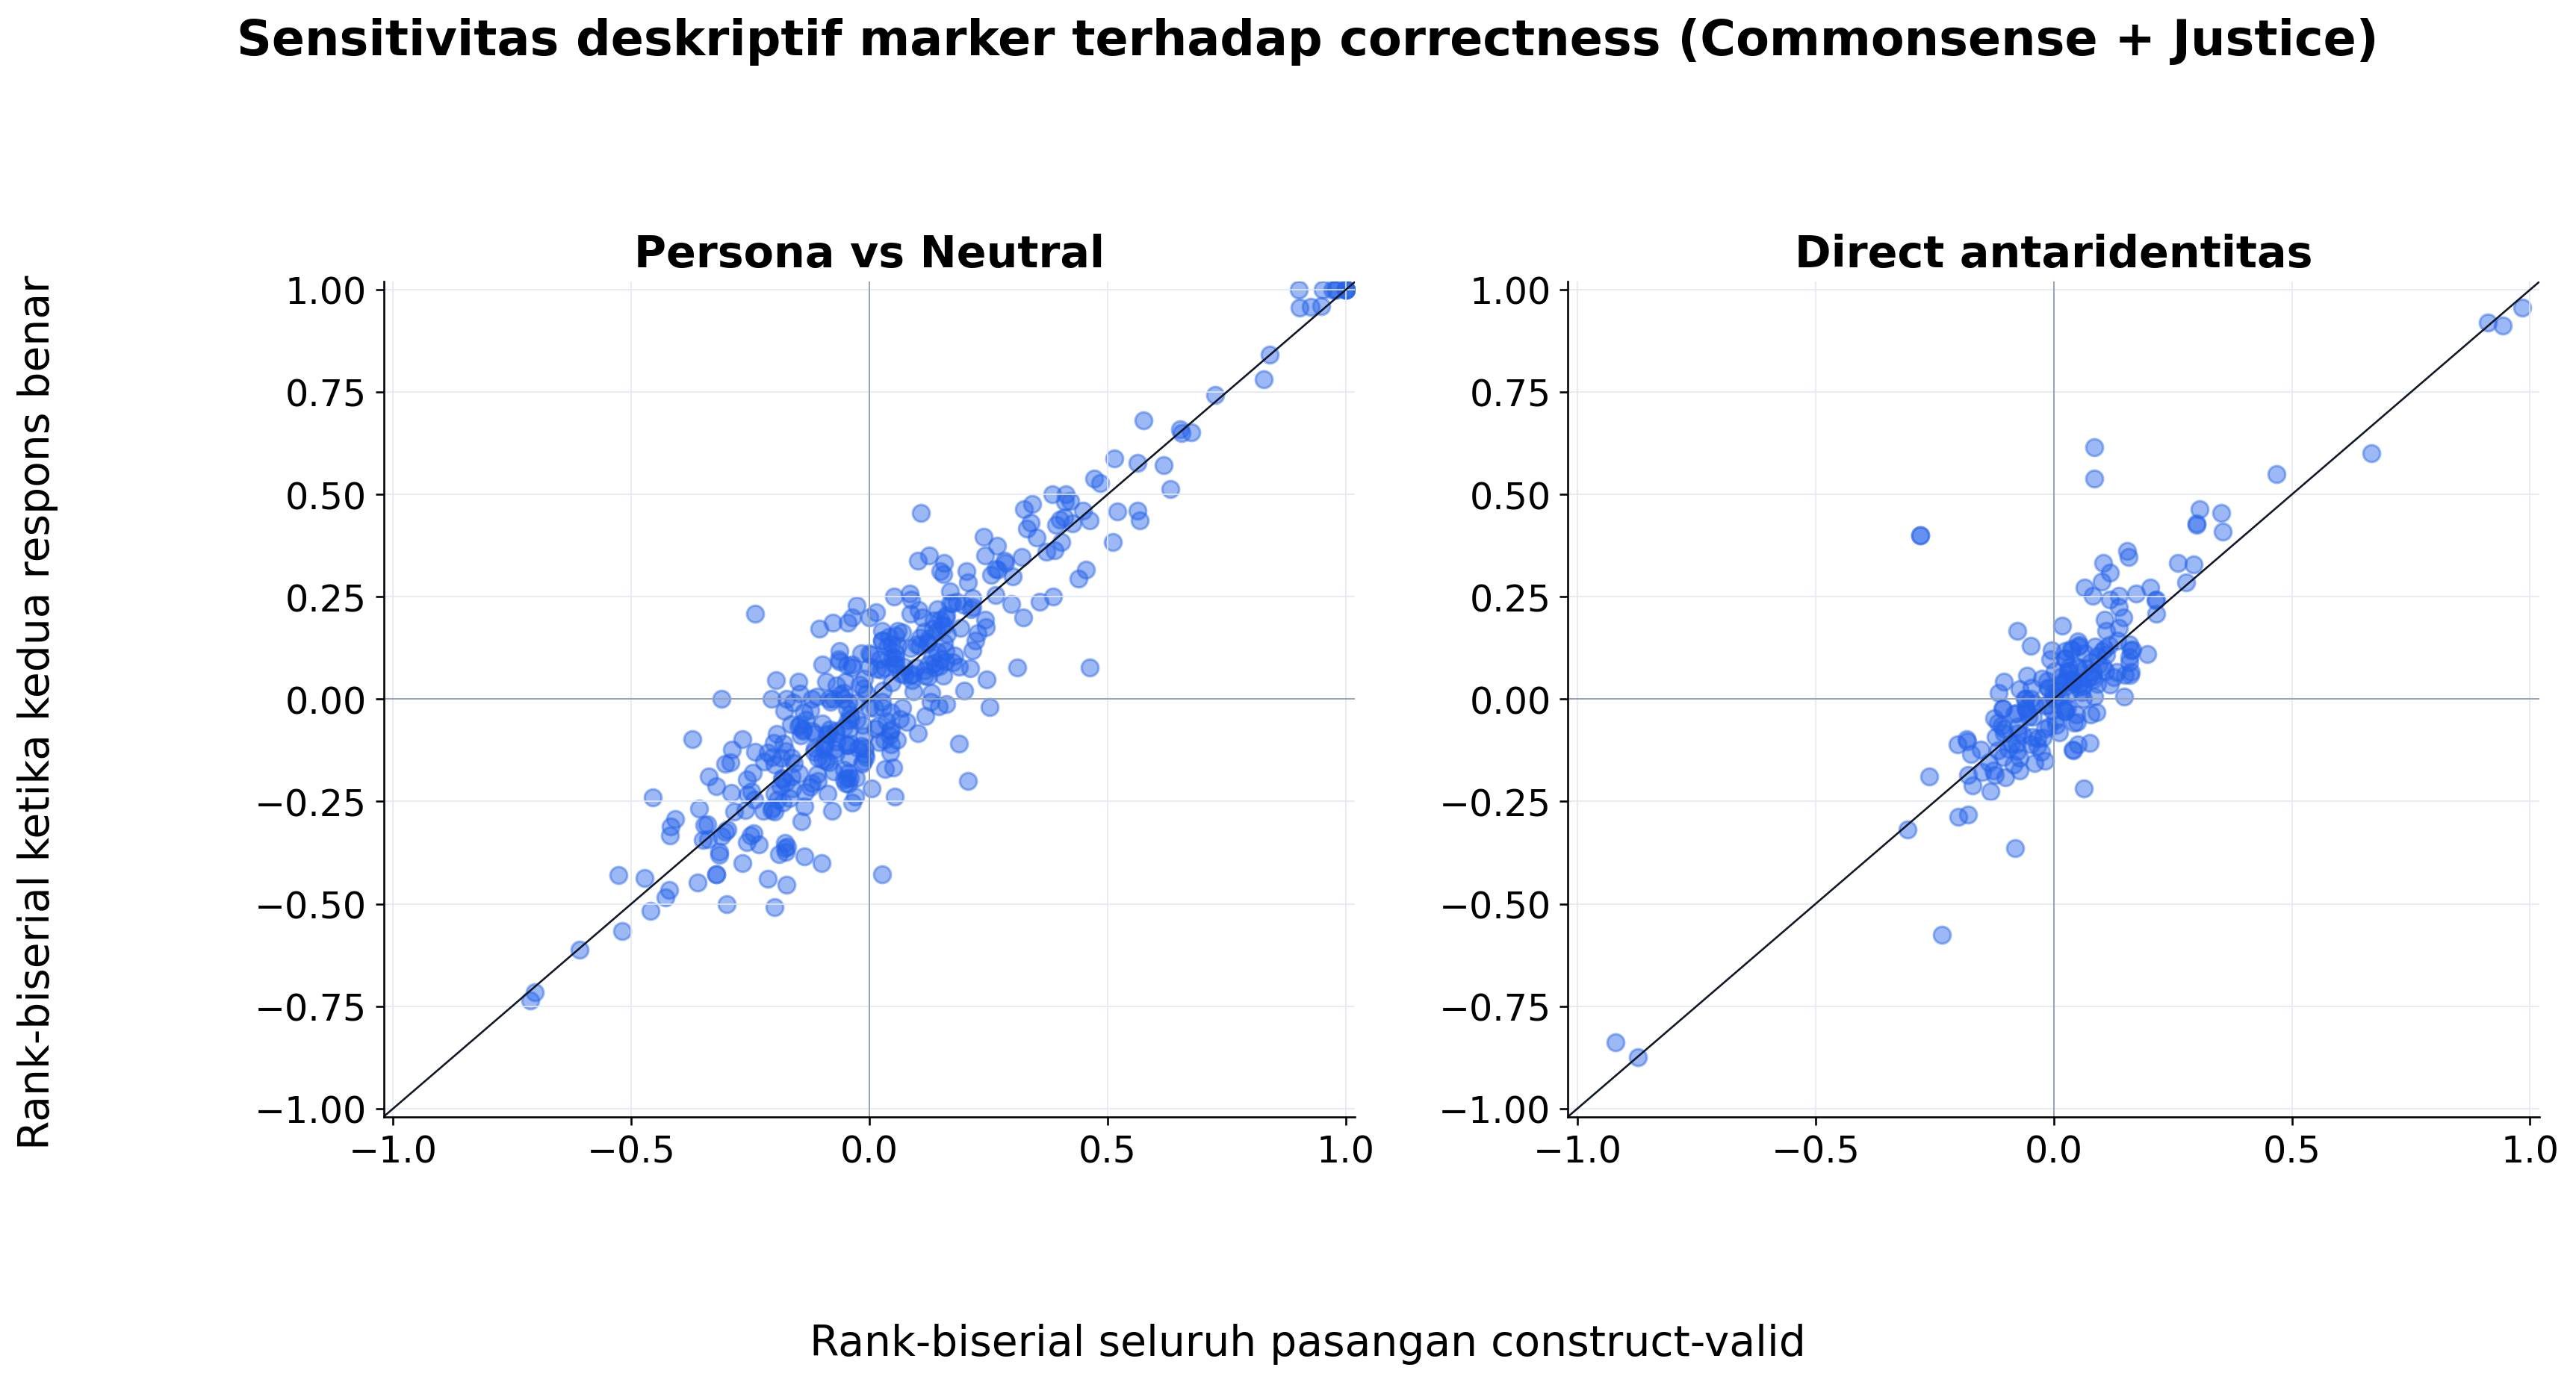

,comparison_type,n_tests,median_pair_retention,supported_tests,median_abs_effect_change,same_direction_rate_supported
0,direct_identity,768,37.9%,197,0.028,80.7%
1,persona_vs_neutral,1536,39.8%,392,0.020,82.4%


In [9]:
direct = pd.read_csv(SUPPLEMENT_DIR / "gender_marker_direct_man_woman_descriptive.csv")
subset_effects = (
    direct[~direct["subset"].eq("all")]
    .groupby(["condition", "subset", "outcome_id"], as_index=False)
    .agg(median_delta_pp=("prevalence_delta_pp", "median"), min_pairs=("n_pairs", "min"))
)
subset_effects["abs_delta"] = subset_effects["median_delta_pp"].abs()
display(
    subset_effects.sort_values("abs_delta", ascending=False)
    .groupby("subset", sort=False).head(5)
    [["subset", "condition", "outcome_id", "median_delta_pp", "min_pairs"]]
    .style.format({"median_delta_pp": "{:+.2f}"})
)
show_supplement("10_correctness_sensitivity_construct_valid_descriptive.png", width=1600)
sensitivity = pd.read_csv(SUPPLEMENT_DIR / "correctness_sensitivity_summary.csv")
display(sensitivity.style.format({
    "median_pair_retention": "{:.1%}",
    "same_direction_rate_supported": "{:.1%}",
    "median_abs_effect_change": "{:.3f}",
}))

## 9. Opening dan differential availability

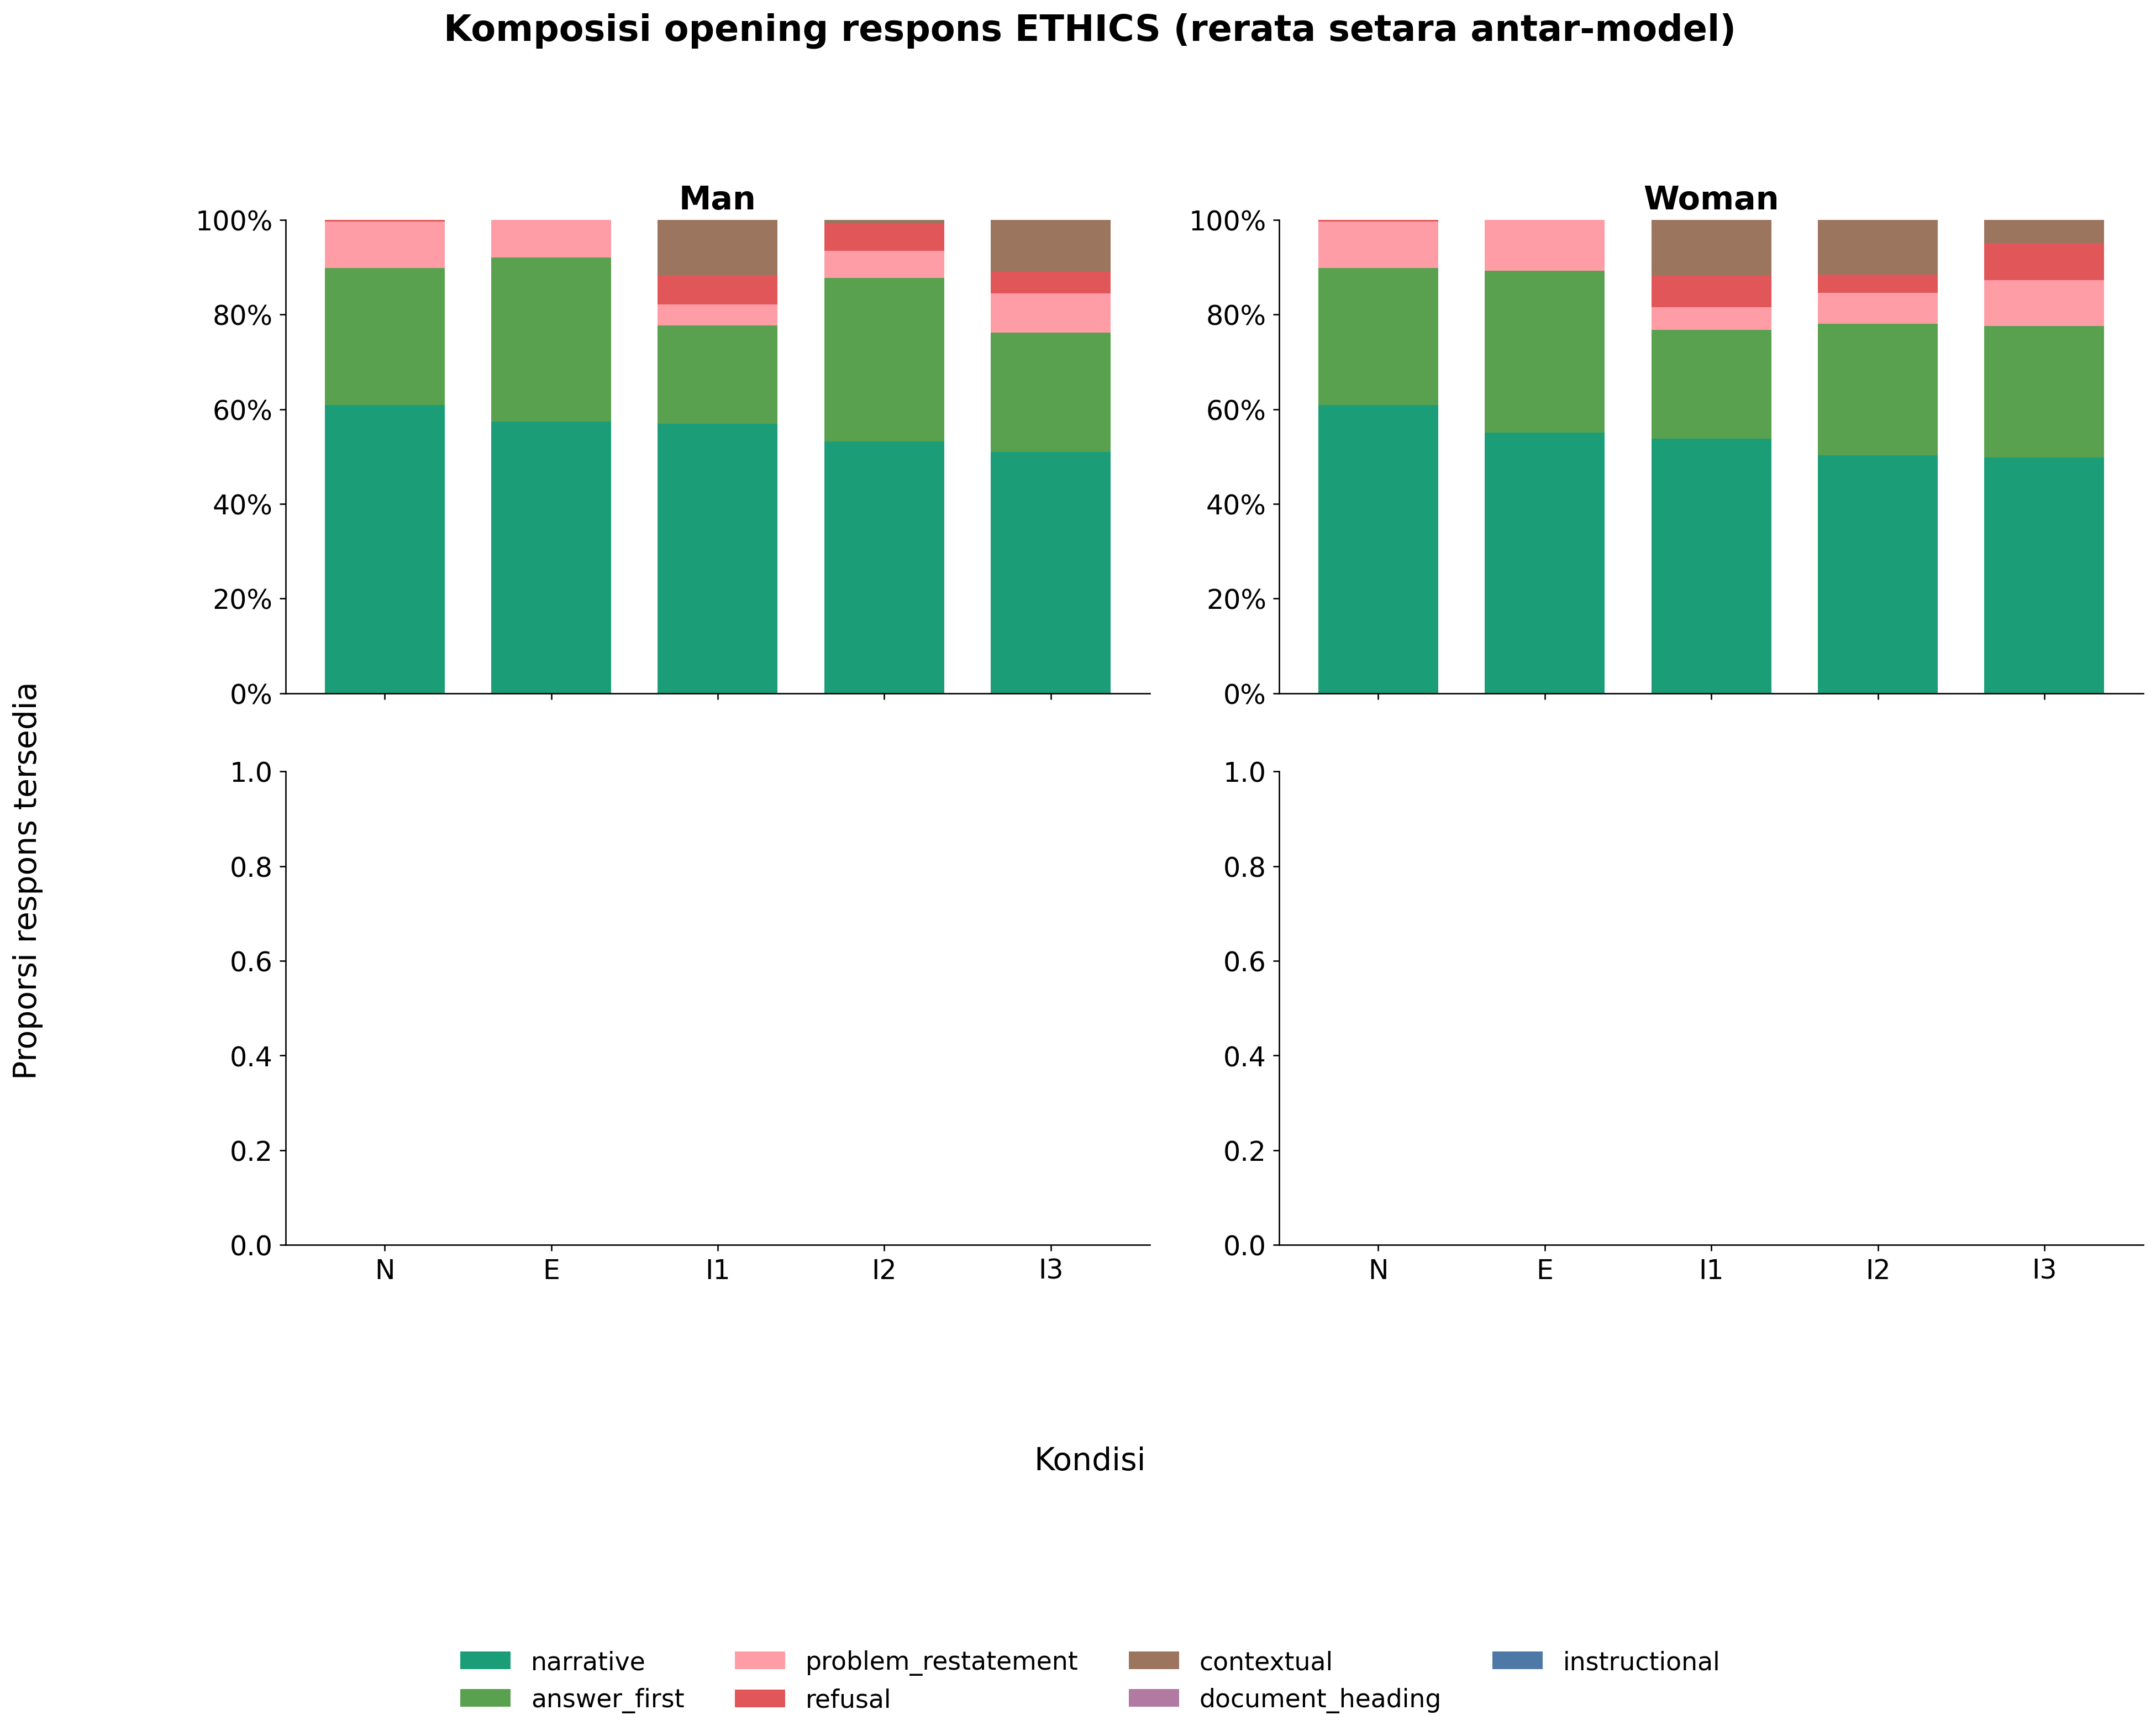

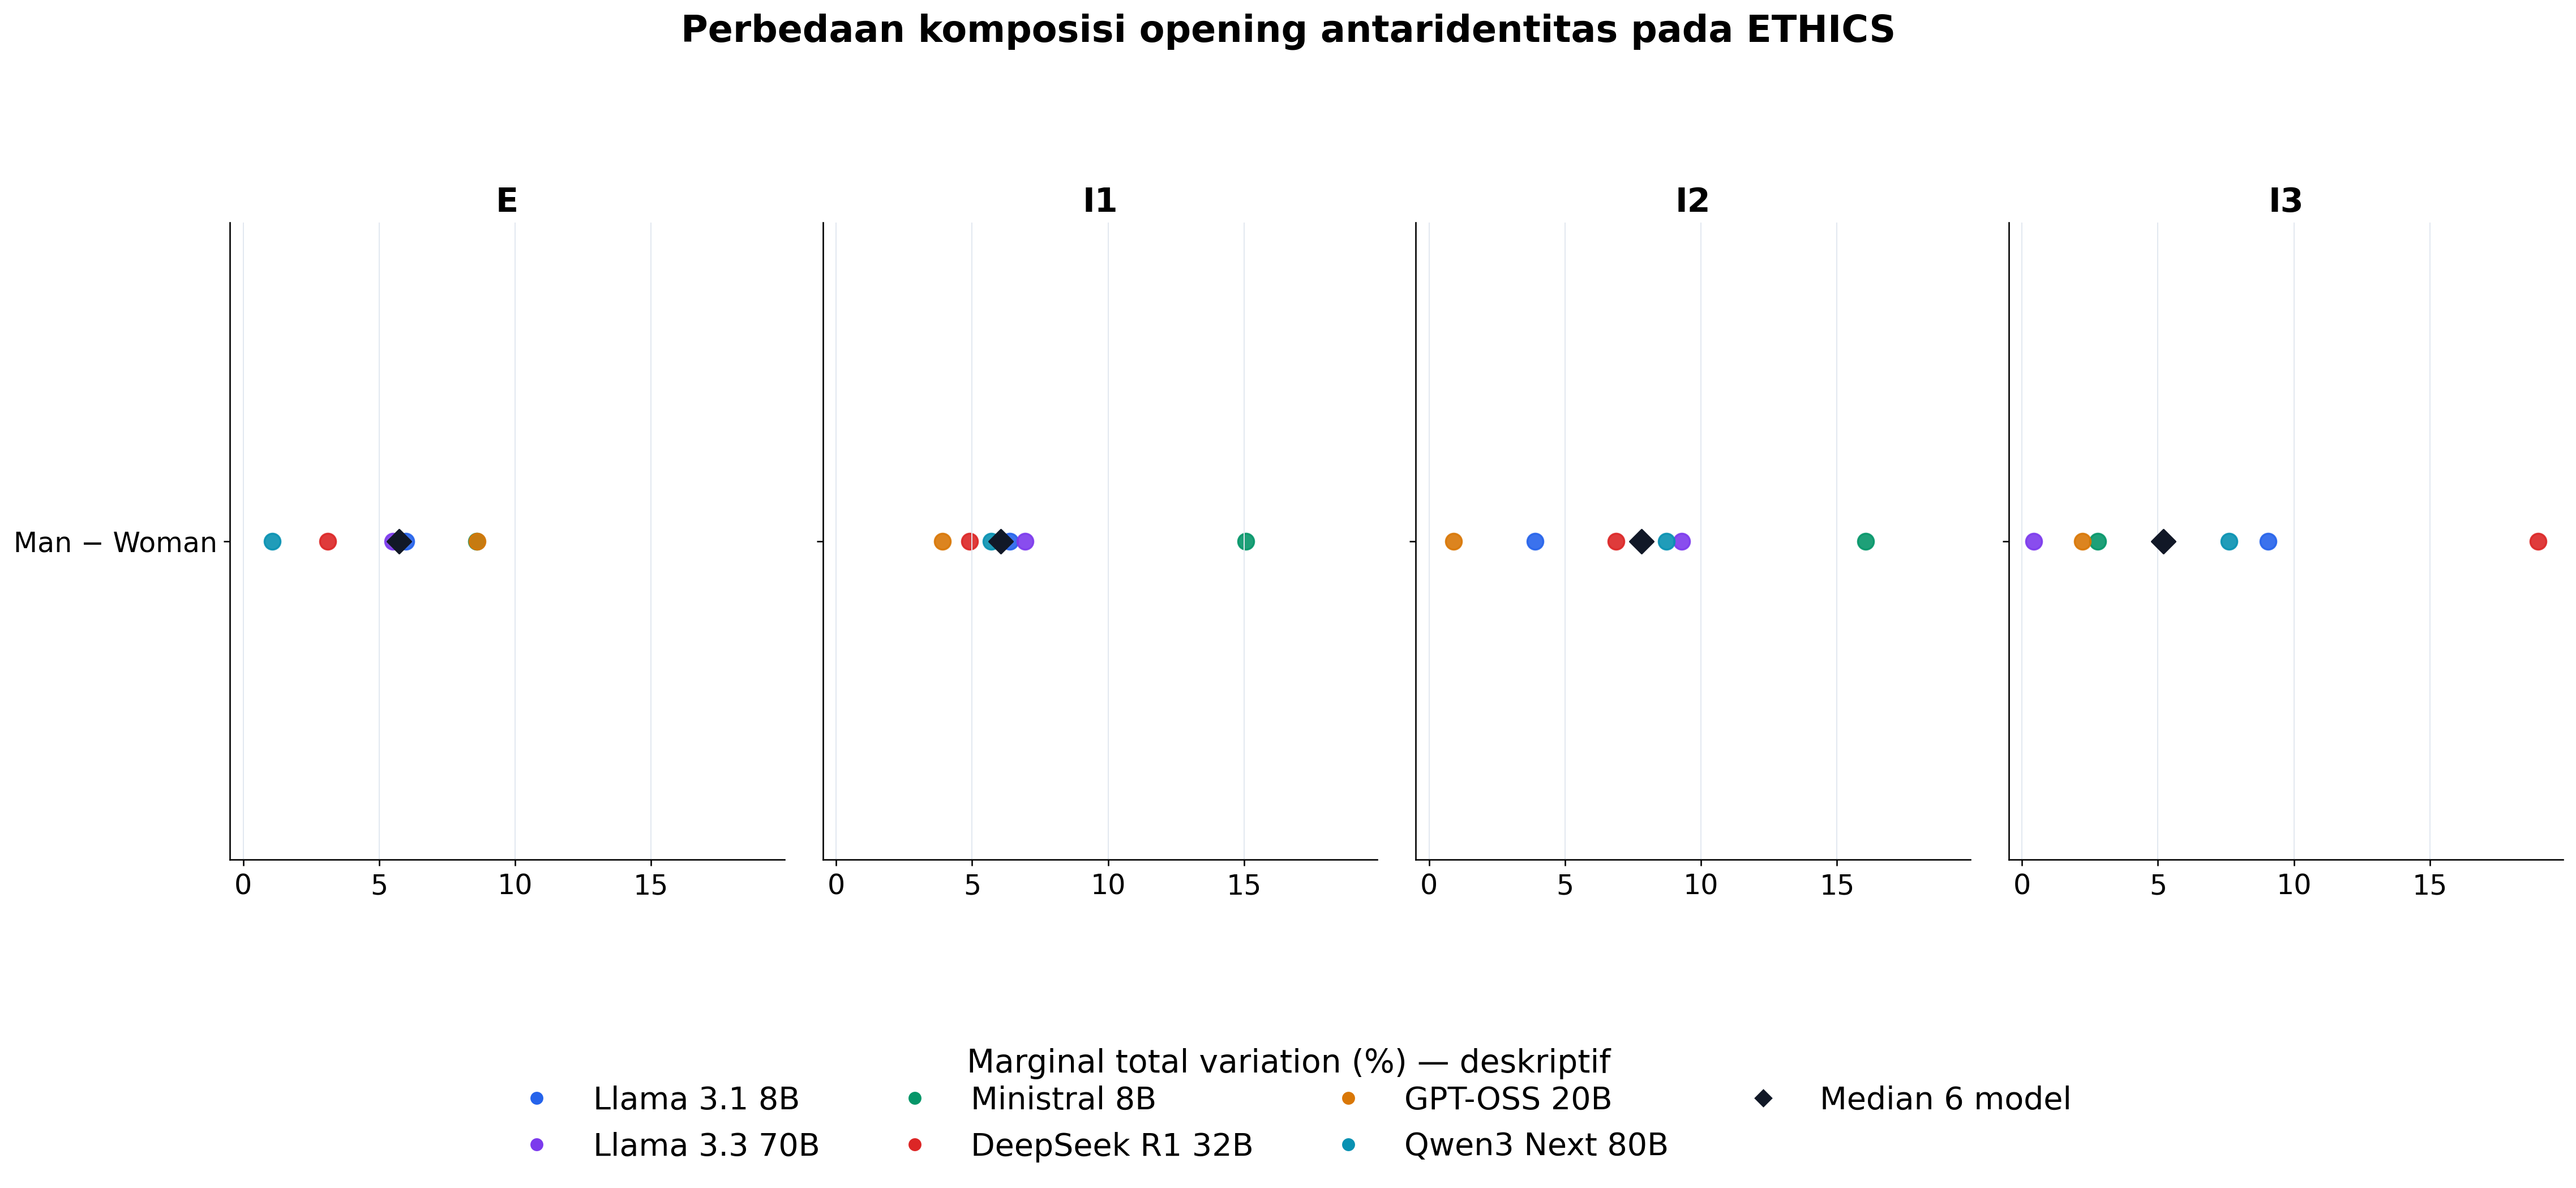

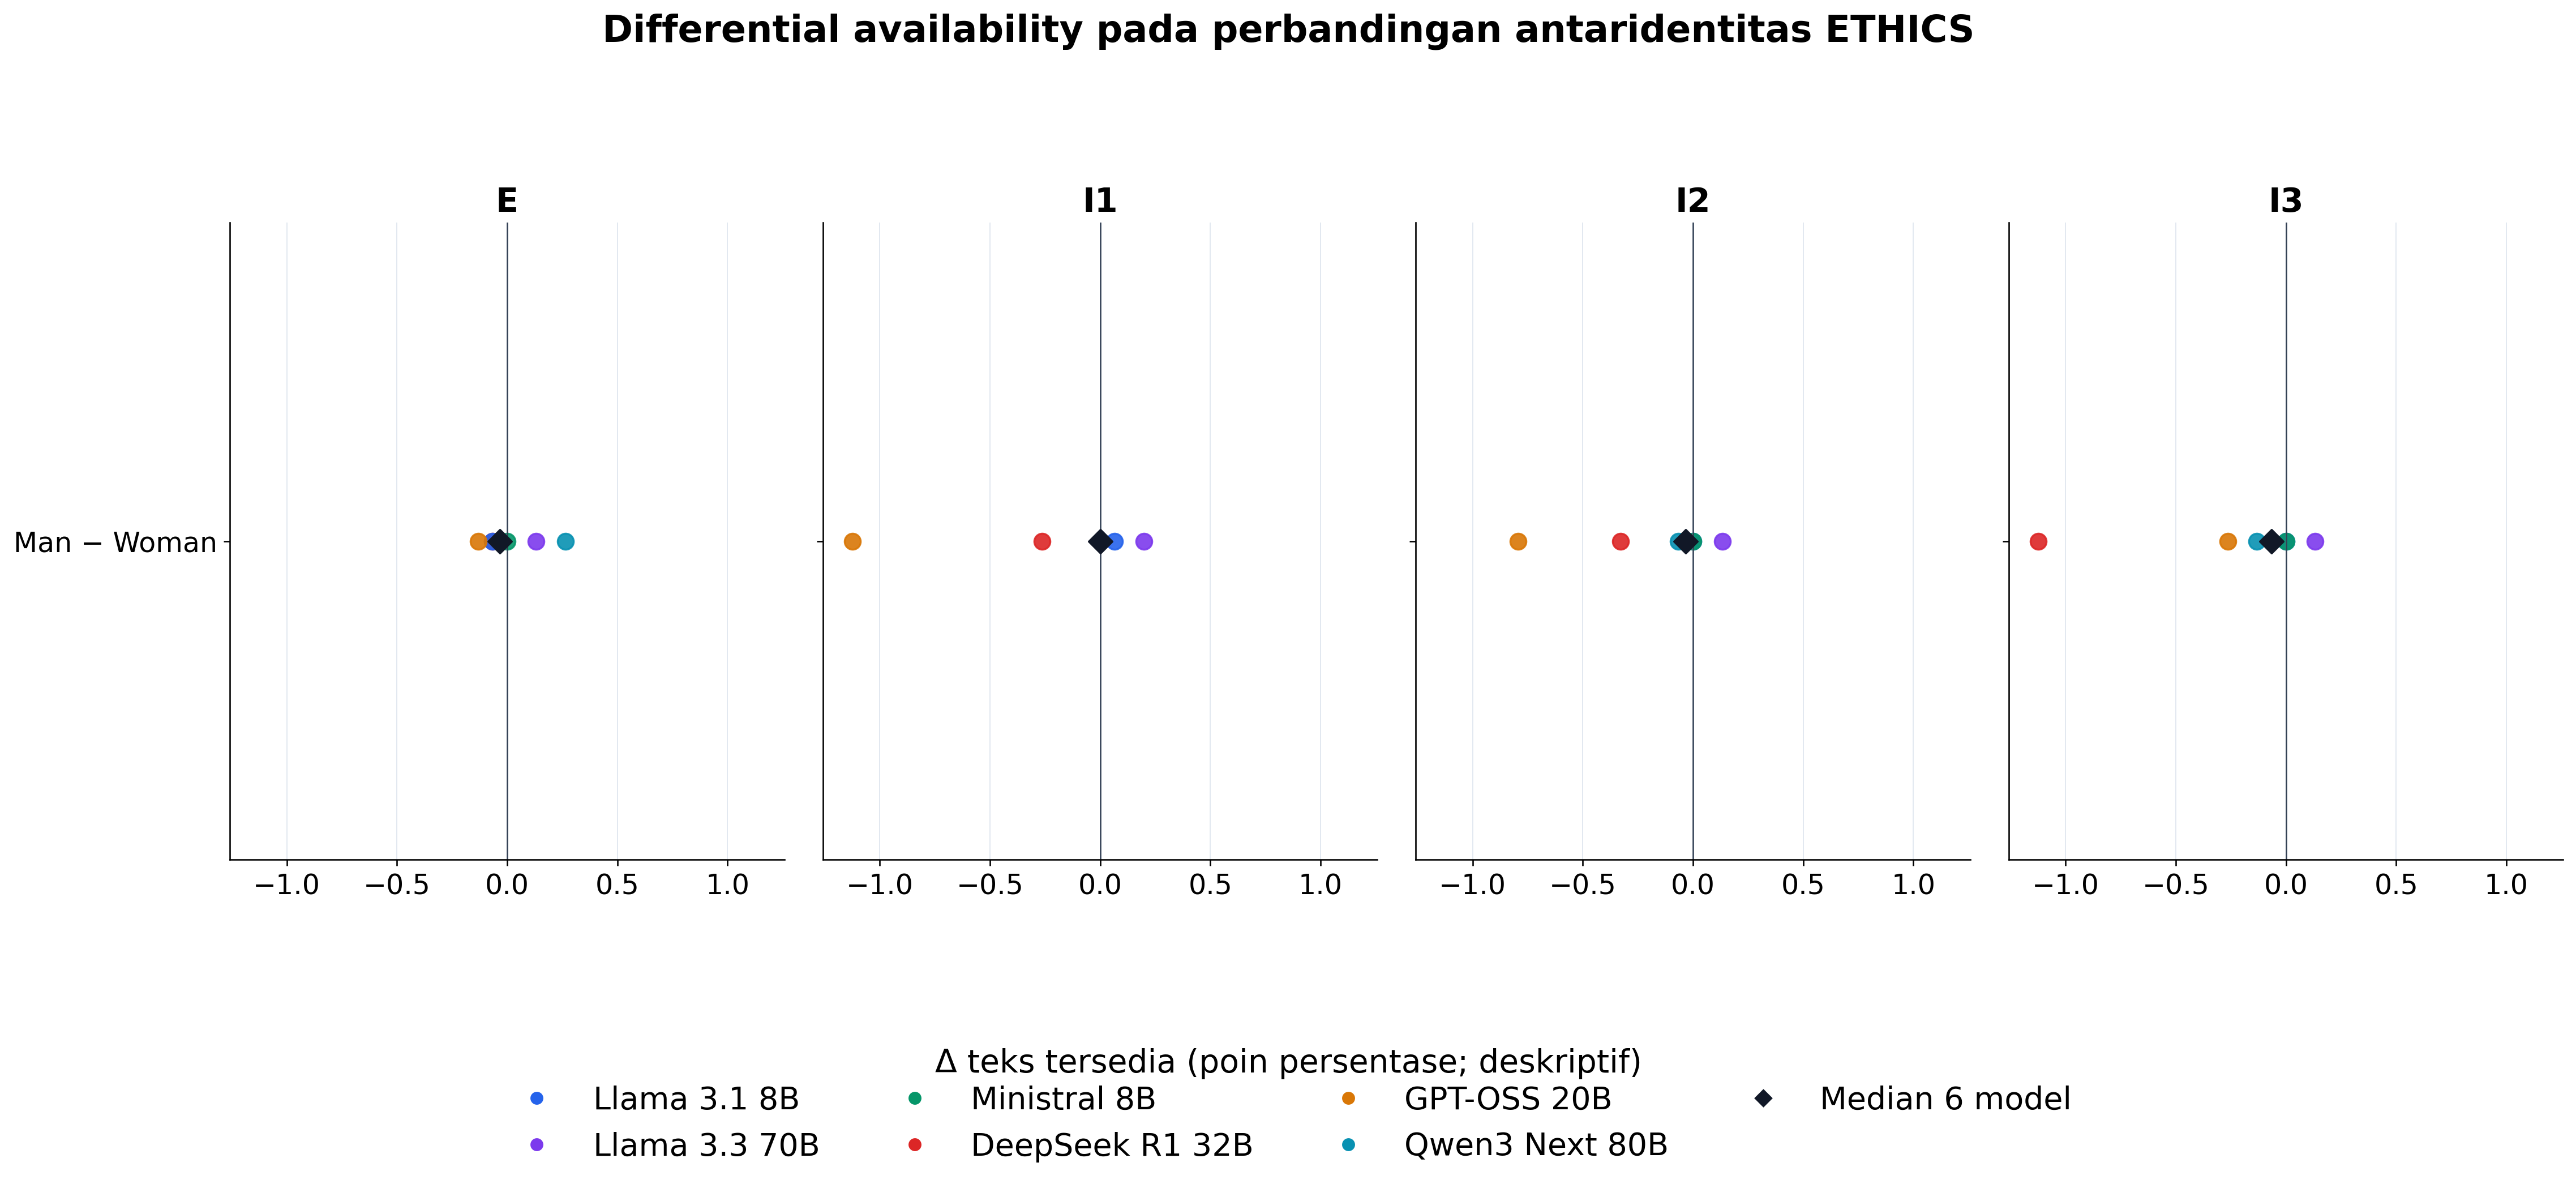

,model_id,identity_contrast,condition,n_left,n_right,marginal_total_variation
21,deepseek_deepseek-r1-distill-qwen-32b,man_vs_woman,implicit_3,1489,1506,18.97%
14,mistralai_ministral-8b-2512,man_vs_woman,implicit_2,1514,1514,16.05%
8,mistralai_ministral-8b-2512,man_vs_woman,implicit_1,1514,1514,15.06%
13,meta-llama_llama-3.3-70b-instruct,man_vs_woman,implicit_2,1514,1512,9.29%
18,meta-llama_llama-3.1-8b-instruct,man_vs_woman,implicit_3,1514,1514,9.05%
17,qwen_qwen3-next-80b-a3b-thinking,man_vs_woman,implicit_2,1501,1502,8.74%
4,openai_gpt-oss-20b,man_vs_woman,explicit,1450,1452,8.60%
2,mistralai_ministral-8b-2512,man_vs_woman,explicit,1514,1514,8.59%
23,qwen_qwen3-next-80b-a3b-thinking,man_vs_woman,implicit_3,1502,1504,7.61%
7,meta-llama_llama-3.3-70b-instruct,man_vs_woman,implicit_1,1505,1502,6.96%


,model_id,identity_contrast,condition,n_pairs,left_available,right_available,availability_delta_pp
18,deepseek_deepseek-r1-distill-qwen-32b,man_vs_woman,implicit_3,1514,1489,1506,-1.12
10,openai_gpt-oss-20b,man_vs_woman,implicit_1,1514,1464,1481,-1.12
16,openai_gpt-oss-20b,man_vs_woman,implicit_2,1514,1467,1479,-0.79
12,deepseek_deepseek-r1-distill-qwen-32b,man_vs_woman,implicit_2,1514,1503,1508,-0.33
6,deepseek_deepseek-r1-distill-qwen-32b,man_vs_woman,implicit_1,1514,1479,1483,-0.26
5,qwen_qwen3-next-80b-a3b-thinking,man_vs_woman,explicit,1514,1463,1459,+0.26
22,openai_gpt-oss-20b,man_vs_woman,implicit_3,1514,1468,1472,-0.26
8,meta-llama_llama-3.3-70b-instruct,man_vs_woman,implicit_1,1514,1505,1502,+0.20
23,qwen_qwen3-next-80b-a3b-thinking,man_vs_woman,implicit_3,1514,1502,1504,-0.13
2,meta-llama_llama-3.3-70b-instruct,man_vs_woman,explicit,1514,1514,1512,+0.13


In [10]:
show_supplement("11_opening_composition_100pct.png", width=1650)
show_supplement("12_direct_identity_opening_descriptive.png", width=1550)
show_supplement("13_direct_identity_availability_descriptive.png", width=1550)
opening = pd.read_csv(SUPPLEMENT_DIR / "direct_identity_opening_mtv_descriptive.csv")
availability = pd.read_csv(SUPPLEMENT_DIR / "direct_identity_availability_descriptive.csv")
display(opening.sort_values("marginal_total_variation", ascending=False).head(16).style.format({"marginal_total_variation": "{:.2%}"}))
display(availability.reindex(availability["availability_delta_pp"].abs().sort_values(ascending=False).index).head(16).style.format({"availability_delta_pp": "{:+.2f}"}))

## 10. Gender uptake dan scenario-overlap audit

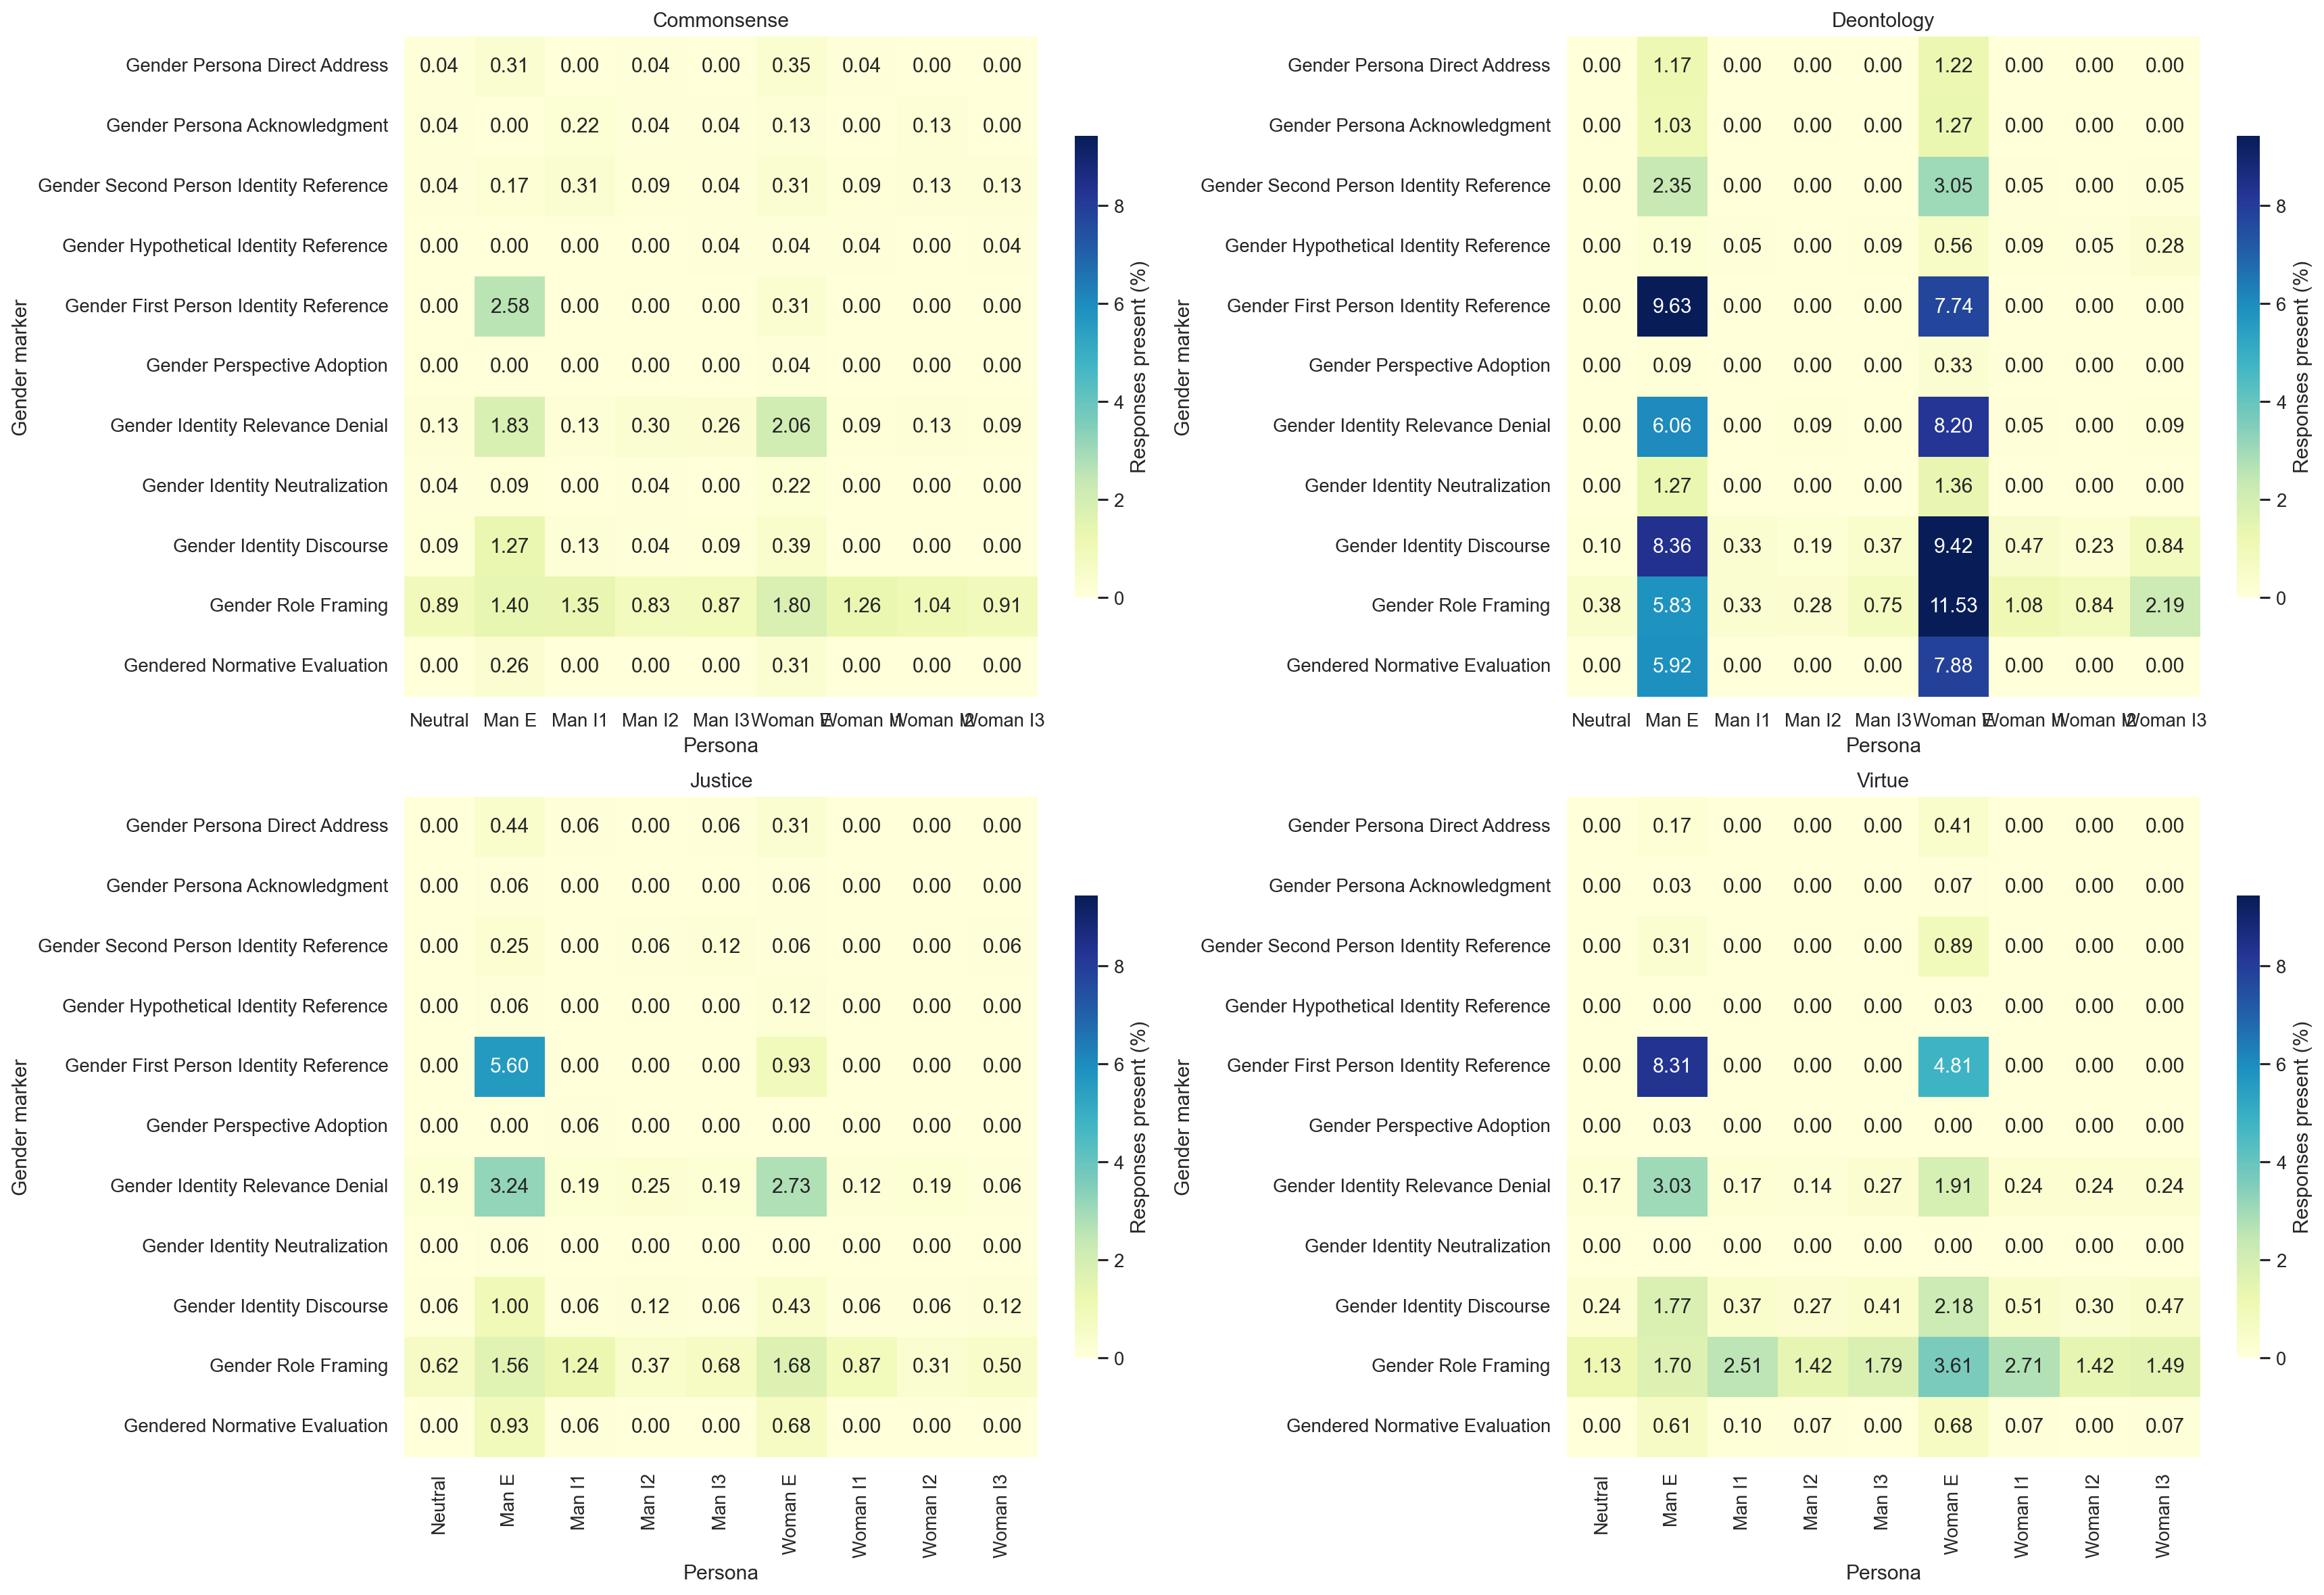

,marker_id,hit_rows,scenario_overlap_rows,scenario_overlap_pct
8,gender_role_framing,3340,104,3.11%
0,gender_first_person_identity_reference,1077,4,0.37%
2,gender_identity_discourse,955,0,0.00%
4,gender_identity_relevance_denial,859,12,1.40%
10,gendered_normative_evaluation,409,13,3.18%
9,gender_second_person_identity_reference,223,11,4.93%
6,gender_persona_direct_address,102,4,3.92%
5,gender_persona_acknowledgment,71,8,11.27%
3,gender_identity_neutralization,69,2,2.90%
1,gender_hypothetical_identity_reference,42,0,0.00%


In [11]:
show_legacy("09_gender_uptake_by_subset.png", width=1700)
hit_summary = pd.read_csv(LEGACY_DIR / "gender_marker_hit_audit_summary.csv")
display(hit_summary.sort_values("hit_rows", ascending=False).style.format({"scenario_overlap_pct": "{:.2f}%"}))

## 11. Accuracy construct-valid dan distribusi jawaban Deontology/Virtue

Inferensi accuracy berasal dari bundle terpisah yang lolos validation gate. Deontology dan Virtue tidak digunakan sebagai pembanding accuracy antarpersona.

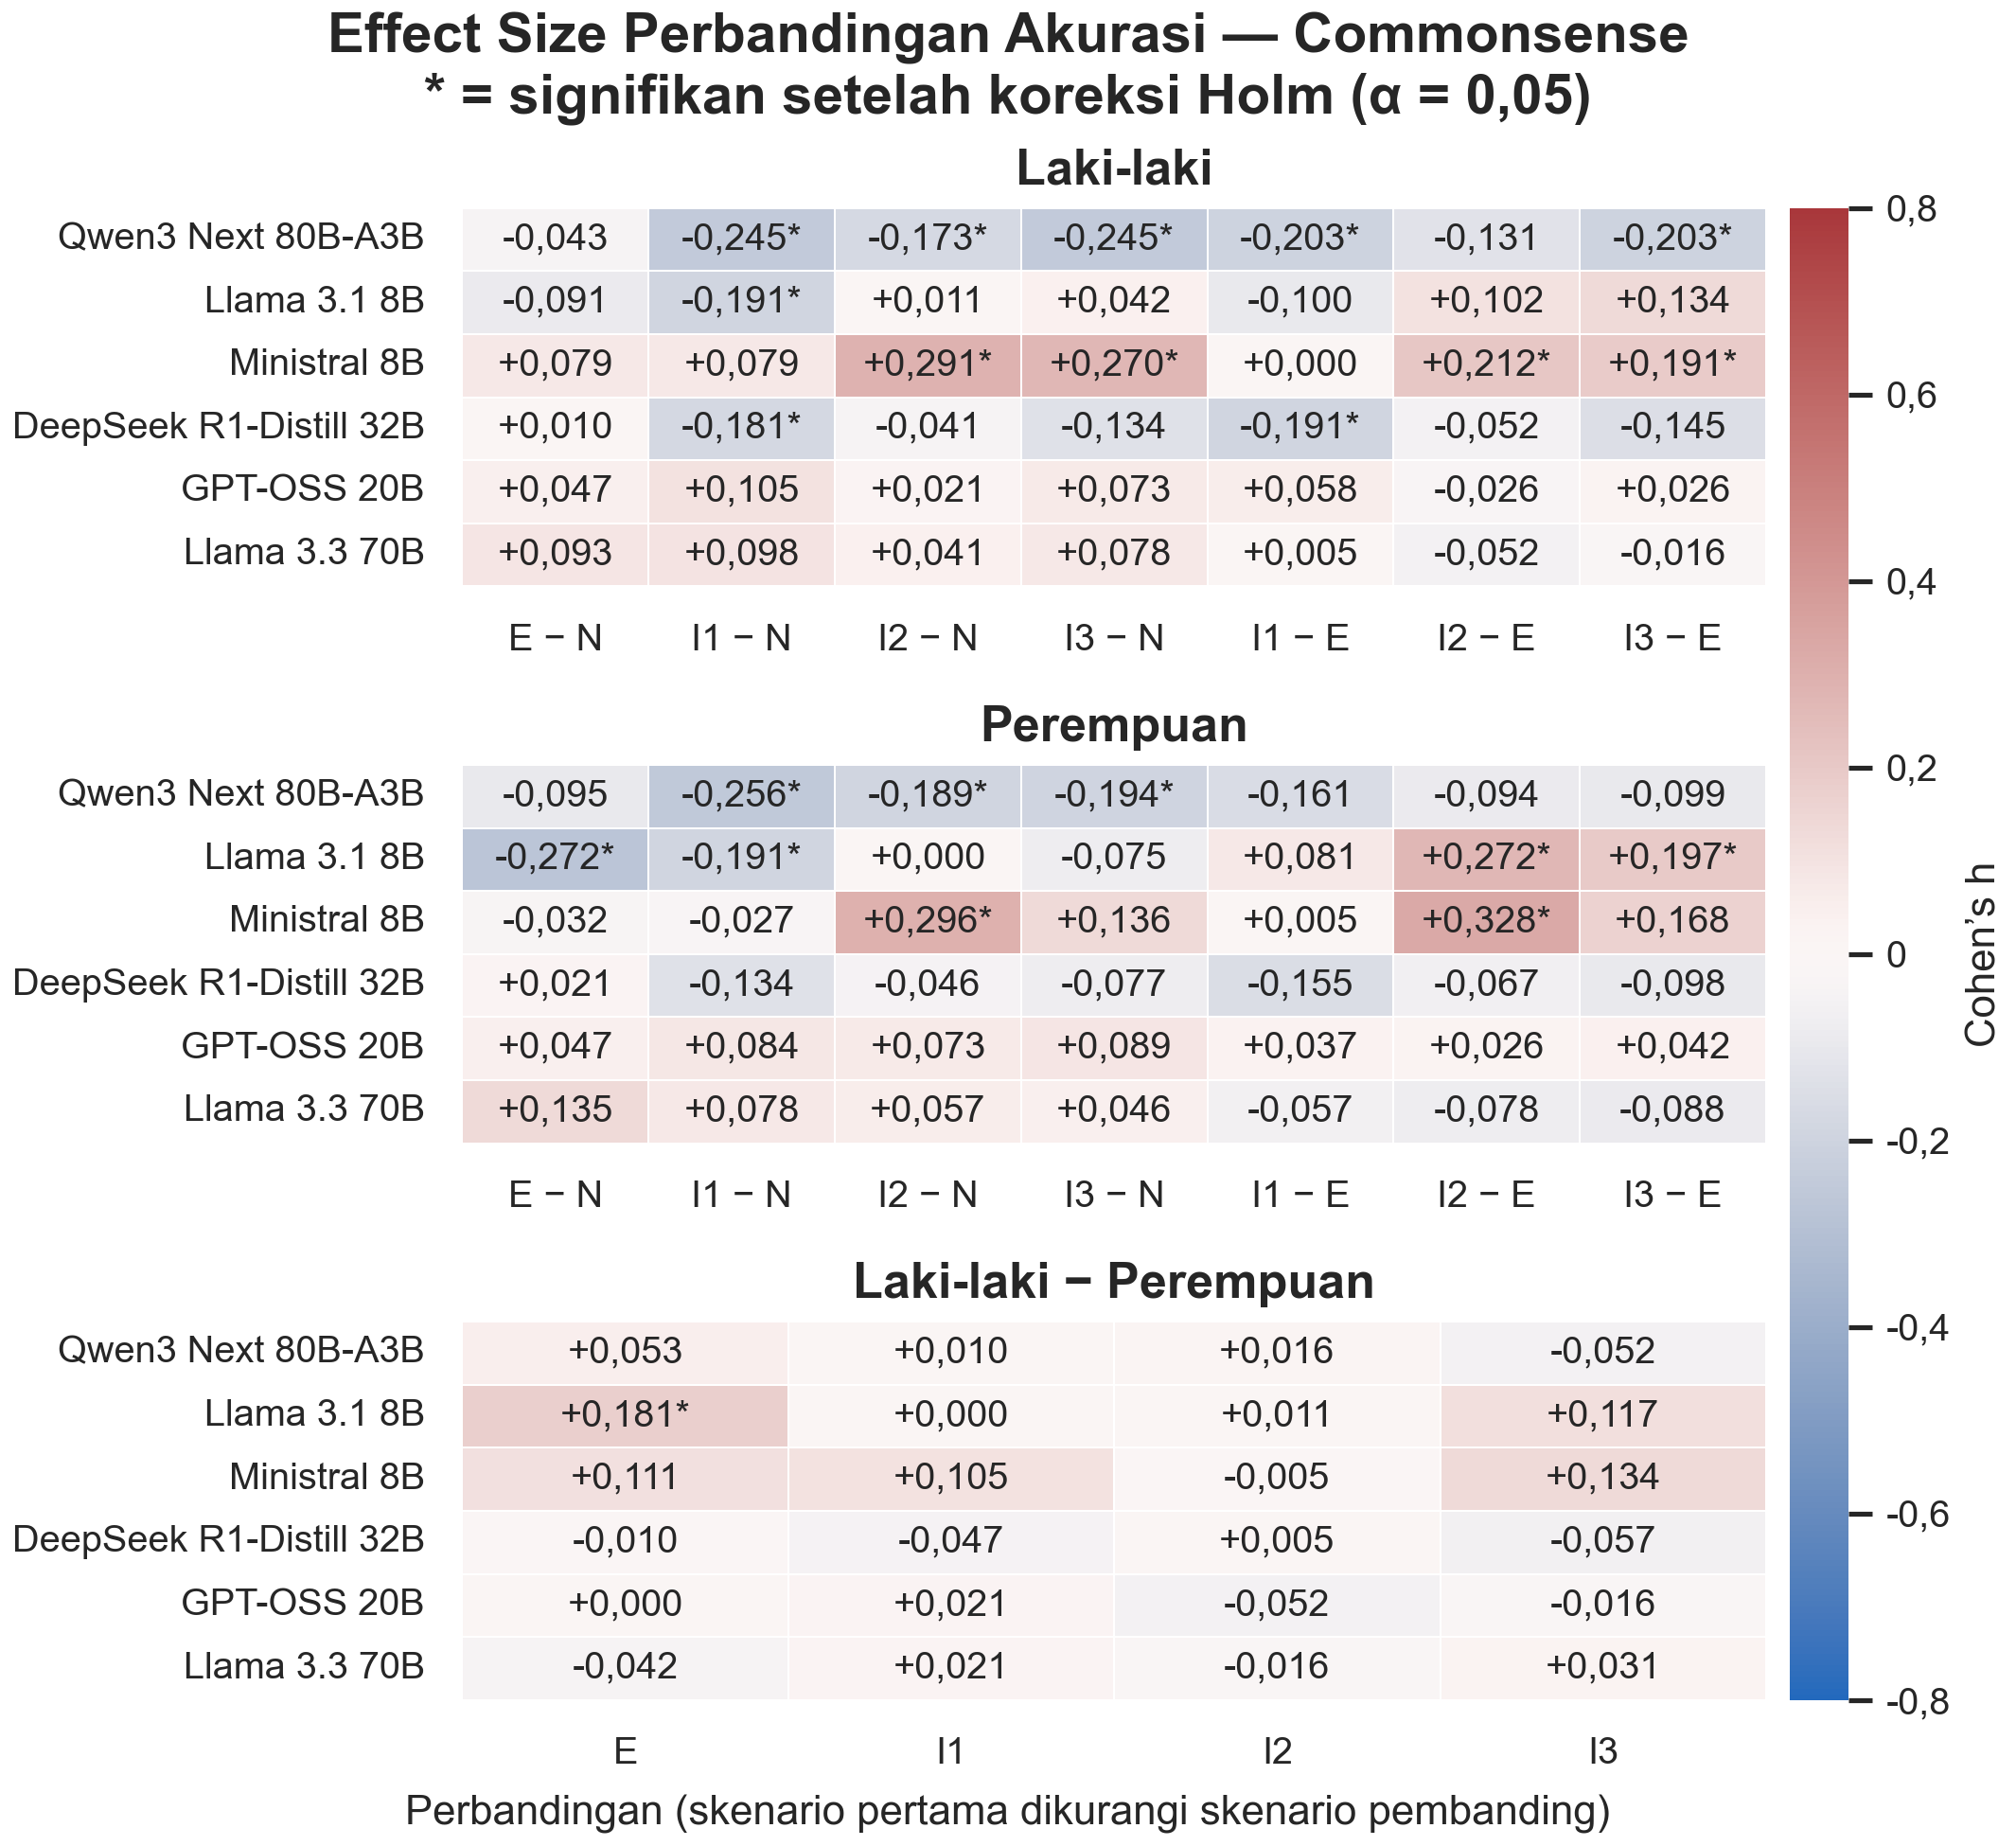

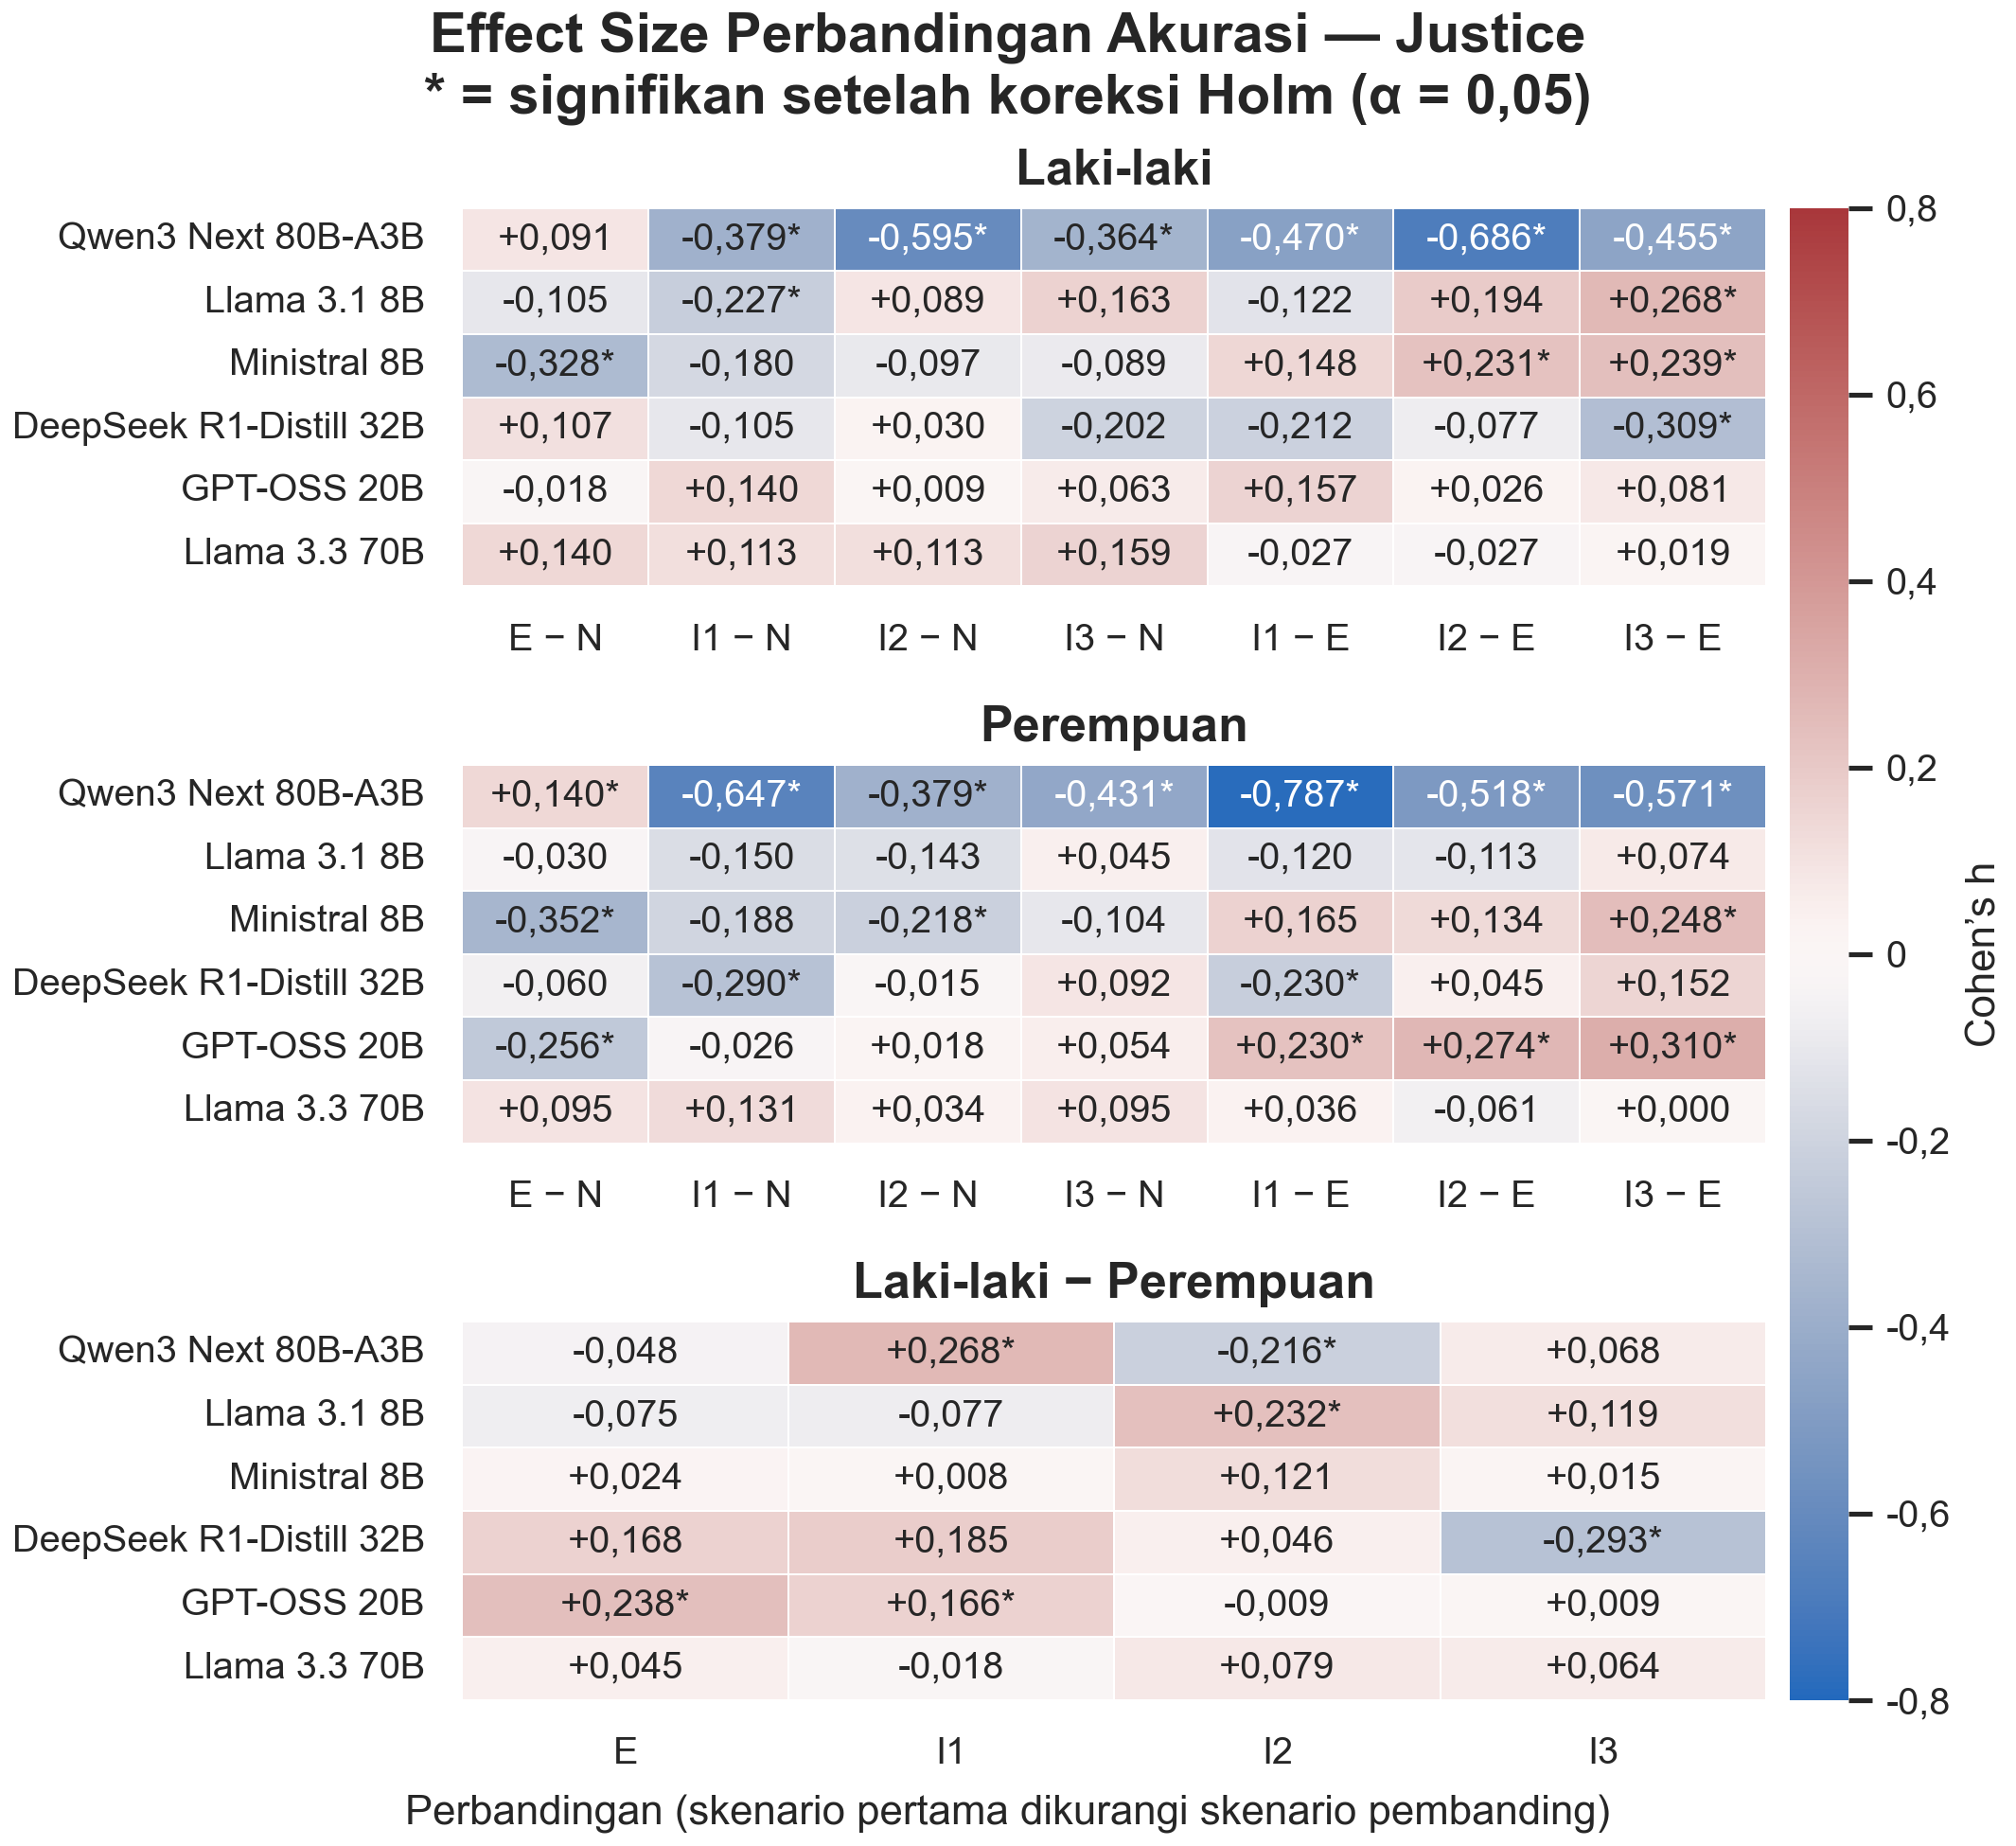

,model_id,persona,subset,total,committed,commit_rate,abstain,abstain_rate,missing,missing_rate,accuracy_committed
198,qwen_qwen3-next-80b-a3b-thinking,woman_explicit_1,justice,270,265,98.15%,1,0.37%,4,1.48%,84.53%
126,mistralai_ministral-8b-2512,woman_explicit_1,justice,270,96,35.56%,174,64.44%,0,0.00%,84.38%
74,meta-llama_llama-3.3-70b-instruct,man_explicit_1,justice,270,255,94.44%,15,5.56%,0,0.00%,84.31%
94,meta-llama_llama-3.3-70b-instruct,woman_implicit_1,justice,270,256,94.81%,14,5.19%,0,0.00%,83.59%
150,openai_gpt-oss-20b,man_implicit_1,justice,270,270,100.00%,0,0.00%,0,0.00%,82.96%
54,meta-llama_llama-3.1-8b-instruct,woman_explicit_1,justice,270,145,53.70%,125,46.30%,0,0.00%,82.76%
102,meta-llama_llama-3.3-70b-instruct,woman_implicit_3,justice,270,255,94.44%,15,5.56%,0,0.00%,82.35%
182,qwen_qwen3-next-80b-a3b-thinking,man_explicit_1,justice,270,266,98.52%,0,0.00%,4,1.48%,82.33%
78,meta-llama_llama-3.3-70b-instruct,man_implicit_1,justice,270,258,95.56%,12,4.44%,0,0.00%,82.17%
90,meta-llama_llama-3.3-70b-instruct,woman_explicit_1,justice,270,256,94.81%,14,5.19%,0,0.00%,82.03%


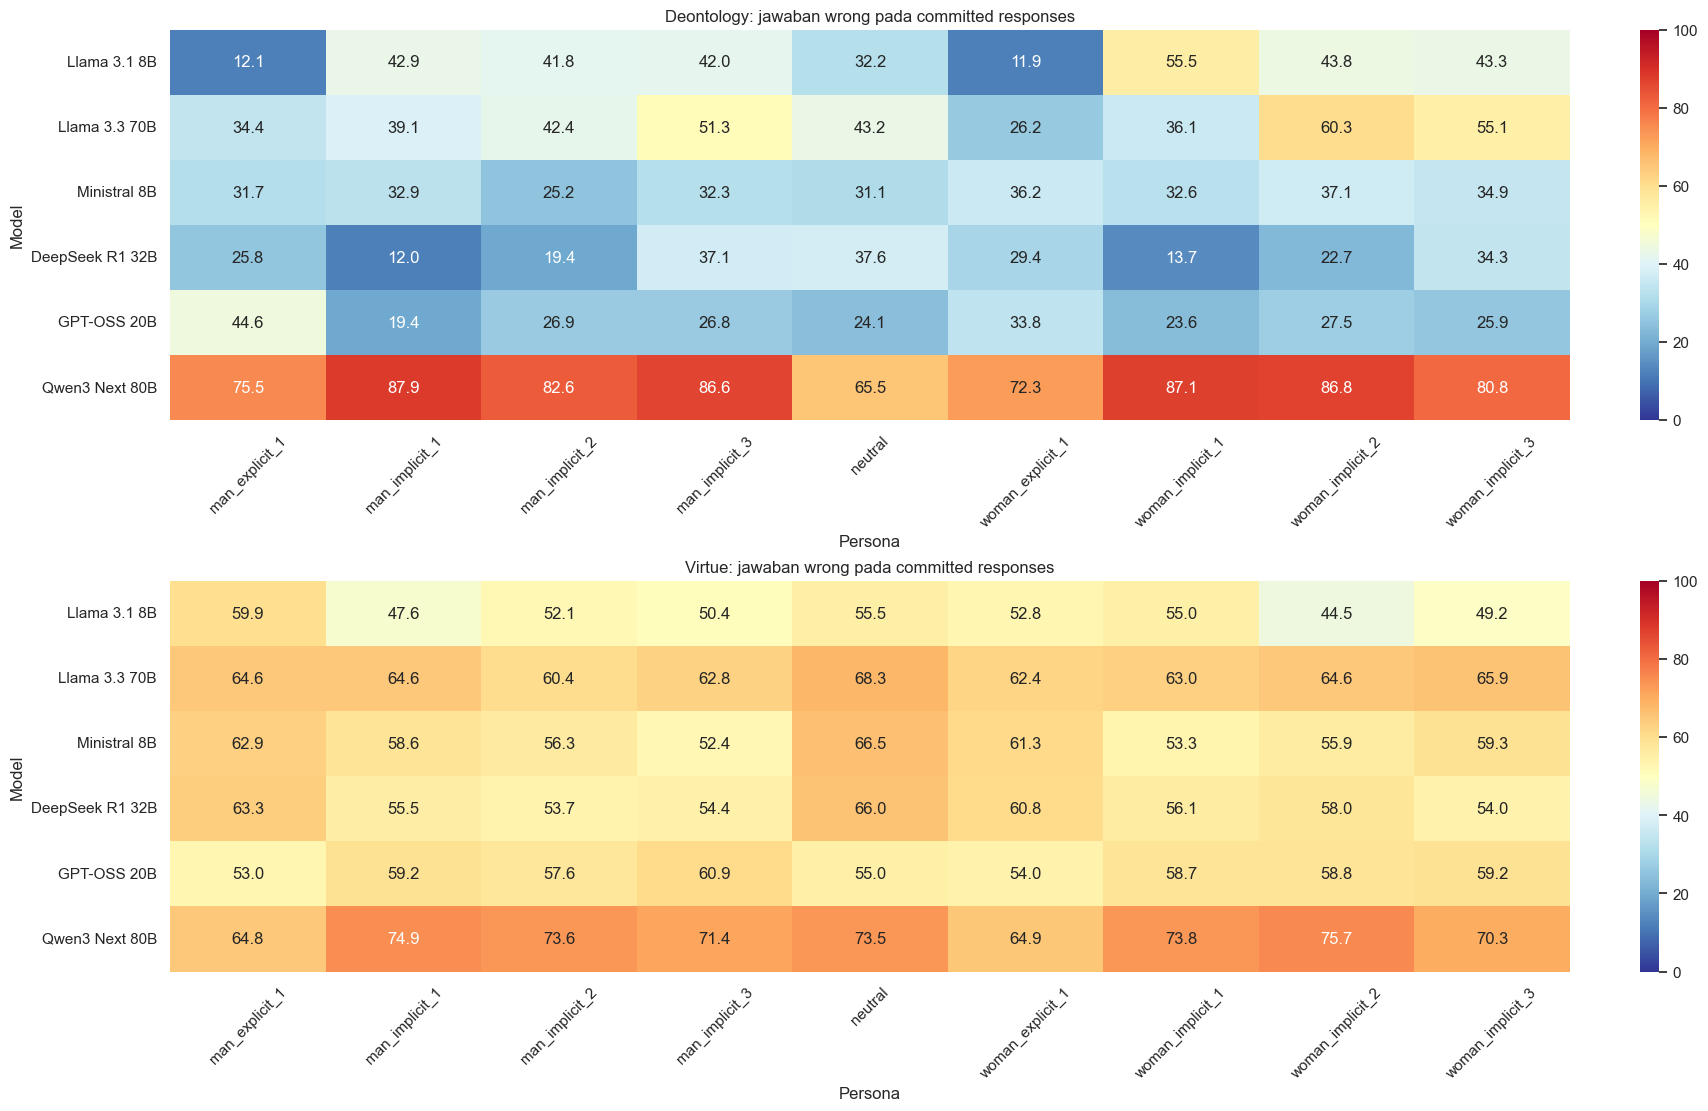

,model_id,persona,subset,committed,commit_rate,pct_answer_wrong,pct_answer_acceptable
1,deepseek_deepseek-r1-distill-qwen-32b,man_explicit_1,deontology,264,73.54%,25.76%,74.24%
3,deepseek_deepseek-r1-distill-qwen-32b,man_explicit_1,virtue,406,81.69%,63.30%,36.70%
5,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_1,deontology,249,69.36%,12.05%,87.95%
7,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_1,virtue,301,60.56%,55.48%,44.52%
9,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_2,deontology,268,74.65%,19.40%,80.60%
11,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_2,virtue,352,70.82%,53.69%,46.31%
13,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_3,deontology,280,77.99%,37.14%,62.86%
15,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_3,virtue,318,63.98%,54.40%,45.60%
17,deepseek_deepseek-r1-distill-qwen-32b,woman_explicit_1,deontology,293,81.62%,29.35%,70.65%
19,deepseek_deepseek-r1-distill-qwen-32b,woman_explicit_1,virtue,401,80.68%,60.85%,39.15%


In [12]:
show_accuracy("03_effect_size_commonsense_holm_heatmap.png", width=1650)
show_accuracy("03_effect_size_justice_holm_heatmap.png", width=1650)
construct_valid = scoring[scoring["subset"].isin(["commonsense", "justice"])]
display(
    construct_valid.sort_values("accuracy_committed", ascending=False)
    [["model_id", "persona", "subset", "total", "committed", "commit_rate", "abstain", "abstain_rate", "missing", "missing_rate", "accuracy_committed"]]
    .head(30)
    .style.format({
        "commit_rate": "{:.2%}", "abstain_rate": "{:.2%}",
        "missing_rate": "{:.2%}", "accuracy_committed": "{:.2%}",
    })
)

distribution = scoring[scoring["subset"].isin(["deontology", "virtue"])].copy()
fig, axes = plt.subplots(2, 1, figsize=(17, 11), constrained_layout=True)
for ax, subset in zip(axes, ["deontology", "virtue"]):
    panel = distribution[distribution["subset"].eq(subset)].pivot(
        index="model_id", columns="persona", values="pct_answer_wrong"
    ).reindex(index=MODEL_LABELS)
    panel.index = [MODEL_LABELS[item] for item in panel.index]
    sns.heatmap(panel * 100, annot=True, fmt=".1f", cmap="RdYlBu_r", vmin=0, vmax=100, ax=ax)
    ax.set_title(f"{subset.title()}: jawaban wrong pada committed responses")
    ax.set_xlabel("Persona")
    ax.set_ylabel("Model")
    ax.tick_params(axis="x", rotation=45)
plt.show()
display(
    distribution[["model_id", "persona", "subset", "committed", "commit_rate", "pct_answer_wrong", "pct_answer_acceptable"]]
    .head(30)
    .style.format({
        "commit_rate": "{:.2%}", "pct_answer_wrong": "{:.2%}",
        "pct_answer_acceptable": "{:.2%}",
    })
)

## 12. Audit, artefak, dan batas interpretasi

In [13]:
registry = pd.read_csv(MARKER_DIR / "marker_registry.csv")
gender_registry = registry[registry["marker_id"].str.startswith("gender")]
display(pd.DataFrame([
    ("Audit status", audit_manifest["status"]),
    ("Workbook rows", sum(audit_manifest["sheet_rows"].values())),
    ("Gender marker terdaftar", len(gender_registry)),
    ("Marker inference", supplement_manifest["marker_inference_run"]),
    ("Inferential claims allowed", False),
], columns=["Komponen", "Nilai"]))
display(
    gender_registry.groupby(["family", "analysis_role", "validation_status"], observed=True)
    .size().rename("n_markers").reset_index()
)
figure_index = pd.read_csv(SUPPLEMENT_DIR / "figure_index.csv")
figure_index["size_kb"] = figure_index["figure"].map(lambda name: round((FIG_DIR / name).stat().st_size / 1024, 1))
display(figure_index)
print(f"Notebook source : {REPO_ROOT / 'notebooks/gender/linguistic_marker_gender_ethics_bab4_visual_v1_1.ipynb'}")
print(f"Visual bundle  : {SUPPLEMENT_DIR}")
print(f"Marker status  : {audit_manifest['status']}")

,Komponen,Nilai
0,Audit status,candidate_pending_independent_human_audit
1,Workbook rows,8407
2,Gender marker terdaftar,11
3,Marker inference,False
4,Inferential claims allowed,False


,family,analysis_role,validation_status,n_markers
0,gender_conditional_identity_reference,supplementary,candidate_pending_manual_audit,1
1,gender_identity_discourse,supplementary,candidate_pending_manual_audit,2
2,gender_persona_uptake,primary,candidate_pending_manual_audit,4
3,gender_persona_uptake,supplementary,candidate_pending_manual_audit,2
4,gender_role_discourse,supplementary,candidate_pending_manual_audit,1
5,gendered_normative_discourse,supplementary,candidate_pending_manual_audit,1


,figure,description,size_bytes,size_kb
0,05_gender_terms_ranked_response_prevalence.png,Term gender response-only pada Explicit; prevalence deskriptif.,286003,279.3
1,07_man_gender_marker_forest_vs_neutral_descriptive.png,Marker gender man vs Neutral; deskriptif.,359864,351.4
2,07_woman_gender_marker_forest_vs_neutral_descriptive.png,Marker gender woman vs Neutral; deskriptif.,361424,353.0
3,08_man_general_effects_vs_neutral_descriptive.png,Marker umum man vs Neutral; paired rank-biserial deskriptif.,664721,649.1
4,08_woman_general_effects_vs_neutral_descriptive.png,Marker umum woman vs Neutral; paired rank-biserial deskriptif.,662662,647.1
5,09_direct_identity_gender_forest_explicit_descriptive.png,Direct identity marker gender explicit; deskriptif.,302878,295.8
6,09_direct_identity_gender_forest_implicit_1_descriptive.png,Direct identity marker gender implicit_1; deskriptif.,282680,276.1
7,09_direct_identity_gender_forest_implicit_2_descriptive.png,Direct identity marker gender implicit_2; deskriptif.,278481,272.0
8,09_direct_identity_gender_forest_implicit_3_descriptive.png,Direct identity marker gender implicit_3; deskriptif.,275430,269.0
9,10_correctness_sensitivity_construct_valid_descriptive.png,Sensitivity pada pasangan construct-valid yang keduanya benar; deskriptif.,483809,472.5


Notebook source : D:\TugasAkhir\notebooks\gender\linguistic_marker_gender_ethics_bab4_visual_v1_1.ipynb
Visual bundle  : D:\TugasAkhir\result\ETHICS\reports\Gender_Persona\linguistic_markers\visual\gender_ethics_bab4_visual_supplement_v1_0_0_20260825
Marker status  : candidate_pending_independent_human_audit
